<a href="https://colab.research.google.com/github/Fugant1/AGORA/blob/main/ser_grpo_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MELD SER GRPO v3 — Hybrid Cue-Split RLVR on Qwen2.5-Omni-7B (Thinker)

Pipeline: saved `ser_sft.ipynb` V4 adapter (`Qwen2_5OmniThinkerForConditionalGeneration`) + disjoint balanced **`grpo_train.csv`** (420 clips, 30 per `emotion × effective_gender`) → **1-epoch GRPO (`G=8`, `beta=0.0`, `loss_type="hybrid"`, `USE_SPLIT_ADVANTAGE=True`, `USE_SPLIT_R2=True`)** → post-training greedy validation on the entire cleaned official MELD **dev → val** manifest (`816` clips) + combined model health report.

Key alignment with `ser_sft.ipynb` (V4):
- **Exact student prompt & schema**: identical `PERSONA`, `gender_context`, `student_instruction(row)` (conditioned per-clip on `effective_gender`), strict SFT parser, and 4 ordinal cues (`speaking_rate`, `pitch_level`, `vocal_energy`, `timbre`).
- **Precomputed immutable labels**: `speaking_rate` backed by global WhisperX syllable-rate quartiles (`whisperx_syllable_rate_cue`); `pitch_level`, `vocal_energy`, and `timbre` backed by gender-relative openSMILE eGeMAPSv02 quartiles. Zero acoustic refitting, zero raw-audio fallback, zero six-speaker restriction.
- **GRPO v2 rewards & hybrid cue-split credit assignment**:
  - `R1`: Dynamic `USE_INVERSE_FREQUENCY=True` emotion reward on balanced `grpo_train.csv` (uniform $p_c = 1/7 \Rightarrow 1.0$ on hit, $0.0$ on miss; identical `z(R1)` advantages to MAP) with standard GRPO `z`-score normalization so sparse minority-emotion breakthroughs keep strong leverage over shared LoRA weights.
  - `R2`: Parameter-free `USE_INVERSE_FREQUENCY=True` (`USE_DISTANCE_BASED_PAYOFF=False`) across all 4 ordinal cues (`1 / (3 * p_y)` on hit, `0.0` on miss/invalid), mean-centered without std under `loss_type="hybrid"` to directly optimize Macro-Recall (UAR) without the invalid-competitor loophole. (Set `USE_DISTANCE_BASED_PAYOFF=True` for the ordinal distance ablation.)
  - `R3`: Structured XML/inventory/reasoning/emotion format reward (`valid_slots / 4.0`).
  - `Hybrid`: `loss_type="hybrid"` with `USE_SPLIT_ADVANTAGE=True`, `USE_SPLIT_R2=True` (mean-centered per-cue `w2/4` with `L/n` cue-value length compensation on cue value tokens; standardized `w1*R1 + w3*R3` on reasoning + answer; `w3*z(R3)` on inventory structure).
  - **Stabilized batch/LR & fast loss**: `PER_DEVICE_TRAIN_BATCH_SIZE=2`, `GRADIENT_ACCUMULATION_STEPS=16`, `STEPS_PER_GENERATION=8` (`4` unique audios / 32 completions per optimizer step with generation batch `16 = 2 audios × 8` → 105 exact steps for 1 epoch over 420 clips), `MAX_COMPLETION_LENGTH=256` (`EVAL_MAX_NEW_TOKENS=512`), `LEARNING_RATE=1e-5`, cosine decay + 5 warmup steps, `BETA=0.0` (skipping redundant `sft_reference` forward pass in `compute_loss`).
- **Mid-train telemetry & post-train evaluation**: live mid-train rewards, running macro-F1, prediction entropy, emotion distribution, per-cue zero-advantage & mapping rates, per-span KL against frozen `sft_reference`, `grpo_groups.jsonl`, `adapter_updates.jsonl`, plus post-training SFT-compatible metrics (`after_validation_*`, gender gap, weighted/macro F1) and `model_health_report.md`.

## 1. Environment and persistent paths

Run in a CUDA training runtime. Install the optional dependencies and restart if needed.
Colab mounts Drive, stages `meld_16k_mono_clean.tar` locally into `/content/agora_work`,
loads the exact V4 split (`grpo_train.csv`) and V4 SFT LoRA adapter from Drive, and saves
GRPO checkpoints, logs, final adapter, and evaluation reports back to Drive.

In [1]:
# Optional fresh-runtime setup:
%pip install -q --no-cache-dir "transformers==5.20.2" "trl==1.15.0" peft accelerate bitsandbytes datasets soundfile pandas scipy scikit-learn matplotlib seaborn tqdm

In [2]:
from pathlib import Path
from collections import Counter
import functools
import hashlib
import json
import math
import os
import re
import tarfile
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import soundfile as sf
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
try:
    from IPython.display import display
except ImportError:
    display = print
from tqdm.auto import tqdm

IS_COLAB = Path('/content').exists()
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/AGORA_SER') if IS_COLAB else Path.cwd()
DRIVE_DATA_DIR = PROJECT_DIR / 'data/meld_16k_mono'
DATA_DIR = Path('/content/agora_work/meld_16k_mono') if IS_COLAB else DRIVE_DATA_DIR
CLEAN_DIR = DATA_DIR / 'emo_tag_clean'
TRAIN_CSV = CLEAN_DIR / 'clean_train_set_with_cues.csv'
VAL_CSV = CLEAN_DIR / 'clean_val_set_with_cues.csv'
QUARTILES_JSON = CLEAN_DIR / 'gender_acoustic_quartiles.json'

# Matches ser_sft.ipynb V4 split & SFT checkpoint paths exactly
SPLIT_DIR = PROJECT_DIR / 'data/sft_grpo_gender_wxrate_60_40_v4'
SFT_CSV = SPLIT_DIR / 'sft_train.csv'
GRPO_CSV = SPLIT_DIR / 'grpo_train.csv'
SPLIT_META = SPLIT_DIR / 'split_manifest.json'

SFT_RUN_NAME = 'full_sft_gender_wxrate_unweighted_seed42_v4'
SFT_ADAPTER_PATH = PROJECT_DIR / 'runs/ser_sft' / SFT_RUN_NAME / 'final_sft_adapter'

RUN_NAME = 'grpo_v3_hybrid_invfreq_4cue_seed42_v4_noR2'
OUTPUT_DIR = PROJECT_DIR / 'runs/ser_grpo' / RUN_NAME
FINAL_ADAPTER_DIR = OUTPUT_DIR / 'final_grpo_adapter'
RESUME_CHECKPOINT_DIR: Optional[str] = None  # Set to checkpoint path to resume an interrupted run

MODEL_ID = 'Qwen/Qwen2.5-Omni-7B'
USE_SFT_MODEL = True
SEED = 42

# 1 full epoch over all 420 grpo_train rows at G=8:
# - PER_DEVICE_TRAIN_BATCH_SIZE=2, STEPS_PER_GENERATION=8 -> 16 completions/gen (2 audios x 8).
# - GRADIENT_ACCUMULATION_STEPS=16 -> 32 completions (4 unique audios) per optimizer step -> 105 exact steps.
# - MAX_COMPLETION_LENGTH=256 eliminates tail stalls during rollout sampling; EVAL_MAX_NEW_TOKENS=512 for validation.
NUM_TRAIN_EPOCHS = 1
PER_DEVICE_TRAIN_BATCH_SIZE = 2
STEPS_PER_GENERATION = 8
GRADIENT_ACCUMULATION_STEPS = 16
NUM_GENERATIONS = 8
TEMPERATURE = 1.0
LEARNING_RATE = 1e-5
WARMUP_STEPS = 5
LR_SCHEDULER_TYPE = 'cosine'
MAX_GRAD_NORM = 1.0
BETA = 0.0
MAX_COMPLETION_LENGTH = 256
EVAL_MAX_NEW_TOKENS = 512
EVAL_BATCH_SIZE = 16
SAVE_STEPS = 25
SAVE_TOTAL_LIMIT = 6
LOGGING_STEPS = 5

# Exact schema & prompt version from ser_sft.ipynb V4
PROMPT_VERSION = 'gender_wxrate_4cue_srfirst_teacher_v5_short_concise'
CUES = ('speaking_rate', 'pitch_level', 'vocal_energy', 'timbre')
CUE_COLUMNS = {
    'speaking_rate': 'whisperx_syllable_rate_cue',
    'pitch_level': 'pitch_level_cue',
    'vocal_energy': 'vocal_energy_cue',
    'timbre': 'timbre_cue',
}
GLOBAL_CUES = frozenset({'speaking_rate'})
EMOTIONS = ('anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise')
VALID_EMOTIONS = set(EMOTIONS)
VALID_EMOTIONS_LIST = list(EMOTIONS)
CUE_LABELS = {cue: ('low', 'moderate', 'high') for cue in CUES}
CUE_LABELS['timbre'] = ('low (muffled/soft)', 'moderate (modal)', 'high (tense/bright)')

Mounted at /content/drive


## 2. Load cleaned audio and verified disjoint GRPO / validation manifests

Stages the EMO-TAG cleaned audio archive locally on Colab (matching `ser_sft.ipynb`),
loads the immutable `grpo_train.csv` split created by `ser_sft.ipynb` and the official
cleaned MELD `clean_val_set_with_cues.csv` validation manifest, and verifies zero audio overlap
with both `sft_train.csv` and `val_set`. No acoustic quartiles are refit here.

In [3]:
def stage_clean_data(drive_dir, local_dir):
    """Persist a missing archive on Drive, then transfer/extract a local working copy."""
    import shutil
    drive_dir, local_dir = Path(drive_dir), Path(local_dir)
    if local_dir.resolve().is_relative_to(drive_dir.resolve()):
        raise ValueError('Local working directory must be outside Drive data storage')
    metadata = ('clean_train_set_with_cues.csv', 'clean_val_set_with_cues.csv',
                'gender_acoustic_quartiles.json')
    archive = drive_dir / 'meld_16k_mono_clean.tar'
    clean_source = drive_dir / 'emo_tag_clean'
    if not archive.is_file():
        for name in metadata:
            if not (clean_source / name).is_file():
                raise FileNotFoundError(f'Missing Drive preprocessing export: {clean_source / name}')
        for split in ('train', 'val'):
            frame = pd.read_csv(clean_source / f'clean_{split}_set_with_cues.csv')
            if frame.empty:
                raise ValueError(f'Cannot archive an empty {split} manifest')
            for path in frame.audio_path:
                resolve_audio_path(path, split, drive_dir)
        print(f'Creating permanent clean archive on Drive: {archive}', flush=True)
        partial = archive.with_suffix('.tar.partial')
        try:
            with tarfile.open(partial, 'w') as bundle:
                bundle.add(clean_source, arcname='meld_16k_mono/emo_tag_clean')
            partial.replace(archive)
        finally:
            partial.unlink(missing_ok=True)

    local_dir.mkdir(parents=True, exist_ok=True)
    local_archive = local_dir.parent / archive.name
    print(f'Copying Drive archive to local runtime: {local_archive}', flush=True)
    partial = local_archive.with_suffix('.tar.partial')
    try:
        shutil.copyfile(archive, partial)
        partial.replace(local_archive)
    finally:
        partial.unlink(missing_ok=True)

    print(f'Extracting cleaned audio locally: {local_dir}', flush=True)
    restored = 0
    extracted_audio = set()
    with tarfile.open(local_archive, 'r:') as bundle:
        for member in bundle:
            parts = Path(member.name).parts
            if (not member.isfile() or '..' in parts or len(parts) not in (3, 4)
                    or parts[:2] != ('meld_16k_mono', 'emo_tag_clean')):
                continue
            is_audio = len(parts) == 4 and parts[2] in ('train', 'val', 'test') and Path(parts[3]).suffix == '.wav'
            is_metadata = len(parts) == 3 and Path(parts[2]).suffix in ('.csv', '.json')
            if not (is_audio or is_metadata):
                continue
            target = local_dir.joinpath(*parts[1:])
            if not target.resolve().is_relative_to(local_dir.resolve()):
                raise ValueError(f'Archive target escapes local working directory: {target}')
            target.parent.mkdir(parents=True, exist_ok=True)
            partial = target.with_suffix(target.suffix + '.partial')
            try:
                with bundle.extractfile(member) as source, partial.open('wb') as destination:
                    shutil.copyfileobj(source, destination)
                partial.replace(target)
            finally:
                partial.unlink(missing_ok=True)
            if is_audio:
                extracted_audio.add(str(target.resolve()))
            restored += 1
    for name in metadata:
        source = clean_source / name
        target = local_dir / 'emo_tag_clean' / name
        if source.is_file():
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, target)
        if not target.is_file():
            raise FileNotFoundError(f'Missing metadata in Drive export/archive: {name}')
    for split in ('train', 'val'):
        frame = pd.read_csv(local_dir / 'emo_tag_clean' / f'clean_{split}_set_with_cues.csv')
        for path in frame.audio_path:
            resolved = resolve_audio_path(path, split, local_dir)
            if resolved not in extracted_audio:
                raise ValueError(f'Archive is missing a manifest audio; refresh the Drive archive: {resolved}')
    print(f'Staged {restored:,} files. Training audio root: {local_dir}')


def resolve_audio_path(value, split, data_dir):
    if pd.isna(value):
        raise ValueError('Missing audio_path')
    path = Path(str(value))
    parts = path.parts
    if 'emo_tag_clean' in parts:
        relative = Path(*parts[parts.index('emo_tag_clean') + 1:])
    elif not path.is_absolute():
        relative = path
    else:
        raise ValueError(f'Expected a cleaned audio path: {path}')
    if not relative.parts or relative.parts[0] != split or '..' in relative.parts:
        raise ValueError(f'Unexpected {split} path: {path}')
    resolved = (data_dir / 'emo_tag_clean' / relative).resolve()
    if not resolved.is_relative_to((data_dir / 'emo_tag_clean' / split).resolve()):
        raise ValueError(f'Audio escapes split directory: {path}')
    if not resolved.is_file():
        raise FileNotFoundError(resolved)
    return str(resolved)


def load_manifest(csv_path, split, data_dir):
    df = pd.read_csv(csv_path)
    required = {'audio_path', 'effective_gender', 'gender', 'emotion', 'text',
                'speaker', 'duration', 'dialogue', 'utterance'} | {CUE_COLUMNS[cue] for cue in CUES}
    if required - set(df):
        raise ValueError(f'{csv_path}: missing columns {required - set(df)}')
    if df.empty:
        raise ValueError(f'{csv_path}: empty split')
    if not df.effective_gender.isin(['F', 'M', '__GLOBAL__']).all():
        raise ValueError(f'{csv_path}: missing or invalid effective_gender; rerun preprocessing')
    df['audio_path'] = df.audio_path.map(lambda p: resolve_audio_path(p, split, data_dir))
    if df.audio_path.duplicated().any():
        raise ValueError(f'{csv_path}: duplicate audio')
    for cue in CUES:
        labels = df[CUE_COLUMNS[cue]]
        unknown = set(labels.dropna()) - set(CUE_LABELS[cue])
        if unknown:
            raise ValueError(f'{csv_path}: unknown {cue} labels {unknown}')
        if split == 'train' and labels.isna().any():
            raise ValueError(f'{csv_path}: missing training labels for {cue}; check preprocessing')
    if not df.emotion.isin(EMOTIONS).all():
        raise ValueError(f'{csv_path}: missing or unknown emotion labels')
    if df[['dialogue', 'utterance']].duplicated().any():
        raise ValueError(f'{csv_path}: duplicate utterance IDs')
    if split == 'train':
        if not df.gender.isin(['F', 'M']).all() or not df.gender.equals(df.effective_gender):
            raise ValueError('Training gender must match preprocessing effective_gender (F/M)')
    return df


def atomic_csv(df, path):
    path = Path(path)
    temporary = path.with_suffix('.csv.partial')
    saved = df.copy()
    if 'audio_path' in saved and DATA_DIR.resolve() != DRIVE_DATA_DIR.resolve():
        saved['audio_path'] = saved.audio_path.map(
            lambda p: str(DRIVE_DATA_DIR / Path(p).relative_to(DATA_DIR.resolve()))
            if Path(p).resolve().is_relative_to(DATA_DIR.resolve()) else str(p)
        )
    saved.to_csv(temporary, index=False)
    temporary.replace(path)


def validate_grpo_partition(grpo_df, val_df, sft_df=None, clean_train_df=None):
    """Fail-closed provenance and zero-leakage checks for the saved GRPO split."""
    if grpo_df.empty or grpo_df.audio_path.duplicated().any():
        raise ValueError('GRPO: empty or duplicate audio')
    if set(grpo_df.audio_path) & set(val_df.audio_path):
        raise ValueError('GRPO/validation audio overlap detected')
    if sft_df is not None and (set(grpo_df.audio_path) & set(sft_df.audio_path)):
        raise ValueError('SFT/GRPO audio overlap detected')
    if clean_train_df is not None:
        source = clean_train_df.set_index('audio_path')
        if not set(grpo_df.audio_path) <= set(source.index):
            raise ValueError('GRPO: audio outside saved clean training source')
        try:
            pd.testing.assert_frame_equal(
                grpo_df[clean_train_df.columns].reset_index(drop=True),
                source.loc[grpo_df.audio_path].reset_index()[clean_train_df.columns],
                check_dtype=False, check_exact=False, rtol=1e-10, atol=1e-10,
            )
        except AssertionError as exc:
            raise ValueError('GRPO: cached metadata/labels differ from preprocessing') from exc
    counts = grpo_df.groupby(['emotion', 'effective_gender']).size().reindex(
        pd.MultiIndex.from_product([EMOTIONS, ('F', 'M')]), fill_value=0
    )
    if counts.min() == 0 or counts.nunique() != 1:
        raise ValueError(f'GRPO: emotion/gender quotas are not balanced: {counts.to_dict()}')
    return counts


def load_audio(path: str) -> np.ndarray:
    audio, sr = sf.read(path, dtype='float32')
    if sr != 16000 or audio.ndim != 1 or not len(audio) or not np.isfinite(audio).all():
        raise ValueError(f'Expected finite, nonempty 16 kHz mono audio: {path}')
    return audio

In [4]:
if IS_COLAB:
    stage_clean_data(DRIVE_DATA_DIR, DATA_DIR)

for required_path in (TRAIN_CSV, VAL_CSV, QUARTILES_JSON, GRPO_CSV, SPLIT_META):
    if not required_path.is_file():
        raise FileNotFoundError(f'Required preprocessing/split file not found: {required_path}')

clean_train_set = load_manifest(TRAIN_CSV, 'train', DATA_DIR)
grpo_train_set = load_manifest(GRPO_CSV, 'train', DATA_DIR)
val_set = load_manifest(VAL_CSV, 'val', DATA_DIR)
sft_train_check = load_manifest(SFT_CSV, 'train', DATA_DIR) if SFT_CSV.is_file() else None
split_manifest = json.loads(SPLIT_META.read_text(encoding='utf-8'))
quartiles = json.loads(QUARTILES_JSON.read_text(encoding='utf-8'))

if split_manifest.get('identity', {}).get('prompt_version') != PROMPT_VERSION:
    print(f"Note: split_manifest prompt_version={split_manifest.get('identity', {}).get('prompt_version')!r}, "
          f"active PROMPT_VERSION={PROMPT_VERSION!r}")

grpo_strata = validate_grpo_partition(grpo_train_set, val_set, sft_df=sft_train_check, clean_train_df=clean_train_set)
print(f'GRPO train: {len(grpo_train_set):,} rows ({int(grpo_strata.iloc[0])} per emotion x gender); '
      f'official cleaned MELD val: {len(val_set):,} rows')
display(pd.crosstab(grpo_train_set.emotion, grpo_train_set.effective_gender))

Copying Drive archive to local runtime: /content/agora_work/meld_16k_mono_clean.tar
Extracting cleaned audio locally: /content/agora_work/meld_16k_mono
Staged 8,808 files. Training audio root: /content/agora_work/meld_16k_mono
GRPO train: 420 rows (30 per emotion x gender); official cleaned MELD val: 816 rows


effective_gender,F,M
emotion,,
anger,30,30
disgust,30,30
fear,30,30
joy,30,30
neutral,30,30
sadness,30,30
surprise,30,30


## 3. Exact SFT V4 student prompt and strict parser

Matches `ser_sft.ipynb` V4 **character-for-character** so GRPO rollouts and validation use
the exact prompt distribution the SFT LoRA adapter was trained on. Parsing is strict (exact
single `<answer>` tag, exact single `[Acoustic Inventory]...[Prosodic Reasoning]` block,
exact canonical `EMOTIONS` and `CUE_LABELS[cue]` with zero synonym fallback) so SFT and GRPO
validation metrics are directly comparable.

In [5]:
PERSONA = 'You analyze speech acoustics and emotion. Follow the requested output format.'


def gender_context(row):
    groups = {'F': 'F (female)', 'M': 'M (male)',
              '__GLOBAL__': '__GLOBAL__ (pooled reference; gender unresolved)'}
    return f"Acoustic reference group (effective speaker gender): {groups[row['effective_gender']]}."


def inventory_text(row):
    return '\n'.join(f"- {cue}: {row[CUE_COLUMNS[cue]]}" for cue in CUES)


def student_instruction(row):
    options = '\n'.join(f"- {cue}: {' | '.join(CUE_LABELS[cue])}" for cue in CUES)
    return (gender_context(row) + '\nListen to the audio and identify its emotion. '
            'Classify each acoustic cue relative to the supplied reference group. '
            'Then reason concisely from the audible cues to determine the speakers emotion.'
            f"Allowed emotions: {', '.join(EMOTIONS)}.\n"
            'Output exactly:\n<think>\n[Acoustic Inventory]\n' + options +
            '\n[Prosodic Reasoning]\nYour concise reasoning.\n</think>\n<answer>emotion</answer>')


def messages_for(row):
    return [{'role': 'system', 'content': PERSONA},
            {'role': 'user', 'content': [{'type': 'audio', 'audio': row['audio_path']},
                                        {'type': 'text', 'text': student_instruction(row)}]}]


def parse_completion_strict(text: str) -> Tuple[str, Dict[str, str]]:
    """Exact ser_sft.ipynb strict parser returning (emotion, {cue: label_or_invalid})."""
    if not isinstance(text, str):
        text = str(text) if text is not None else ''
    answers = re.findall(r'<answer>\s*(.*?)\s*</answer>', text, flags=re.DOTALL | re.IGNORECASE)
    emotion = answers[0].strip().lower() if len(answers) == 1 else 'invalid'
    emotion = emotion if emotion in EMOTIONS else 'invalid'
    sections = re.findall(r'\[Acoustic Inventory\](.*?)\[Prosodic Reasoning\]', text, flags=re.DOTALL)
    inventory = {}
    for cue in CUES:
        matches = re.findall(rf'^\s*-\s*{cue}:\s*([^\n]+)', sections[0], flags=re.MULTILINE) if len(sections) == 1 else []
        label = matches[0].strip().lower() if len(matches) == 1 else 'invalid'
        inventory[cue] = label if label in CUE_LABELS[cue] else 'invalid'
    return emotion, inventory


def extract_reasoning(completion: str) -> str:
    match = re.search(
        r'\[Prosodic Reasoning\](.*?)(?:</think>|<answer>|<\||$)',
        completion,
        re.DOTALL | re.IGNORECASE,
    )
    if not match:
        return ''
    reasoning = match.group(1).strip()
    for placeholder in ('Your concise reasoning.', 'Your concise explanation.',
                        '(Deduce the emotion from the cues above)'):
        if reasoning == placeholder:
            return ''
    return reasoning


@functools.lru_cache(maxsize=8192)
def parse_completion(completion: str) -> Dict[str, Any]:
    """Single-pass cached strict parse for GRPO rewards, rollout logging, and evaluation."""
    if not isinstance(completion, str):
        completion = str(completion) if completion is not None else ''

    t_open = completion.find('<think>')
    t_close = completion.find('</think>')
    a_open = completion.find('<answer>')
    a_close = completion.find('</answer>')

    has_think = (t_open != -1 and t_close != -1)
    has_answer = (a_open != -1 and a_close != -1)
    single_tags = (
        completion.count('<think>') == 1
        and completion.count('</think>') == 1
        and len(re.findall(r'<answer>', completion, flags=re.IGNORECASE)) == 1
        and len(re.findall(r'</answer>', completion, flags=re.IGNORECASE)) == 1
    )
    valid_tag_order = (has_think and has_answer and single_tags and t_open < t_close < a_open < a_close)

    emotion, strict_inv = parse_completion_strict(completion)
    inventory = {cue: (None if strict_inv[cue] == 'invalid' else strict_inv[cue]) for cue in CUES}
    valid_slots_count = sum(1 for cue in CUES if inventory[cue] is not None)
    reasoning = extract_reasoning(completion)
    answers = re.findall(r'<answer>\s*(.*?)\s*</answer>', completion, flags=re.DOTALL | re.IGNORECASE)
    answer_raw = answers[0].strip().lower() if len(answers) == 1 else ''
    is_valid_emotion = emotion in VALID_EMOTIONS

    return {
        'raw': completion,
        'has_think': has_think,
        'has_answer': has_answer,
        'valid_tag_order': valid_tag_order,
        'inventory': inventory,
        'strict_inventory': strict_inv,
        'valid_slots_count': valid_slots_count,
        'reasoning': reasoning,
        'answer_raw': answer_raw,
        'answer_norm': emotion,
        'is_valid_emotion': is_valid_emotion,
    }


print('Sample student instruction (F):')
print(student_instruction({'effective_gender': 'F'}))

Sample student instruction (F):
Acoustic reference group (effective speaker gender): F (female).
Listen to the audio and identify its emotion. Classify each acoustic cue relative to the supplied reference group. Then reason concisely from the audible cues to determine the speakers emotion.Allowed emotions: anger, disgust, fear, joy, neutral, sadness, surprise.
Output exactly:
<think>
[Acoustic Inventory]
- speaking_rate: low | moderate | high
- pitch_level: low | moderate | high
- vocal_energy: low | moderate | high
- timbre: low (muffled/soft) | moderate (modal) | high (tense/bright)
[Prosodic Reasoning]
Your concise reasoning.
</think>
<answer>emotion</answer>


# Reward Functions

## Mode flags & strategy defaults
- **R1 (`USE_INVERSE_FREQUENCY = True`)**: Parameter-free inverse-frequency emotion reward calibrated dynamically on `grpo_train_set`. Because `grpo_train.csv` has exact uniform emotion counts (60/class, $p_c = 1/7$), Hit $= 1.0$ and Miss/Invalid $= 0.0$, producing the exact same `z(R1)` standardized advantages as MAP.
- **R2 (`USE_INVERSE_FREQUENCY = True`, `USE_DISTANCE_BASED_PAYOFF = False`)**: Parameter-free target-weighted inverse frequency (`1 / (3 * p_y)` on hit, `0.0` on miss/invalid) across all **4 cues** (`speaking_rate`, `pitch_level`, `vocal_energy`, `timbre`). Under `loss_type="hybrid"` (mean-centered without std), `1 / (3 * p_y)` survives intact: every constant policy has blind expectation $1/3$, minority `low`/`high` targets receive ~2× larger gradients than `moderate`, and all-wrong / invalid groups yield exact zero advantage. (Flip `USE_DISTANCE_BASED_PAYOFF = True` to run the ordinal distance ablation.)
- **R3**: Structured XML/4-slot inventory/reasoning/emotion format reward in $[0, 1]$.
- **Weights**: `REWARD_WEIGHTS = {"r1": 1.0, "r2": 1.0, "r3": 0.2}` (set `"r2": 0.0` for the R1+R3 ablation).

In [6]:
# ==============================================================================
# Reward Mode Flags (Mutually Exclusive: Zero-Mean vs MAP vs Inverse Frequency)
# ==============================================================================
USE_ZERO_MEAN = False
USE_MAP = False
USE_INVERSE_FREQUENCY = True

if (
    not all(isinstance(f, bool) for f in (USE_ZERO_MEAN, USE_MAP, USE_INVERSE_FREQUENCY))
    or sum([bool(USE_ZERO_MEAN), bool(USE_MAP), bool(USE_INVERSE_FREQUENCY)]) != 1
):
    raise ValueError(
        f'Invalid reward configuration: USE_ZERO_MEAN={USE_ZERO_MEAN!r}, '
        f'USE_MAP={USE_MAP!r}, USE_INVERSE_FREQUENCY={USE_INVERSE_FREQUENCY!r}. '
        'Mutually exclusive reward flags: exactly one must be True.'
    )

# R2 override: False = parameter-free Inverse Frequency (default, directly optimizes UAR);
# True = empirical ordinal distance payoffs for all 4 cues (ablation toggle).
# After changing flags, rerun R1/R2 calibration and all downstream reward/evaluation cells.
USE_DISTANCE_BASED_PAYOFF = False
if not isinstance(USE_DISTANCE_BASED_PAYOFF, bool):
    raise ValueError('USE_DISTANCE_BASED_PAYOFF must be a bool.')

## R1 — Empirical Zero-Mean, Prior-Centered MAP, or Inverse-Frequency Emotion Reward

Controlled by `USE_ZERO_MEAN`, `USE_MAP`, and `USE_INVERSE_FREQUENCY`, calibrated strictly from `grpo_train_set`:
- **`USE_ZERO_MEAN = True`**: $H_c = 1 - p_c,\; M_c = -p_c,\; \Delta_c = 1.0$.
- **`USE_MAP = True`**: $H_c = 1 - \bar{p},\; M_c = -\bar{p},\; \Delta_c = 1.0$ with $\bar{p} = \sum_k p_k^2$.
- **`USE_INVERSE_FREQUENCY = True`**: $H_c = \frac{1}{K \cdot p_c}$ on hit and $0.0$ on miss/invalid, computed dynamically from `grpo_train_set`.

In [7]:
# ==============================================================================
# R1 - Empirical Zero-Mean, Prior-Centered MAP, OR Inverse-Frequency Emotion Reward
# ==============================================================================
def resolve_reward_mode(
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> str:
    """Resolve and validate the mutually exclusive reward mode ('zero_mean', 'map', or 'inverse_frequency')."""
    if use_zero_mean is None and use_map is None and use_inverse_frequency is None:
        zm = globals().get('USE_ZERO_MEAN', False)
        mp = globals().get('USE_MAP', False)
        ifreq = globals().get('USE_INVERSE_FREQUENCY', True)
    elif use_zero_mean is not None and use_map is not None:
        zm = use_zero_mean
        mp = use_map
        ifreq = False if use_inverse_frequency is None else use_inverse_frequency
    else:
        raise ValueError(
            'Pass both use_zero_mean and use_map explicitly (with optional use_inverse_frequency), '
            'or omit all flags to use global USE_ZERO_MEAN / USE_MAP / USE_INVERSE_FREQUENCY.'
        )
    if (
        not isinstance(zm, (bool, np.bool_))
        or not isinstance(mp, (bool, np.bool_))
        or not isinstance(ifreq, (bool, np.bool_))
        or sum([bool(zm), bool(mp), bool(ifreq)]) != 1
    ):
        raise ValueError(
            f'Mutually exclusive reward flags violated (USE_ZERO_MEAN={zm!r}, USE_MAP={mp!r}, '
            f'USE_INVERSE_FREQUENCY={ifreq!r}): exactly one must be True.'
        )
    if bool(zm):
        return 'zero_mean'
    if bool(mp):
        return 'map'
    return 'inverse_frequency'


def compute_hit_miss(
    priors: Dict[str, float],
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> Dict[str, Dict[str, Any]]:
    """Compute per-category Hit/Miss payoffs under Zero-Mean, MAP, or Inverse-Frequency mode."""
    mode = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    if len(priors) < 2:
        raise ValueError('Calibration requires at least two observed categories.')

    values = {k: float(v) for k, v in priors.items()}
    invalid = [k for k, v in values.items() if not math.isfinite(v) or v <= 0.0]
    if invalid:
        raise ValueError(f'Cannot calibrate unobserved or invalid categories: {invalid}')
    total = math.fsum(values.values())
    if not math.isfinite(total) or total <= 0.0:
        raise ValueError('Calibration frequencies must have a positive finite sum.')
    probabilities = {k: v / total for k, v in values.items()}
    if any(p >= 1.0 for p in probabilities.values()):
        raise ValueError('Calibration frequencies are numerically degenerate.')

    n_classes = len(probabilities)
    prior_baseline = math.fsum(p * p for p in probabilities.values())
    if not (0.0 < prior_baseline < 1.0):
        raise ArithmeticError(f'Invalid prior squared baseline: {prior_baseline}')
    is_uniform = (max(probabilities.values()) - min(probabilities.values())) <= 1e-12

    raw_payoffs: Dict[str, Dict[str, Any]] = {}
    for k, p in probabilities.items():
        if mode == 'zero_mean':
            hit = 1.0 - p
            miss = -p
        elif mode == 'map':
            hit = 1.0 - prior_baseline
            miss = -prior_baseline
        else:
            hit = 1.0 / (n_classes * p)
            miss = 0.0

        delta = hit - miss
        e_blind = p * hit + (1.0 - p) * miss

        if mode in ('zero_mean', 'map'):
            if abs(delta - 1.0) > 1e-12:
                raise ArithmeticError(f'Unit-contrast slope failed for {k!r}: delta={delta}')
            if not (0.0 < hit <= 1.0 and -1.0 <= miss < 0.0):
                raise ArithmeticError(f'Payoff bounds violated for {k!r}: hit={hit}, miss={miss}')
            if mode == 'zero_mean' and abs(e_blind) > 1e-12:
                raise ArithmeticError(f'Zero-Mean failed for {k!r}: E[blind]={e_blind}')
            if mode == 'map' and abs(e_blind - (p - prior_baseline)) > 1e-12:
                raise ArithmeticError(f'MAP blind expectation failed for {k!r}: {e_blind}')
        else:
            if not (hit > 0.0 and miss == 0.0):
                raise ArithmeticError(f'Inverse-frequency bounds violated for {k!r}: hit={hit}, miss={miss}')
            if abs(e_blind - (1.0 / n_classes)) > 1e-12:
                raise ArithmeticError(f'Inverse-frequency blind expectation failed for {k!r}: {e_blind}')

        raw_payoffs[k] = {
            'mode': mode,
            'prior': p,
            'prior_baseline': prior_baseline,
            'hit': hit,
            'miss': miss,
            'delta': delta,
            'e_blind': e_blind,
            'zero_mean_consistent': abs(e_blind) <= 1e-12,
            'map_consistent': (mode == 'map') or is_uniform,
            'inverse_frequency_consistent': (mode == 'inverse_frequency'),
        }

    e_prior_random = math.fsum(probabilities[k] * raw_payoffs[k]['e_blind'] for k in probabilities)
    if mode in ('zero_mean', 'map'):
        if abs(e_prior_random) > 1e-12:
            raise ArithmeticError(f'Prior-random zero-mean baseline failed: {e_prior_random}')
    else:
        if abs(e_prior_random - (1.0 / n_classes)) > 1e-12:
            raise ArithmeticError(f'Inverse-frequency prior-random baseline failed: {e_prior_random}')
    for info in raw_payoffs.values():
        info['e_prior_random'] = e_prior_random

    if mode == 'map':
        hits = [info['hit'] for info in raw_payoffs.values()]
        misses = [info['miss'] for info in raw_payoffs.values()]
        if (max(hits) - min(hits) > 1e-12) or (max(misses) - min(misses) > 1e-12):
            raise ArithmeticError('MAP mode requires identical Hit and Miss across all categories.')

    return raw_payoffs


def compute_zero_mean_hit_miss(priors: Dict[str, float]) -> Dict[str, Dict[str, Any]]:
    return compute_hit_miss(priors, use_zero_mean=True, use_map=False, use_inverse_frequency=False)


def compute_map_hit_miss(priors: Dict[str, float]) -> Dict[str, Dict[str, Any]]:
    return compute_hit_miss(priors, use_zero_mean=False, use_map=True, use_inverse_frequency=False)


def compute_inverse_frequency_hit_miss(priors: Dict[str, float]) -> Dict[str, Dict[str, Any]]:
    return compute_hit_miss(priors, use_zero_mean=False, use_map=False, use_inverse_frequency=True)


def prove_payoff_matrix(
    priors: Dict[str, float],
    matrix: Dict[str, Dict[str, float]],
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> Dict[str, Any]:
    """Verify active-mode invariants ('zero_mean', 'map', or 'inverse_frequency') on a KxK payoff matrix."""
    mode = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    categories = tuple(matrix.keys())
    n_classes = len(categories)
    if n_classes < 2:
        raise ValueError('Payoff matrix must have at least two categories.')
    total = math.fsum(float(priors[c]) for c in categories)
    probs = {c: float(priors[c]) / total for c in categories}

    column_blind_means: Dict[str, float] = {}
    column_contrasts: Dict[str, float] = {}
    hits: List[float] = []
    misses: List[float] = []

    for pred in categories:
        e_blind = math.fsum(probs[truth] * float(matrix[truth][pred]) for truth in categories)
        column_blind_means[pred] = e_blind
        hit_val = float(matrix[pred][pred])
        miss_vals = [float(matrix[truth][pred]) for truth in categories if truth != pred]
        if max(miss_vals) - min(miss_vals) > 1e-12:
            raise ArithmeticError(f'Matrix column {pred!r} has unequal miss penalties: {miss_vals}')
        contrast = hit_val - miss_vals[0]
        if mode in ('zero_mean', 'map') and abs(contrast - 1.0) > 1e-12:
            raise ArithmeticError(f'Matrix column {pred!r} failed Unit-Contrast proof: delta={contrast}')
        column_contrasts[pred] = contrast
        hits.append(hit_val)
        misses.append(miss_vals[0])

    e_prior_random = math.fsum(probs[c] * column_blind_means[c] for c in categories)
    prior_random_zero_mean_satisfied = abs(e_prior_random) <= 1e-12
    if mode in ('zero_mean', 'map') and not prior_random_zero_mean_satisfied:
        raise ArithmeticError(f'Matrix failed prior-random zero baseline: {e_prior_random}')

    unit_contrast_satisfied = all(abs(c - 1.0) <= 1e-12 for c in column_contrasts.values())
    zero_mean_satisfied = all(abs(v) <= 1e-12 for v in column_blind_means.values())
    common_hit_miss = (max(hits) - min(hits) <= 1e-12) and (max(misses) - min(misses) <= 1e-12)
    inverse_frequency_satisfied = (
        all(abs(m) <= 1e-12 for m in misses)
        and all(abs(float(matrix[c][c]) - (1.0 / (n_classes * probs[c]))) <= 1e-12 for c in categories)
        and all(abs(v - (1.0 / n_classes)) <= 1e-12 for v in column_blind_means.values())
    )

    a = np.array([[float(matrix[t][c]) for c in categories] for t in categories], dtype=float)
    p_vec = np.array([probs[c] for c in categories], dtype=float)
    rng = np.random.default_rng(0)
    probes = np.vstack([rng.dirichlet(np.ones(n_classes), size=256), p_vec])
    scores = probes @ a
    map_idx = probes.argmax(axis=1)
    max_map_regret = float(np.max(scores.max(axis=1) - scores[np.arange(len(probes)), map_idx]))
    map_satisfied = bool(common_hit_miss and max_map_regret <= 1e-12)

    if mode == 'zero_mean' and not zero_mean_satisfied:
        raise ArithmeticError(f'Matrix failed Zero-Mean invariant: {column_blind_means}')
    if mode == 'map' and not map_satisfied:
        raise ArithmeticError(f'Matrix failed universal MAP invariant: max_regret={max_map_regret}')
    if mode == 'inverse_frequency' and not inverse_frequency_satisfied:
        raise ArithmeticError(f'Matrix failed Inverse-Frequency invariant: {column_blind_means}')

    return {
        'mode': mode,
        'zero_mean_satisfied': zero_mean_satisfied,
        'prior_random_zero_mean_satisfied': prior_random_zero_mean_satisfied,
        'unit_contrast_satisfied': unit_contrast_satisfied,
        'map_satisfied': map_satisfied,
        'inverse_frequency_satisfied': inverse_frequency_satisfied,
        'max_map_regret': max_map_regret,
        'column_blind_means': column_blind_means,
        'column_contrasts': column_contrasts,
    }


def build_payoff_matrix(
    priors: Dict[str, float],
    categories: Optional[Tuple[str, ...]] = None,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> Dict[str, Dict[str, float]]:
    cats = tuple(priors.keys()) if categories is None else tuple(categories)
    if set(priors) != set(cats):
        raise ValueError(f'Expected calibration for all categories: {cats}')
    payoffs = compute_hit_miss(
        priors,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    matrix = {
        truth: {
            pred: float(payoffs[pred]['hit' if truth == pred else 'miss'])
            for pred in cats
        }
        for truth in cats
    }
    prove_payoff_matrix(
        priors,
        matrix,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    return matrix


def calibrate_emotion_payoffs(
    train_df: Any,
    return_matrix: bool = False,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> Any:
    """Fit R1 to the actual GRPO emotion distribution under the active reward mode."""
    mode = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    labels = [str(e).lower().strip() for e in train_df['emotion']]
    unknown = set(labels) - set(VALID_EMOTIONS)
    if unknown:
        raise ValueError(f'Unknown emotion targets in GRPO calibration: {sorted(unknown)}')
    counts = Counter(labels)
    total = len(labels)
    ordered_emotions = tuple(EMOTIONS)
    priors = {e: counts[e] / total if total else 0.0 for e in ordered_emotions}
    payoffs = compute_hit_miss(
        priors,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    matrix = build_payoff_matrix(
        priors,
        ordered_emotions,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    proof = prove_payoff_matrix(
        priors,
        matrix,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    if mode == 'zero_mean' and not proof['zero_mean_satisfied']:
        raise ArithmeticError('R1 emotion payoff matrix failed Zero-Mean verification.')
    if mode == 'map' and not proof['map_satisfied']:
        raise ArithmeticError('R1 emotion payoff matrix failed MAP verification.')
    if mode == 'inverse_frequency' and not proof['inverse_frequency_satisfied']:
        raise ArithmeticError('R1 emotion payoff matrix failed Inverse-Frequency verification.')

    rows = [
        {
            'Emotion': e, 'Mode': p['mode'], 'Count': counts[e], 'Prior': p['prior'],
            'Prior_Baseline': p['prior_baseline'], 'Hit': p['hit'], 'Miss': p['miss'],
            'Delta': p['delta'], 'E[blind]': p['e_blind'], 'E[prior_random]': p['e_prior_random'],
            'Zero_Mean': p['zero_mean_consistent'], 'MAP_Consistent': p['map_consistent'],
        }
        for e, p in payoffs.items()
    ]
    print(f'R1: empirical GRPO emotion calibration (mode={mode.upper()}, N={total})')
    display(pd.DataFrame(rows).set_index('Emotion'))
    return (priors, payoffs, matrix) if return_matrix else (priors, payoffs)


EMOTION_PRIORS: Dict[str, float] = {}
EMOTION_PAYOFFS: Dict[str, Dict[str, Any]] = {}
EMOTION_PAYOFF_MATRIX: Dict[str, Dict[str, float]] = {}
EMOTION_MATRIX_PROOF: Dict[str, Any] = {}
if 'grpo_train_set' in globals() and grpo_train_set is not None:
    EMOTION_PRIORS, EMOTION_PAYOFFS, EMOTION_PAYOFF_MATRIX = calibrate_emotion_payoffs(
        grpo_train_set, return_matrix=True
    )
    EMOTION_MATRIX_PROOF = prove_payoff_matrix(EMOTION_PRIORS, EMOTION_PAYOFF_MATRIX)
CLASS_WEIGHTS = {e: p['hit'] for e, p in EMOTION_PAYOFFS.items()}


def reward_label_accuracy_weighted(
    prompts: List[str], completions: List[str], label: List[str], **kwargs: Any,
) -> List[float]:
    """Dynamic Zero-Mean, Prior-Centered MAP, or Inverse-Frequency R1 calibrated on grpo_train_set."""
    use_zero_mean = kwargs.get('use_zero_mean')
    use_map = kwargs.get('use_map')
    use_inverse_frequency = kwargs.get('use_inverse_frequency')
    mode = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    if len(completions) != len(label):
        raise ValueError('Each completion must have exactly one emotion target.')
    parsed_list = kwargs.get('parsed_completions')
    priors = kwargs.get('emotion_priors', EMOTION_PRIORS)
    if set(priors) != set(VALID_EMOTIONS):
        raise ValueError('Run calibrate_emotion_payoffs(grpo_train_set) before scoring R1.')
    matrix = build_payoff_matrix(
        priors,
        tuple(EMOTIONS),
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )
    invalid_penalty = 0.0 if mode == 'inverse_frequency' else -1.0
    rewards: List[float] = []
    for idx, (comp, target) in enumerate(zip(completions, label)):
        parsed = parsed_list[idx] if parsed_list is not None else parse_completion(comp)
        pred = parsed['answer_norm']
        target_norm = str(target).lower().strip()
        if target_norm not in matrix:
            raise ValueError(f'Unknown emotion target: {target!r}')
        rewards.append(float(matrix[target_norm][pred]) if pred in matrix[target_norm] else invalid_penalty)
    return rewards

R1: empirical GRPO emotion calibration (mode=INVERSE_FREQUENCY, N=420)


,Mode,Count,Prior,Prior_Baseline,Hit,Miss,Delta,E[blind],E[prior_random],Zero_Mean,MAP_Consistent
Emotion,,,,,,,,,,,
anger,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
disgust,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
fear,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
joy,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
neutral,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
sadness,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True
surprise,inverse_frequency,60,0.142857,0.142857,1.0,0.0,1.0,0.142857,0.142857,False,True


## R2 — Empirical 4-Cue Ordinal Distance-Based or Exact-Match Acoustic Calibration

All 4 cues in V4 (`speaking_rate`, `pitch_level`, `vocal_energy`, `timbre`) are ordered
3-tier quartile labels precomputed in `data_processing.ipynb` (`speaking_rate` via global
WhisperX syllable rate; `pitch_level`, `vocal_energy`, and `timbre` via gender-relative
eGeMAPSv02 quartiles). Empirical priors $p_k$ are counted strictly on `grpo_train_set`.

When **`USE_DISTANCE_BASED_PAYOFF = True`** (default):
- For every ordinal cue with ordered 3-tier priors $(p_L, p_M, p_H)$:
  $a = 0.55$, $b = 0.18$, $u = a \cdot p_M / (p_L + p_H)$, $v = \max(0.56, u + 0.01)$,
  $h_L = (b \cdot p_M + v \cdot p_H) / p_L$, $h_H = (v \cdot p_L + b \cdot p_M) / p_H$.
- Truth-row / prediction-column matrix: `[[hL, -u, -v], [-b, a, -b], [-v, -u, hH]]`.
- Every column has exact zero blind expectation on `grpo_train_set`, and extreme targets preserve `hit > adjacent > opposite`.
- Shared calibration scale $C = \max(1, \max |M|)$ across all 4 cues; normalized `R2 = 0.5 + sum(raw) / (2 * C * 4)` (missing GT contributes `0.0`, invalid prediction receives `-C`).

In [8]:
# ==============================================================================
# R2 - Empirical 4-Cue Ordinal Distance-Based, Zero-Mean, MAP, or IF Payoffs
# ==============================================================================
R2_NORM_SCALE: float = 2.0
R2_CUE_COUNT: int = len(CUES)  # 4 ordinal cues

DISTANCE_MODERATE_HIT = 0.55
DISTANCE_EXTREME_ON_MODERATE_COST = 0.18
DISTANCE_MIN_OPPOSITE_COST = 0.56
DISTANCE_ORDINAL_MARGIN = 0.01


def resolve_acoustic_reward_mode(
    use_zero_mean=None,
    use_map=None,
    use_inverse_frequency=None,
    use_distance_based_payoff=None,
) -> str:
    base = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    distance = (
        globals().get('USE_DISTANCE_BASED_PAYOFF', False)
        if use_distance_based_payoff is None
        else use_distance_based_payoff
    )
    if not isinstance(distance, (bool, np.bool_)):
        raise ValueError('USE_DISTANCE_BASED_PAYOFF must be a bool.')
    return 'distance_based' if distance else base


def distance_based_payoff_matrix(
    cue_priors: Dict[str, float],
    ordered_labels: Tuple[str, str, str] = ('low', 'moderate', 'high'),
) -> Dict[str, Dict[str, float]]:
    if len(ordered_labels) != 3:
        raise ValueError('Ordinal distance payoffs require exactly 3 ordered labels.')
    if set(cue_priors) != set(ordered_labels):
        raise ValueError(f'Distance payoffs require empirical priors for {ordered_labels}, got {tuple(cue_priors)}.')
    validated = compute_zero_mean_hit_miss(cue_priors)
    low_lbl, mod_lbl, high_lbl = ordered_labels
    low, moderate, high = validated[low_lbl]['prior'], validated[mod_lbl]['prior'], validated[high_lbl]['prior']
    a, b = DISTANCE_MODERATE_HIT, DISTANCE_EXTREME_ON_MODERATE_COST
    if any(not math.isfinite(v) or v <= 0 for v in (a, b, DISTANCE_MIN_OPPOSITE_COST, DISTANCE_ORDINAL_MARGIN)):
        raise ValueError('Distance payoff magnitudes and ordinal margin must be positive and finite.')
    adjacent = a * moderate / (low + high)
    opposite = max(DISTANCE_MIN_OPPOSITE_COST, adjacent + DISTANCE_ORDINAL_MARGIN)
    hit_low = (b * moderate + opposite * high) / low
    hit_high = (opposite * low + b * moderate) / high
    return {
        low_lbl: {low_lbl: hit_low, mod_lbl: -adjacent, high_lbl: -opposite},
        mod_lbl: {low_lbl: -b, mod_lbl: a, high_lbl: -b},
        high_lbl: {low_lbl: -opposite, mod_lbl: -adjacent, high_lbl: hit_high},
    }


def prove_distance_payoff_matrix(
    priors: Dict[str, float],
    matrix: Dict[str, Dict[str, float]],
    ordered_labels: Tuple[str, str, str],
) -> Dict[str, Any]:
    low_lbl, mod_lbl, high_lbl = ordered_labels
    probabilities = {c: info['prior'] for c, info in compute_zero_mean_hit_miss(priors).items()}
    means = {p: math.fsum(probabilities[t] * matrix[t][p] for t in ordered_labels) for p in ordered_labels}
    bound = max(1.0, max(abs(v) for row in matrix.values() for v in row.values()))
    centered = all(abs(v) <= 1e-12 * bound for v in means.values())
    hits_win = all(
        matrix[t][t] > max(v for p, v in row.items() if p != t)
        for t, row in matrix.items()
    )
    ordered = (
        matrix[low_lbl][low_lbl] > matrix[low_lbl][mod_lbl] > matrix[low_lbl][high_lbl]
        and matrix[high_lbl][high_lbl] > matrix[high_lbl][mod_lbl] > matrix[high_lbl][low_lbl]
    )
    if not (centered and hits_win and ordered):
        raise ArithmeticError('Distance payoff failed zero-mean or ordinal ordering checks.')
    return {
        'mode': 'distance_based',
        'zero_mean_satisfied': centered,
        'prior_random_zero_mean_satisfied': centered,
        'column_blind_means': means,
        'ordinal_satisfied': ordered,
        'hits_beat_misses': hits_win,
        'unit_contrast_satisfied': False,
        'map_satisfied': False,
        'inverse_frequency_satisfied': False,
    }


def get_ordinal_cue_payoff_matrix(
    cue_priors: Dict[str, float],
    cue_name: str,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
    use_distance_based_payoff: Optional[bool] = None,
) -> Dict[str, Dict[str, float]]:
    if cue_name not in CUE_LABELS:
        raise ValueError(f'Unknown acoustic cue: {cue_name!r}')
    ordered_labels = CUE_LABELS[cue_name]
    if resolve_acoustic_reward_mode(
        use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff
    ) == 'distance_based':
        return distance_based_payoff_matrix(cue_priors, ordered_labels)
    return build_payoff_matrix(
        cue_priors,
        ordered_labels,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )


def get_acoustic_reward_scale(
    priors_dict: Optional[Dict[str, Dict[str, float]]] = None,
    *,
    use_distance_based_payoff: Optional[bool] = None,
) -> float:
    distance = (
        globals().get('USE_DISTANCE_BASED_PAYOFF', False)
        if use_distance_based_payoff is None
        else use_distance_based_payoff
    )
    if not isinstance(distance, (bool, np.bool_)):
        raise ValueError('USE_DISTANCE_BASED_PAYOFF must be a bool.')
    if not distance:
        return 1.0
    priors = ACOUSTIC_CUE_PRIORS if priors_dict is None else priors_dict
    if not priors:
        raise ValueError('Empirical calibration is required for distance normalization.')
    matrices = [distance_based_payoff_matrix(priors[cue], CUE_LABELS[cue]) for cue in CUES]
    return max([1.0] + [abs(v) for m in matrices for row in m.values() for v in row.values()])


def normalize_acoustic_reward(
    raw_scores: List[float],
    max_possible_scores: Optional[List[float]] = None,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
    use_distance_based_payoff: Optional[bool] = None,
    priors_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> float:
    """Normalize per-cue acoustic scores to [0, 1] across the 4 ordinal inventory slots."""
    if len(raw_scores) > R2_CUE_COUNT:
        raise ValueError('More acoustic scores than inventory slots.')
    mode = resolve_acoustic_reward_mode(
        use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff
    )
    if mode == 'distance_based':
        scale = get_acoustic_reward_scale(priors_dict, use_distance_based_payoff=True)
        result = 0.5 + math.fsum(raw_scores) / (R2_NORM_SCALE * scale * R2_CUE_COUNT)
        if not -1e-12 <= result <= 1.0 + 1e-12:
            raise ValueError('Distance scores exceed the frozen calibration bounds.')
        return float(max(0.0, min(1.0, result)))
    if mode == 'inverse_frequency':
        if max_possible_scores is None:
            raise ValueError('max_possible_scores is required in inverse_frequency mode.')
        if len(max_possible_scores) != len(raw_scores):
            raise ValueError('raw_scores and max_possible_scores must have identical length.')
        max_sum = math.fsum(max_possible_scores)
        if max_sum <= 0.0:
            return 0.0
        return float(max(0.0, min(1.0, math.fsum(raw_scores) / max_sum)))
    return float(max(0.0, min(1.0, 0.5 + math.fsum(raw_scores) / (R2_NORM_SCALE * R2_CUE_COUNT))))


def compute_acoustic_cue_priors(
    train_df: pd.DataFrame,
    return_counts: bool = False,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
) -> Any:
    """Count authoritative precomputed cue labels directly on grpo_train_set; never refit or smooth."""
    resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    counts: Dict[str, Dict[str, int]] = {}
    priors: Dict[str, Dict[str, float]] = {}
    for cue in CUES:
        col = CUE_COLUMNS[cue]
        if col not in train_df.columns:
            raise ValueError(f'grpo_train_set is missing required cue column: {col}')
        series = train_df[col].dropna().astype(str).str.strip().str.lower()
        unknown = set(series) - set(CUE_LABELS[cue])
        if unknown:
            raise ValueError(f'Unknown {cue} labels in GRPO calibration: {sorted(unknown)}')
        cat_counts = {lbl: int((series == lbl).sum()) for lbl in CUE_LABELS[cue]}
        total = sum(cat_counts.values())
        counts[cue] = cat_counts
        priors[cue] = {lbl: (cnt / total if total else 0.0) for lbl, cnt in cat_counts.items()}
        try:
            compute_hit_miss(
                priors[cue],
                use_zero_mean=use_zero_mean,
                use_map=use_map,
                use_inverse_frequency=use_inverse_frequency,
            )
        except ValueError as exc:
            raise ValueError(f'Cannot calibrate acoustic cue {cue!r}: {exc}') from exc
    return (priors, counts) if return_counts else priors


def calibrate_acoustic_payoffs(
    grpo_train_df: pd.DataFrame,
    validation_df: Optional[pd.DataFrame] = None,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
    use_distance_based_payoff: Optional[bool] = None,
) -> Dict[str, Any]:
    """Derive 4-cue ordinal payoff matrices strictly from grpo_train_set's saved cue columns."""
    mode = resolve_acoustic_reward_mode(
        use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff
    )
    if grpo_train_df is None or grpo_train_df.empty:
        raise ValueError('Non-empty grpo_train_set is required for acoustic calibration.')
    if validation_df is not None and 'audio_path' in validation_df.columns and 'audio_path' in grpo_train_df.columns:
        overlap = set(grpo_train_df['audio_path'].astype(str)) & set(validation_df['audio_path'].astype(str))
        if overlap:
            raise ValueError(f'grpo_train_set overlaps validation audio paths: {len(overlap)}')

    priors, counts = compute_acoustic_cue_priors(
        grpo_train_df,
        return_counts=True,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
    )

    if mode == 'distance_based':
        matrices = {cue: distance_based_payoff_matrix(priors[cue], CUE_LABELS[cue]) for cue in CUES}
        proofs = {cue: prove_distance_payoff_matrix(priors[cue], matrices[cue], CUE_LABELS[cue]) for cue in CUES}
        payoffs, rows = {}, []
        for cue in CUES:
            matrix = matrices[cue]
            payoffs[cue] = {}
            for pred in CUE_LABELS[cue]:
                misses = [matrix[t][pred] for t in CUE_LABELS[cue] if t != pred]
                info = {
                    'mode': 'distance_based', 'prior': priors[cue][pred],
                    'hit': matrix[pred][pred], 'min_miss': min(misses), 'max_miss': max(misses),
                    'e_blind': proofs[cue]['column_blind_means'][pred],
                }
                payoffs[cue][pred] = info
                rows.append({
                    'Cue': cue, 'Category': pred, 'Count': counts[cue][pred],
                    'Prior': info['prior'], 'Hit': info['hit'], 'Min miss': info['min_miss'],
                    'Max miss': info['max_miss'], 'E[blind]': info['e_blind'], 'Mode': 'distance_based',
                })
        return {
            'mode': 'distance_based',
            'use_distance_based_payoff': True,
            'normalization_scale': get_acoustic_reward_scale(priors, use_distance_based_payoff=True),
            'priors': priors, 'counts': counts, 'matrices': matrices, 'proofs': proofs,
            'payoffs': payoffs, 'summary': pd.DataFrame(rows).set_index(['Cue', 'Category']),
            'grpo_rows': len(grpo_train_df),
        }

    payoffs = {
        cue: compute_hit_miss(
            priors[cue],
            use_zero_mean=use_zero_mean,
            use_map=use_map,
            use_inverse_frequency=use_inverse_frequency,
        )
        for cue in CUES
    }
    matrices = {
        cue: get_ordinal_cue_payoff_matrix(
            priors[cue], cue,
            use_zero_mean=use_zero_mean,
            use_map=use_map,
            use_inverse_frequency=use_inverse_frequency,
            use_distance_based_payoff=use_distance_based_payoff,
        )
        for cue in CUES
    }
    proofs = {
        cue: prove_payoff_matrix(
            priors[cue], matrices[cue],
            use_zero_mean=use_zero_mean,
            use_map=use_map,
            use_inverse_frequency=use_inverse_frequency,
        )
        for cue in CUES
    }
    rows = []
    for cue in CUES:
        for category, p in payoffs[cue].items():
            rows.append({
                'Cue': cue, 'Category': category, 'Mode': p['mode'], 'Count': counts[cue][category],
                'Prior': p['prior'], 'Prior_Baseline': p['prior_baseline'],
                'Hit': p['hit'], 'Miss': p['miss'], 'Delta': p['delta'],
                'E[blind]': p['e_blind'], 'E[prior_random]': p['e_prior_random'],
                'Zero_Mean': p['zero_mean_consistent'], 'MAP_Consistent': p['map_consistent'],
            })
    return {
        'mode': mode,
        'use_distance_based_payoff': False,
        'normalization_scale': 1.0,
        'priors': priors, 'counts': counts, 'matrices': matrices, 'proofs': proofs,
        'payoffs': payoffs, 'summary': pd.DataFrame(rows).set_index(['Cue', 'Category']),
        'grpo_rows': len(grpo_train_df),
    }


def score_cue_payoff(
    truth_label: str,
    pred_label: Optional[str],
    cue_name: str,
    priors_dict: Optional[Dict[str, Dict[str, float]]] = None,
    *,
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
    use_distance_based_payoff: Optional[bool] = None,
) -> Tuple[float, float, float]:
    """Return (raw payoff, truth hit payoff, exact match) for one cue under the active mode."""
    mode = resolve_acoustic_reward_mode(
        use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff
    )
    priors = ACOUSTIC_CUE_PRIORS if priors_dict is None else priors_dict
    if cue_name not in priors:
        raise ValueError(f'No empirical calibration for cue {cue_name!r}.')
    matrix = get_ordinal_cue_payoff_matrix(
        priors[cue_name], cue_name,
        use_zero_mean=use_zero_mean,
        use_map=use_map,
        use_inverse_frequency=use_inverse_frequency,
        use_distance_based_payoff=use_distance_based_payoff,
    )
    truth = str(truth_label).lower().strip()
    if truth not in matrix:
        raise ValueError(f'Unknown truth label for {cue_name}: {truth_label!r}')
    pred = str(pred_label).lower().strip() if pred_label is not None else None
    hit_reward = float(matrix[truth][truth])
    if pred not in matrix[truth]:
        if mode == 'distance_based':
            return -get_acoustic_reward_scale(priors, use_distance_based_payoff=True), hit_reward, 0.0
        return (0.0 if mode == 'inverse_frequency' else -1.0), hit_reward, 0.0
    return float(matrix[truth][pred]), hit_reward, float(pred == truth)


ACOUSTIC_CALIBRATION = None
ACOUSTIC_CUE_PRIORS: Dict[str, Dict[str, float]] = {}
ACOUSTIC_CUE_PAYOFFS: Dict[str, Dict[str, Any]] = {}
ACOUSTIC_PAYOFF_MATRICES: Dict[str, Dict[str, Dict[str, float]]] = {}
ACOUSTIC_MATRIX_PROOFS: Dict[str, Dict[str, Any]] = {}
AUDIO_CUE_LOOKUP: Dict[str, Dict[str, Optional[str]]] = {}

if 'grpo_train_set' in globals() and grpo_train_set is not None:
    ACOUSTIC_CALIBRATION = calibrate_acoustic_payoffs(grpo_train_set, globals().get('val_set'))
    ACOUSTIC_CUE_PRIORS = ACOUSTIC_CALIBRATION['priors']
    ACOUSTIC_CUE_PAYOFFS = ACOUSTIC_CALIBRATION['payoffs']
    ACOUSTIC_PAYOFF_MATRICES = ACOUSTIC_CALIBRATION['matrices']
    ACOUSTIC_MATRIX_PROOFS = ACOUSTIC_CALIBRATION['proofs']
    print(f"R2: 4-cue empirical GRPO {ACOUSTIC_CALIBRATION['mode'].upper()} payoffs "
          f"(N={ACOUSTIC_CALIBRATION['grpo_rows']}, scale={ACOUSTIC_CALIBRATION['normalization_scale']:.4f})")
    display(ACOUSTIC_CALIBRATION['summary'])
    lookup_sources = [df for df in (grpo_train_set, globals().get('val_set'))
                      if df is not None and 'audio_path' in df.columns]
    if lookup_sources:
        lookup_df = pd.concat(lookup_sources, ignore_index=True).drop_duplicates('audio_path')
        cue_cols = [CUE_COLUMNS[c] for c in CUES]
        AUDIO_CUE_LOOKUP = lookup_df.set_index('audio_path')[cue_cols].to_dict(orient='index')


def _clean_gt_label(val: Any, cue: str) -> Optional[str]:
    if val is None or pd.isna(val):
        return None
    s = str(val).strip().lower()
    return s if s in CUE_LABELS[cue] else None


def reward_acoustic_inventory(
    prompts: List[str],
    completions: List[str],
    return_gate_scores: bool = False,
    **kwargs: Any,
) -> Any:
    """Compute 4-cue R2 in [0, 1] directly against precomputed cue columns."""
    use_distance_based_payoff = kwargs.get('use_distance_based_payoff')
    use_zero_mean = kwargs.get('use_zero_mean')
    use_map = kwargs.get('use_map')
    use_inverse_frequency = kwargs.get('use_inverse_frequency')
    resolve_acoustic_reward_mode(use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff)

    cue_trace_sink = kwargs.get('_cue_trace_sink')
    rewards: List[float] = []
    gate_rewards: List[float] = []

    audio_paths = kwargs.get('audio_path', [None] * len(completions))
    parsed_list = kwargs.get('parsed_completions')
    priors_override = kwargs.get('priors_dict', ACOUSTIC_CUE_PRIORS)
    lookup_override = kwargs.get('audio_lookup', AUDIO_CUE_LOOKUP)
    if not priors_override:
        raise ValueError('Run calibrate_acoustic_payoffs before scoring R2; empirical calibration is required.')

    for idx, comp in enumerate(completions):
        parsed_inv = (
            parsed_list[idx]['inventory']
            if (parsed_list is not None and idx < len(parsed_list))
            else parse_completion(comp)['inventory']
        )
        audio_p = audio_paths[idx] if idx < len(audio_paths) else None
        lookup_data = lookup_override.get(audio_p, {}) if (audio_p and lookup_override) else {}

        cue_details = {
            c: {'raw': 0.0, 'truth': None, 'pred': None, 'valid_gt': False, 'correct': False}
            for c in CUES
        }
        achieved_scores: List[float] = []
        max_possible_scores: List[float] = []
        unweighted_hits = 0.0
        total_cues = 0

        for cue in CUES:
            col = CUE_COLUMNS[cue]
            raw_gt = None
            if col in kwargs and idx < len(kwargs[col]):
                raw_gt = kwargs[col][idx]
            elif cue in kwargs and idx < len(kwargs[cue]):
                raw_gt = kwargs[cue][idx]
            elif col in lookup_data:
                raw_gt = lookup_data[col]
            truth_lbl = _clean_gt_label(raw_gt, cue)
            if truth_lbl is None:
                continue

            pred_lbl = parsed_inv.get(cue)
            sc, mx, hit = score_cue_payoff(
                truth_lbl,
                pred_lbl,
                cue,
                priors_override,
                use_zero_mean=use_zero_mean,
                use_map=use_map,
                use_inverse_frequency=use_inverse_frequency,
                use_distance_based_payoff=use_distance_based_payoff,
            )
            cue_details[cue] = {
                'raw': float(sc), 'truth': truth_lbl, 'pred': pred_lbl,
                'valid_gt': True, 'correct': bool(hit),
            }
            achieved_scores.append(sc)
            max_possible_scores.append(mx)
            unweighted_hits += hit
            total_cues += 1

        rewards.append(
            normalize_acoustic_reward(
                achieved_scores,
                max_possible_scores,
                priors_dict=priors_override,
                use_zero_mean=use_zero_mean,
                use_map=use_map,
                use_inverse_frequency=use_inverse_frequency,
                use_distance_based_payoff=use_distance_based_payoff,
            )
        )
        gate_rewards.append(float(unweighted_hits / total_cues) if total_cues else 0.0)
        if cue_trace_sink is not None:
            cue_trace_sink.append(cue_details)

    if return_gate_scores:
        return rewards, gate_rewards
    return rewards

R2: 4-cue empirical GRPO INVERSE_FREQUENCY payoffs (N=420, scale=1.0000)


Mode  Count     Prior  \
Cue           Category                                                  
speaking_rate low                  inverse_frequency    105  0.250000   
              moderate             inverse_frequency    210  0.500000   
              high                 inverse_frequency    105  0.250000   
pitch_level   low                  inverse_frequency    106  0.252381   
              moderate             inverse_frequency    210  0.500000   
              high                 inverse_frequency    104  0.247619   
vocal_energy  low                  inverse_frequency    106  0.252381   
              moderate             inverse_frequency    210  0.500000   
              high                 inverse_frequency    104  0.247619   
timbre        low (muffled/soft)   inverse_frequency    105  0.250000   
              moderate (modal)     inverse_frequency    210  0.500000   
              high (tense/bright)  inverse_frequency    105  0.250000   

                                   Prior_Baseline       Hit  Miss     Delta  \
Cue           Category                                                        
speaking_rate low                        0.375000  1.333333   0.0  1.333333   
              moderate                   0.375000  0.666667   0.0  0.666667   
              high                       0.375000  1.333333   0.0  1.333333   
pitch_level   low                        0.375011  1.320755   0.0  1.320755   
              moderate                   0.375011  0.666667   0.0  0.666667   
              high                       0.375011  1.346154   0.0  1.346154   
vocal_energy  low                        0.375011  1.320755   0.0  1.320755   
              moderate                   0.375011  0.666667   0.0  0.666667   
              high                       0.375011  1.346154   0.0  1.346154   
timbre        low (muffled/soft)         0.375000  1.333333   0.0  1.333333   
              moderate (modal)           0.375000  0.666667   0.0  0.666667   
              high (tense/bright)        0.375000  1.333333   0.0  1.333333   

                                   E[blind]  E[prior_random]  Zero_Mean  \
Cue           Category                                                    
speaking_rate low                  0.333333         0.333333      False   
              moderate             0.333333         0.333333      False   
              high                 0.333333         0.333333      False   
pitch_level   low                  0.333333         0.333333      False   
              moderate             0.333333         0.333333      False   
              high                 0.333333         0.333333      False   
vocal_energy  low                  0.333333         0.333333      False   
              moderate             0.333333         0.333333      False   
              high                 0.333333         0.333333      False   
timbre        low (muffled/soft)   0.333333         0.333333      False   
              moderate (modal)     0.333333         0.333333      False   
              high (tense/bright)  0.333333         0.333333      False   

                                   MAP_Consistent  
Cue           Category                             
speaking_rate low                           False  
              moderate                      False  
              high                          False  
pitch_level   low                           False  
              moderate                      False  
              high                          False  
vocal_energy  low                           False  
              moderate                      False  
              high                          False  
timbre        low (muffled/soft)            False  
              moderate (modal)              False  
              high (tense/bright)           False

## R3 — Structured Format Reward (4-Slot Schema)

In [9]:
def compute_format_reward_from_parsed(p: Dict[str, Any]) -> float:
    """Structured format reward in [0.0, 1.0]:
      1. Strict XML tag order (<think>...</think><answer>...</answer>): +0.20
      2. Valid acoustic inventory slots (out of 4): +0.35 * (valid_slots / 4)
      3. Non-empty prosodic reasoning (5-150 words: +0.25; >150 words: +0.10)
      4. Valid emotion label: +0.20
    """
    reward = 0.0
    if p['valid_tag_order']:
        reward += 0.20
    reward += 0.35 * (p['valid_slots_count'] / float(len(CUES)))
    clean_reasoning = p['reasoning'].strip()
    if len(clean_reasoning) >= 20:
        words = len(clean_reasoning.split())
        if 5 <= words <= 150:
            reward += 0.25
        elif words > 150:
            reward += 0.10
    if p['is_valid_emotion']:
        reward += 0.20
    return round(reward, 3)


def reward_format(prompts: List[str], completions: List[str], **kwargs: Any) -> List[float]:
    parsed_list = kwargs.get('parsed_completions') or [parse_completion(c) for c in completions]
    return [compute_format_reward_from_parsed(p) for p in parsed_list]

## Composite reward and mathematical self-check

`REWARD_WEIGHTS = {"r1": 1.0, "r2": 1.0, "r3": 0.2}`. Set `"r2": 0.0` to run an `R1+R3` ablation.
The synthetic math validation below verifies R1 and all 4 ordinal cue R2 payoff matrices (including
`timbre` with full multi-token labels) without mutating live calibration globals.

In [10]:
REWARD_WEIGHTS = {'r1': 1.0, 'r2': 0.0, 'r3': 0.2}


def unified_gated_grpo_reward(
    prompts,
    completions,
    w_r1=None,
    w_r2=None,
    w_r3=None,
    **kwargs,
):
    resolve_reward_mode(kwargs.get('use_zero_mean'), kwargs.get('use_map'), kwargs.get('use_inverse_frequency'))
    w_r1 = REWARD_WEIGHTS['r1'] if w_r1 is None else w_r1
    w_r2 = REWARD_WEIGHTS['r2'] if w_r2 is None else w_r2
    w_r3 = REWARD_WEIGHTS['r3'] if w_r3 is None else w_r3
    trace_sink = kwargs.pop('_reward_trace_sink', None)

    if 'parsed_completions' not in kwargs:
        kwargs['parsed_completions'] = [parse_completion(c) for c in completions]

    r1_scores = reward_label_accuracy_weighted(prompts, completions, **kwargs)
    cue_trace: List[Dict[str, Any]] = []
    r2_scores, r2_gate_scores = reward_acoustic_inventory(
        prompts, completions, return_gate_scores=True, _cue_trace_sink=cue_trace, **kwargs
    )
    r3_scores = reward_format(prompts, completions, **kwargs)

    assert len(r1_scores) == len(completions)
    assert len(r2_scores) == len(completions)
    assert len(r3_scores) == len(completions)

    unified_scores: List[float] = []
    for idx, (r1, r2, r3) in enumerate(zip(r1_scores, r2_scores, r3_scores)):
        r1_val = float(r1)
        r2_val = max(0.0, min(1.0, float(r2)))
        r3_val = max(0.0, min(1.0, float(r3)))
        total = w_r1 * r1_val + w_r2 * r2_val + w_r3 * r3_val
        unified_scores.append(float(total))
        if trace_sink is not None:
            trace_sink.append({
                'r2_cues': cue_trace[idx],
                'r1': r1_val,
                'r2': r2_val,
                'r3': r3_val,
                'r2_gate': float(r2_gate_scores[idx]),
                'total': float(total),
            })
    return unified_scores


def build_sample_completion(
    speaking_rate='moderate',
    pitch_level='moderate',
    vocal_energy='moderate',
    timbre='moderate (modal)',
    emotion='neutral',
) -> str:
    return (
        '<think>\n[Acoustic Inventory]\n'
        f'- speaking_rate: {speaking_rate}\n'
        f'- pitch_level: {pitch_level}\n'
        f'- vocal_energy: {vocal_energy}\n'
        f'- timbre: {timbre}\n'
        '[Prosodic Reasoning]\n'
        '1. The voice shows steady prosody across rate, pitch, energy, and timbre.\n'
        '2. The delivery aligns with the spoken words without elevated arousal.\n'
        f'3. Taken together, these audible cues point to {emotion} rather than a competing state.\n'
        f'</think>\n<answer>{emotion}</answer>'
    )


def validate_grpo_reward_mathematics(
    use_zero_mean: Optional[bool] = None,
    use_map: Optional[bool] = None,
    use_inverse_frequency: Optional[bool] = None,
    use_distance_based_payoff: Optional[bool] = None,
) -> Dict[str, Any]:
    """Verify active-mode R1 and 4-cue ordinal R2 proofs on an imbalanced synthetic GRPO split."""
    mode = resolve_reward_mode(use_zero_mean, use_map, use_inverse_frequency)
    acoustic_mode = resolve_acoustic_reward_mode(
        use_zero_mean, use_map, use_inverse_frequency, use_distance_based_payoff
    )
    zm_flag = (mode == 'zero_mean')
    map_flag = (mode == 'map')
    ifreq_flag = (mode == 'inverse_frequency')

    # Synthetic imbalanced 20-row dataset exercising all 4 ordinal cues and 7 emotions
    cue_counts = {
        'speaking_rate': (4, 9, 7),
        'pitch_level': (8, 5, 7),
        'vocal_energy': (3, 11, 6),
        'timbre': (5, 10, 5),
    }
    cue_series = {}
    for cue, (n_l, n_m, n_h) in cue_counts.items():
        l_lbl, m_lbl, h_lbl = CUE_LABELS[cue]
        cue_series[CUE_COLUMNS[cue]] = [l_lbl] * n_l + [m_lbl] * n_m + [h_lbl] * n_h
    labels = [
        e for e, n in {'neutral': 7, 'joy': 4, 'anger': 3, 'sadness': 2,
                       'fear': 2, 'disgust': 1, 'surprise': 1}.items()
        for _ in range(n)
    ]
    grpo = pd.DataFrame({
        'audio_path': [f'grpo_{i}.wav' for i in range(len(labels))],
        'emotion': labels,
        **cue_series,
    })

    calibration = calibrate_acoustic_payoffs(
        grpo,
        use_zero_mean=zm_flag, use_map=map_flag, use_inverse_frequency=ifreq_flag,
        use_distance_based_payoff=use_distance_based_payoff,
    )
    emotion_priors, emotion_payoffs, emotion_matrix = calibrate_emotion_payoffs(
        grpo, return_matrix=True,
        use_zero_mean=zm_flag, use_map=map_flag, use_inverse_frequency=ifreq_flag,
    )
    r1_proof = prove_payoff_matrix(
        emotion_priors, emotion_matrix,
        use_zero_mean=zm_flag, use_map=map_flag, use_inverse_frequency=ifreq_flag,
    )
    if mode in ('zero_mean', 'map'):
        assert r1_proof['unit_contrast_satisfied'] and r1_proof['prior_random_zero_mean_satisfied']
        assert r1_proof['zero_mean_satisfied'] is (mode == 'zero_mean')
        assert r1_proof['map_satisfied'] is (mode == 'map')
    else:
        assert r1_proof['inverse_frequency_satisfied'] is True

    for cue, cue_proof in calibration['proofs'].items():
        if acoustic_mode == 'distance_based':
            assert cue_proof['zero_mean_satisfied'] and cue_proof['ordinal_satisfied'], cue
        elif mode in ('zero_mean', 'map'):
            assert cue_proof['unit_contrast_satisfied'] and cue_proof['prior_random_zero_mean_satisfied'], cue
            assert cue_proof['zero_mean_satisfied'] is (mode == 'zero_mean'), cue
            assert cue_proof['map_satisfied'] is (mode == 'map'), cue
        else:
            assert cue_proof['inverse_frequency_satisfied'] is True, cue

    kwargs = {
        'label': labels,
        'audio_path': grpo['audio_path'].tolist(),
        'emotion_priors': emotion_priors,
        'priors_dict': calibration['priors'],
        'use_distance_based_payoff': use_distance_based_payoff,
        'use_zero_mean': zm_flag,
        'use_map': map_flag,
        'use_inverse_frequency': ifreq_flag,
        **{CUE_COLUMNS[c]: grpo[CUE_COLUMNS[c]].tolist() for c in CUES},
    }
    prompts = ['p'] * len(grpo)

    r1_blind_means = {}
    for emotion in EMOTIONS:
        completions = [build_sample_completion(emotion=emotion)] * len(grpo)
        mean = float(np.mean(reward_label_accuracy_weighted(prompts, completions, **kwargs)))
        if mode == 'zero_mean':
            assert abs(mean) < 1e-12, (emotion, mean)
        elif mode == 'inverse_frequency':
            assert abs(mean - (1.0 / len(EMOTIONS))) < 1e-12, (emotion, mean)
        r1_blind_means[emotion] = mean
    if mode in ('zero_mean', 'map'):
        assert abs(sum(emotion_priors[e] * r1_blind_means[e] for e in EMOTIONS)) < 1e-12
    if mode == 'map':
        assert max(r1_blind_means, key=r1_blind_means.get) == max(emotion_priors, key=emotion_priors.get)

    cue_blind_raw_means = {}
    for cue, priors in calibration['priors'].items():
        cue_blind_raw_means[cue] = {}
        for pred in CUE_LABELS[cue]:
            expected = sum(
                p * score_cue_payoff(
                    truth, pred, cue, calibration['priors'],
                    use_zero_mean=zm_flag, use_map=map_flag,
                    use_inverse_frequency=ifreq_flag,
                    use_distance_based_payoff=use_distance_based_payoff,
                )[0]
                for truth, p in priors.items()
            )
            if acoustic_mode in ('zero_mean', 'distance_based'):
                assert abs(expected) < 1e-12, (cue, pred, expected)
            elif acoustic_mode == 'inverse_frequency':
                assert abs(expected - (1.0 / len(priors))) < 1e-12, (cue, pred, expected)
            cue_blind_raw_means[cue][pred] = expected
        if acoustic_mode in ('zero_mean', 'map', 'distance_based'):
            assert abs(sum(priors[pred] * cue_blind_raw_means[cue][pred] for pred in priors)) < 1e-12

    policies = {
        'All Low': ('low', 'low', 'low', 'low (muffled/soft)'),
        'All Moderate': ('moderate', 'moderate', 'moderate', 'moderate (modal)'),
        'All High': ('high', 'high', 'high', 'high (tense/bright)'),
    }
    r2_blind_means = {}
    for policy, inv in policies.items():
        completions = [build_sample_completion(*inv)] * len(grpo)
        scores = reward_acoustic_inventory(prompts, completions, **kwargs)
        assert all(0.0 <= s <= 1.0 for s in scores), (policy, scores)
        mean = float(np.mean(scores))
        if acoustic_mode in ('zero_mean', 'distance_based'):
            assert abs(mean - 0.5) < 1e-12, (policy, mean)
        r2_blind_means[policy] = mean

    print(f'PASS: Validated empirical R1={mode.upper()} / R2={acoustic_mode.upper()} across all 4 ordinal cues.')
    return {
        'mode': mode,
        'acoustic_mode': acoustic_mode,
        'r1_blind_means': r1_blind_means,
        'r1_matrix_proof': r1_proof,
        'cue_blind_raw_means': cue_blind_raw_means,
        'r2_matrix_proofs': calibration['proofs'],
        'r2_blind_means': r2_blind_means,
    }


validation_math_report = validate_grpo_reward_mathematics()

R1: empirical GRPO emotion calibration (mode=INVERSE_FREQUENCY, N=20)


,Mode,Count,Prior,Prior_Baseline,Hit,Miss,Delta,E[blind],E[prior_random],Zero_Mean,MAP_Consistent
Emotion,,,,,,,,,,,
anger,inverse_frequency,3,0.15,0.21,0.952381,0.0,0.952381,0.142857,0.142857,False,False
disgust,inverse_frequency,1,0.05,0.21,2.857143,0.0,2.857143,0.142857,0.142857,False,False
fear,inverse_frequency,2,0.10,0.21,1.428571,0.0,1.428571,0.142857,0.142857,False,False
joy,inverse_frequency,4,0.20,0.21,0.714286,0.0,0.714286,0.142857,0.142857,False,False
neutral,inverse_frequency,7,0.35,0.21,0.408163,0.0,0.408163,0.142857,0.142857,False,False
sadness,inverse_frequency,2,0.10,0.21,1.428571,0.0,1.428571,0.142857,0.142857,False,False
surprise,inverse_frequency,1,0.05,0.21,2.857143,0.0,2.857143,0.142857,0.142857,False,False


PASS: Validated empirical R1=INVERSE_FREQUENCY / R2=INVERSE_FREQUENCY across all 4 ordinal cues.


## 5. Model, processor, and SFT LoRA adapter load (`Qwen2_5OmniThinkerForConditionalGeneration`)

Loads the quantized Thinker directly (identical to `ser_sft.ipynb`, with zero Talker
monkey-patches), attaches the V4 SFT LoRA adapter as trainable `"default"`, and loads an
independent frozen copy `"sft_reference"` on the shared 4-bit base for live KL and weight-drift
monitoring.

In [11]:
import torch
from transformers import (
    AutoProcessor,
    Qwen2_5OmniThinkerForConditionalGeneration,
    BitsAndBytesConfig,
    set_seed,
)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training

if not torch.cuda.is_available():
    raise RuntimeError('4-bit QLoRA GRPO training requires a CUDA GPU in this notebook.')

set_seed(SEED)
USE_BF16 = torch.cuda.is_bf16_supported()
compute_dtype = torch.bfloat16 if USE_BF16 else torch.float16

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True,
)

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.0,
    bias='none',
    task_type=None,
    target_modules=r'model\.layers\.\d+\.(self_attn\.(q_proj|k_proj|v_proj|o_proj)|mlp\.(gate_proj|up_proj|down_proj))',
)

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2_5OmniThinkerForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=compute_dtype,
    device_map={'': torch.cuda.current_device()},
    quantization_config=bnb_config,
)
model = prepare_model_for_kbit_training(model)


def generation_eos_ids(tokenizer) -> List[int]:
    vocab = tokenizer.get_vocab()
    if '<|im_end|>' not in vocab:
        raise ValueError('Qwen tokenizer is missing the <|im_end|> stop token')
    return sorted({vocab[token] for token in ('<|im_end|>', '<|endoftext|>') if token in vocab})


tokenizer = processor.tokenizer
im_end_id = tokenizer.convert_tokens_to_ids('<|im_end|>')
endoftext_id = tokenizer.convert_tokens_to_ids('<|endoftext|>')
eos_token_ids = generation_eos_ids(tokenizer)

tokenizer.eos_token = '<|im_end|>'
tokenizer.eos_token_id = im_end_id
model.config.eos_token_id = eos_token_ids
if hasattr(model.config, 'get_text_config'):
    model.config.get_text_config().eos_token_id = eos_token_ids
model.generation_config.eos_token_id = eos_token_ids

if tokenizer.pad_token_id is None or tokenizer.pad_token_id == endoftext_id:
    # completion_boundary_mask uses token positions, not a blanket token-id comparison.
    tokenizer.pad_token_id = im_end_id
    model.generation_config.pad_token_id = im_end_id
tokenizer.padding_side = 'left'

SFT_REFERENCE_ADAPTER = 'sft_reference' if USE_SFT_MODEL else None
if USE_SFT_MODEL:
    if not SFT_ADAPTER_PATH.is_dir():
        raise FileNotFoundError(f'Missing V4 SFT adapter directory: {SFT_ADAPTER_PATH}')
    model = PeftModel.from_pretrained(model, str(SFT_ADAPTER_PATH), is_trainable=True)
    model.load_adapter(str(SFT_ADAPTER_PATH), adapter_name=SFT_REFERENCE_ADAPTER, is_trainable=False)
    model.set_adapter('default')
    model.set_requires_grad(SFT_REFERENCE_ADAPTER, False)
else:
    model = get_peft_model(model, peft_config)

model.config.use_cache = False
if hasattr(model.config, 'get_text_config'):
    model.config.get_text_config().use_cache = False
model.print_trainable_parameters()

preprocessor_config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

[transformers] Model config: tts_text_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151860. This may result in unexpected behavior.
[transformers] Model config: tts_text_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151861. This may result in unexpected behavior.
[transformers] Model config: tts_text_pad_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151859. This may result in unexpected behavior.
[transformers] Model config: vision_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151652. This may result in unexpected behavior.
[transformers] Model config: vision_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151653. This may result in unexpected behavior.
[transformers] Model config: audio_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447

tokenizer_config.json:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/1346 [00:00<?, ?it/s]

[transformers] Qwen2_5OmniThinkerForConditionalGeneration LOAD REPORT from: Qwen/Qwen2.5-Omni-7B
Key                                                                                                      | Status     |  | 
---------------------------------------------------------------------------------------------------------+------------+--+-
token2wav.code2wav_bigvgan_model.resblocks.{0...17}.convs1.{0, 1, 2}.weight                              | UNEXPECTED |  | 
talker.model.layers.{0...23}.post_attention_layernorm.weight                                             | UNEXPECTED |  | 
talker.codec_head.weight                                                                                 | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transformer_blocks.{0...21}.ff.ff.{0, 3}.bias                               | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transformer_blocks.{0...21}.attn.to_out.0.bias                              | UNEXPECTED |  | 
talker.model.layers.{0...23}.mlp.up

generation_config.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

trainable params: 40,370,176 || all params: 9,012,554,240 || trainable%: 0.4479


## 6. GRPO dataset preparation (full `grpo_train.csv`, per-row `effective_gender` prompt)

Every row carries its own `student_instruction(row)` conditioned on `effective_gender`,
its `audio_path`, `emotion` (`label`), `speaker`, `effective_gender`, and all 4 precomputed
ground-truth cue columns (`whisperx_syllable_rate_cue`, `pitch_level_cue`, `vocal_energy_cue`,
`timbre_cue`). No rows are filtered out.

In [12]:
from datasets import Dataset


def prepare_grpo_dataset(df: pd.DataFrame) -> Dataset:
    """Convert grpo_train.csv into a TRL GRPO Dataset preserving per-row gender prompts and 4 cue targets."""
    records = []
    for _, row in df.iterrows():
        row_dict = row.to_dict()
        rec = {
            'prompt': student_instruction(row_dict),
            'label': str(row_dict['emotion']).lower().strip(),
            'audio_path': str(row_dict['audio_path']),
            'speaker': str(row_dict.get('speaker', '')),
            'effective_gender': str(row_dict['effective_gender']),
            'gender': str(row_dict.get('gender', '')),
        }
        for cue in CUES:
            col = CUE_COLUMNS[cue]
            rec[col] = str(row_dict[col]).lower().strip()
        records.append(rec)
    return Dataset.from_list(records)


ser_train_dataset = prepare_grpo_dataset(grpo_train_set)
gen_batch_size = PER_DEVICE_TRAIN_BATCH_SIZE * STEPS_PER_GENERATION
if gen_batch_size % NUM_GENERATIONS != 0:
    raise ValueError('PER_DEVICE_TRAIN_BATCH_SIZE * STEPS_PER_GENERATION must be divisible by NUM_GENERATIONS.')
if (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS) % NUM_GENERATIONS != 0:
    raise ValueError('PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS must be divisible by NUM_GENERATIONS.')
groups_per_step = (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS) // NUM_GENERATIONS
expected_steps = math.ceil(len(ser_train_dataset) * NUM_TRAIN_EPOCHS / groups_per_step)
print(
    f'GRPO train dataset ready: {len(ser_train_dataset)} clips | '
    f'{NUM_TRAIN_EPOCHS} epoch x G={NUM_GENERATIONS} = {len(ser_train_dataset) * NUM_GENERATIONS * NUM_TRAIN_EPOCHS} completions | '
    f'gen_batch={gen_batch_size} ({gen_batch_size // NUM_GENERATIONS} audios/gen) | '
    f'{groups_per_step} audio groups/step -> {expected_steps} optimizer steps'
)

GRPO train dataset ready: 420 clips | 1 epoch x G=8 = 3360 completions | gen_batch=16 (2 audios/gen) | 4 audio groups/step -> 105 optimizer steps


## 7. Hybrid cue-split credit assignment, `AudioGRPOTrainer`, and replay diagnostics

Preserves the exact v2 credit-assignment architecture updated to the 4-cue snake_case schema:
- **Hybrid (`loss_type="hybrid"`, `USE_SPLIT_ADVANTAGE=True`, `USE_SPLIT_R2=True`)**:
  - Cue value tokens (`speaking_rate`, `pitch_level`, `vocal_energy`, `timbre` — including multi-token `timbre` labels) receive `a_ic * (L_i / n_ic)` where `a_ic = (w2 / 4) * (raw_ic - mean_group(raw_c))`. After dynamic completion mean divides by `L_i`, each cue's policy-gradient coefficient sums to `-a_ic`, independent of prose length or multi-token label length.
  - Reasoning + answer tokens receive `e_i = z(w1 * R1 + w3 * R3)` (sample std `ddof=1`).
  - Inventory structure tokens receive `w3 * z(R3)`.
- **Mid-train metrics**: logs rewards (`reward/R1_accuracy`, `reward/R2_acoustic`, `reward/R3_format`, `reward/total_weighted`), step & running macro-F1, prediction entropy, per-emotion distribution, per-cue zero-advantage & mapping fractions, group collapse diagnostics, and per-span KL to `trainer.state.log_history`, plus full group records to `grpo_groups.jsonl` and adapter drift to `adapter_updates.jsonl`.

In [13]:
# ==============================================================================
# AudioGRPOTrainer: Multimodal GRPO Trainer (4-Cue Hybrid Credit Assignment)
# ==============================================================================
from contextlib import contextmanager
import torch.nn.functional as F
from trl import GRPOTrainer, GRPOConfig
from transformers import TrainerCallback


@contextmanager
def reference_policy(model, adapter_name):
    """Switch to frozen SFT and restore policy/gradient flags even after failure."""
    if adapter_name is None:
        with model.disable_adapter():
            yield
        return
    previous_adapter = model.active_adapter
    gradient_flags = [(p, p.requires_grad) for p in model.parameters()]
    try:
        model.set_adapter(adapter_name)
        model.set_requires_grad(adapter_name, False)
        yield
    finally:
        model.set_adapter(previous_adapter)
        for parameter, requires_grad in gradient_flags:
            parameter.requires_grad_(requires_grad)
        model.set_requires_grad(adapter_name, False)


def completion_boundary_mask(completion_ids, eos_ids, pad_id):
    """Include the first EOS, exclude subsequent padding, even when PAD == EOS."""
    is_eos = torch.zeros_like(completion_ids, dtype=torch.bool)
    for token_id in eos_ids:
        is_eos |= completion_ids.eq(token_id)
    mask = (is_eos.long().cumsum(dim=1) - is_eos.long()).eq(0)
    if pad_id is not None and pad_id not in eos_ids:
        mask &= completion_ids.ne(pad_id)
    return mask.long()


SPAN2_MARKER_SEQUENCES = (
    (58, 44915, 52760, 26759),  # "[Prosodic Reasoning"
    (44915, 52760, 26759),      # "Prosodic Reasoning"
    (522, 26865),               # "</think"
    (27, 9217, 29),             # "<answer>"
)


def completion_span_masks(completion_ids, completion_mask, tokenizer=None):
    """Partition completion_mask into disjoint (acoustic_span_mask, emotion_span_mask, has_boundary)."""
    candidate_markers = []
    if tokenizer is not None and hasattr(tokenizer, 'encode'):
        for text_marker in ('[Prosodic Reasoning]', 'Prosodic Reasoning', '</think>', '<answer>'):
            try:
                encoded = tuple(int(x) for x in tokenizer.encode(text_marker, add_special_tokens=False))
                if encoded and encoded not in candidate_markers:
                    candidate_markers.append(encoded)
            except Exception:
                pass
    for seq in SPAN2_MARKER_SEQUENCES:
        if seq not in candidate_markers:
            candidate_markers.append(seq)

    acoustic_mask = torch.zeros_like(completion_mask)
    emotion_mask = torch.zeros_like(completion_mask)
    batch_size, _ = completion_ids.shape
    has_boundary = torch.zeros(batch_size, dtype=torch.bool, device=completion_ids.device)

    for b in range(batch_size):
        row_mask = completion_mask[b]
        active_len = int(row_mask.sum().item())
        if active_len <= 0:
            continue
        row_ids = [int(x) for x in completion_ids[b, :active_len].detach().cpu().tolist()]
        split_idx = None
        for marker in candidate_markers:
            m_len = len(marker)
            if m_len == 0 or active_len < m_len:
                continue
            for pos in range(1, active_len - m_len + 1):
                if tuple(row_ids[pos:pos + m_len]) == marker:
                    if marker[0] == 44915 and pos >= 1 and row_ids[pos - 1] == 58:
                        split_idx = pos - 1
                    else:
                        split_idx = pos
                    break
            if split_idx is not None and 0 < split_idx < active_len:
                break

        if split_idx is not None and 0 < split_idx < active_len:
            has_boundary[b] = True
            acoustic_mask[b, :split_idx] = row_mask[:split_idx]
            emotion_mask[b, split_idx:] = row_mask[split_idx:]
        else:
            fallback_idx = max(1, active_len // 2) if active_len > 1 else active_len
            acoustic_mask[b, :fallback_idx] = row_mask[:fallback_idx]
            emotion_mask[b, fallback_idx:] = row_mask[fallback_idx:]

    return acoustic_mask, emotion_mask, has_boundary


R2_CUE_NAMES = CUES   # ('speaking_rate', 'pitch_level', 'vocal_energy', 'timbre')
R2_CUE_LABELS = CUES  # exact prompt field names in V4
GRPO_ADVANTAGE_EPS = 1e-8


def group_standardize(values, group_size, eps=1e-8):
    """Original GRPO group centering/std (sample std, ddof=1); tied groups yield zero."""
    values = np.asarray(values, dtype=np.float64)
    if group_size < 2 or values.size == 0 or values.size % group_size:
        raise ValueError('GRPO requires complete groups with G >= 2.')
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite rewards cannot be normalized.')
    groups = values.reshape(-1, group_size)
    centered = groups - groups.mean(axis=1, keepdims=True)
    std = groups.std(axis=1, ddof=1, keepdims=True)
    return (centered / (std + eps)).reshape(-1)


def cue_group_advantages(reward_trace, group_size, r2_weight=1.0, loss_type='hybrid'):
    """Cue-local raw payoff: GRPO standardizes; hybrid/dr_grpo mean-center; apply w2 / 4 afterwards."""
    if group_size < 2:
        raise ValueError('Cue GRPO requires G >= 2.')
    result = {}
    for cue in R2_CUE_NAMES:
        details = [r['r2_cues'][cue] for r in reward_trace]
        if not details or len(details) % group_size:
            raise ValueError('Incomplete cue reward groups.')
        for start in range(0, len(details), group_size):
            block = details[start:start + group_size]
            if len({(d['valid_gt'], d['truth']) for d in block}) != 1:
                raise ValueError(f'Mismatched acoustic targets within group for {cue}.')
        raw = np.array([d['raw'] if d['valid_gt'] else 0.0 for d in details], dtype=float)
        if loss_type == 'grpo':
            advantage = group_standardize(raw, group_size)
        elif loss_type in ('dr_grpo', 'hybrid'):
            if not np.isfinite(raw).all():
                raise ValueError('Nonfinite cue rewards cannot be centered.')
            grouped = raw.reshape(-1, group_size)
            advantage = (grouped - grouped.mean(axis=1, keepdims=True)).reshape(-1)
        else:
            raise ValueError('Supported losses are grpo, dr_grpo and hybrid.')
        result[cue] = float(r2_weight) * advantage / len(R2_CUE_NAMES)
    return result


def acoustic_value_token_indices(token_ids, tokenizer):
    """Map original rollout tokens to cue VALUE spans (supporting multi-token timbre values); fail closed."""
    indices = {c: [] for c in R2_CUE_NAMES}
    status = {c: 'missing_field' for c in R2_CUE_NAMES}

    def decode(ids):
        return tokenizer.decode(ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)

    text = decode(token_ids)
    headers = list(re.finditer(r'\[Acoustic Inventory\]', text, re.IGNORECASE))
    if len(headers) != 1:
        return indices, {c: 'missing_or_duplicate_inventory' for c in R2_CUE_NAMES}
    start = headers[0].end()
    ending = re.search(r'\[Prosodic Reasoning\]|</think>|<answer>|<\|', text[start:], re.IGNORECASE)
    end = start + ending.start() if ending else len(text)
    spans = {}
    for cue, label in zip(R2_CUE_NAMES, R2_CUE_LABELS):
        matches = list(re.finditer(
            r'(?im)^[ \t]*(?:[-*][ \t]*)?' + re.escape(label) + r'[ \t]*:[ \t]*([^\r\n<]*)',
            text[start:end],
        ))
        if len(matches) != 1:
            status[cue] = 'duplicate_field' if matches else 'missing_field'
            continue
        match = matches[0]
        value = match.group(1)
        left = len(value) - len(value.lstrip())
        right = len(value.rstrip())
        if right <= left:
            status[cue] = 'empty_value'
            continue
        spans[cue] = (start + match.start(1) + left, start + match.start(1) + right)

    offsets = None
    try:
        encoded = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        if list(encoded['input_ids']) == list(token_ids):
            offsets = [tuple(x) for x in encoded['offset_mapping']]
    except (TypeError, ValueError, KeyError, NotImplementedError, AttributeError):
        pass
    if offsets is None:
        offsets = []
        previous = 0
        for j in range(1, len(token_ids) + 1):
            prefix = decode(token_ids[:j])
            if not text.startswith(prefix) or len(prefix) < previous:
                return indices, {c: 'unaligned_tokens' for c in R2_CUE_NAMES}
            offsets.append((previous, len(prefix)))
            previous = len(prefix)
    if len(offsets) != len(token_ids):
        return indices, {c: 'unaligned_tokens' for c in R2_CUE_NAMES}

    for cue, (left, right) in spans.items():
        selected = [j for j, (a, b) in enumerate(offsets) if b > a and a < right and b > left]
        if (not selected or any(
            text[a:min(b, left)].strip() or text[max(a, right):b].strip()
            for j in selected for a, b in [offsets[j]]
        )):
            status[cue] = 'unaligned_value'
            continue
        if any(
            not any(a <= pos < b for j in selected for a, b in [offsets[j]])
            for pos in range(left, right)
        ):
            status[cue] = 'unaligned_value'
            continue
        indices[cue] = selected
        status[cue] = 'ok'
    return indices, status


def build_cue_token_advantages(completion_ids, completion_mask, cue_advantages,
                               adv_format, adv_emotion, tokenizer):
    """Assign cue-local R2 with L/n compensation to value tokens, R3 to structure, R1+R3 to reasoning/answer."""
    acoustic, emotion, boundary = completion_span_masks(completion_ids, completion_mask, tokenizer)
    values = adv_format.unsqueeze(-1) * completion_mask.float()
    values = values * (1 - emotion.float() * boundary.unsqueeze(-1).float())
    values += adv_emotion.unsqueeze(-1) * emotion.float() * boundary.unsqueeze(-1).float()
    counts = {c: [] for c in R2_CUE_NAMES}
    statuses = []
    for i in range(completion_ids.shape[0]):
        active = int(completion_mask[i].sum().item())
        ids = completion_ids[i, :active].detach().cpu().tolist()
        positions, state = acoustic_value_token_indices(ids, tokenizer)
        for cue in R2_CUE_NAMES:
            selected = positions[cue]
            counts[cue].append(len(selected))
            if selected:
                coefficient = float(cue_advantages[cue][i]) * active / len(selected)
                for j in selected:
                    values[i, j] = coefficient
        statuses.append(state)
    return values, acoustic, emotion, boundary, counts, statuses


def compute_span_split_advantages(
    reward_trace,
    num_generations: int,
    reward_weights=None,
    device=None,
    loss_type='hybrid',
):
    """Compute span advantages; hybrid keeps GRPO emotion/format std and centers R2 without std."""
    if len(reward_trace) == 0 or len(reward_trace) % num_generations != 0:
        raise ValueError('reward_trace length must be a positive multiple of num_generations.')
    weights = reward_weights if reward_weights is not None else REWARD_WEIGHTS
    w_r1, w_r2, w_r3 = float(weights['r1']), float(weights['r2']), float(weights['r3'])

    r1 = torch.tensor([float(r['r1']) for r in reward_trace], dtype=torch.float32, device=device).view(-1, num_generations)
    r2 = torch.tensor([float(r['r2']) for r in reward_trace], dtype=torch.float32, device=device).view(-1, num_generations)
    r3 = torch.tensor([float(r['r3']) for r in reward_trace], dtype=torch.float32, device=device).view(-1, num_generations)

    adv_r1 = torch.nan_to_num(w_r1 * (r1 - r1.mean(dim=-1, keepdim=True)), nan=0.0).view(-1)
    adv_r2 = torch.nan_to_num(w_r2 * (r2 - r2.mean(dim=-1, keepdim=True)), nan=0.0).view(-1)
    adv_r3 = torch.nan_to_num(w_r3 * (r3 - r3.mean(dim=-1, keepdim=True)), nan=0.0).view(-1)

    if loss_type in ('grpo', 'hybrid'):
        def normalized(array):
            out = group_standardize(array.detach().cpu().numpy(), num_generations)
            return torch.tensor(out, dtype=torch.float32, device=device)

        if loss_type == 'hybrid':
            emotion = normalized(w_r1 * r1 + w_r3 * r3)
            format_adv = w_r3 * normalized(r3)
            return {
                'adv_r1': w_r1 * normalized(r1),
                'adv_r2': adv_r2,
                'adv_r3': format_adv,
                'adv_acoustic': adv_r2 + format_adv,
                'adv_emotion': emotion,
                'adv_total': emotion + adv_r2,
            }
        return {
            'adv_r1': w_r1 * normalized(r1),
            'adv_r2': w_r2 * normalized(r2),
            'adv_r3': w_r3 * normalized(r3),
            'adv_acoustic': normalized(w_r2 * r2 + w_r3 * r3),
            'adv_emotion': normalized(w_r1 * r1 + w_r3 * r3),
            'adv_total': normalized(w_r1 * r1 + w_r2 * r2 + w_r3 * r3),
        }
    if loss_type != 'dr_grpo':
        raise ValueError('Supported losses are grpo, dr_grpo and hybrid.')
    return {
        'adv_r1': adv_r1, 'adv_r2': adv_r2, 'adv_r3': adv_r3,
        'adv_acoustic': adv_r2 + adv_r3,
        'adv_emotion': adv_r1 + adv_r3,
        'adv_total': adv_r1 + adv_r2 + adv_r3,
    }


def build_span_split_token_advantages(
    completion_ids,
    completion_mask,
    adv_acoustic,
    adv_emotion,
    adv_total=None,
    tokenizer=None,
    use_split_advantage=None,
):
    if use_split_advantage is None:
        use_split_advantage = bool(globals().get('USE_SPLIT_ADVANTAGE', True))
    acoustic_mask, emotion_mask, has_boundary = completion_span_masks(
        completion_ids, completion_mask, tokenizer=tokenizer
    )
    if not bool(use_split_advantage):
        if adv_total is None:
            raise ValueError('adv_total is required when use_split_advantage=False.')
        token_advantages = adv_total.unsqueeze(-1) * completion_mask.float()
        return token_advantages, acoustic_mask, emotion_mask, has_boundary

    token_advantages = (
        adv_acoustic.unsqueeze(-1) * acoustic_mask.float()
        + adv_emotion.unsqueeze(-1) * emotion_mask.float()
    )
    if adv_total is not None and not bool(has_boundary.all().item()):
        fallback_rows = (~has_boundary).float().unsqueeze(-1)
        token_advantages = (
            token_advantages * has_boundary.float().unsqueeze(-1)
            + adv_total.unsqueeze(-1) * completion_mask.float() * fallback_rows
        )
    return token_advantages, acoustic_mask, emotion_mask, has_boundary


def fixed_completion_loss(token_loss, mask, max_length, accumulation_steps=1):
    if max_length <= 0 or accumulation_steps <= 0 or token_loss.shape[0] == 0:
        raise ValueError('Positive length, accumulation and batch size are required.')
    return (token_loss * mask).sum() / (token_loss.shape[0] * max_length * accumulation_steps)


def dynamic_completion_loss(token_loss, mask, accumulation_steps=1):
    if accumulation_steps <= 0:
        raise ValueError('accumulation_steps must be positive.')
    per_completion = (token_loss * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
    return per_completion.mean() / accumulation_steps


def reduce_completion_loss(token_loss, mask, loss_type, max_length, accumulation_steps=1):
    if loss_type == 'dr_grpo':
        return fixed_completion_loss(token_loss, mask, max_length, accumulation_steps)
    if loss_type in ('grpo', 'hybrid'):
        return dynamic_completion_loss(token_loss, mask, accumulation_steps)
    raise ValueError('Supported losses are grpo, dr_grpo and hybrid.')


def validate_credit_assignment(loss_type, use_split_advantage, use_split_r2):
    if loss_type not in ('grpo', 'dr_grpo', 'hybrid'):
        raise ValueError('Supported losses are grpo, dr_grpo and hybrid.')
    if loss_type == 'hybrid' and not (use_split_advantage and use_split_r2):
        raise ValueError('loss_type=hybrid requires USE_SPLIT_ADVANTAGE=True and USE_SPLIT_R2=True.')
    if use_split_r2 and loss_type not in ('grpo', 'hybrid'):
        raise ValueError('USE_SPLIT_R2 requires loss_type=grpo or hybrid.')
    if use_split_r2 and not use_split_advantage:
        raise ValueError('USE_SPLIT_R2 requires USE_SPLIT_ADVANTAGE=True.')


def completion_logps(model, inputs):
    """Shared teacher-forcing path for training and replay diagnostics on Thinker."""
    completion_ids = inputs['completion_ids']
    prompt_len = inputs['generated_ids'].shape[1] - completion_ids.shape[1]
    ignored = {
        'generated_ids', 'completion_ids', 'advantages', 'token_advantages',
        'acoustic_span_mask', 'emotion_span_mask', 'prompt_input_ids',
        'prompt_attention_mask', 'completion_mask',
    }
    forward_inputs = {k: v for k, v in inputs.items() if k not in ignored}
    forward_inputs.update(
        input_ids=inputs['generated_ids'],
        attention_mask=torch.cat(
            [inputs['prompt_attention_mask'], inputs['completion_mask']], dim=1
        ),
        use_cache=False,
    )
    outputs = model(**forward_inputs)
    logits = outputs.logits[:, prompt_len - 1:-1, :].contiguous()
    del outputs
    return -F.cross_entropy(
        logits.view(-1, logits.size(-1)), completion_ids.reshape(-1), reduction='none'
    ).view(completion_ids.shape)


class AdapterUpdateMonitor(TrainerCallback):
    """Live probes verifying policy updates and frozen SFT reference immutability."""
    def __init__(self, reference_name):
        self.reference_name = reference_name
        self.history = []

    def on_train_begin(self, args, state, control, model=None, **kwargs):
        self.policy = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
        if not self.policy:
            raise RuntimeError('No trainable policy parameters.')
        self.reference = [
            (n, p) for n, p in model.named_parameters()
            if self.reference_name and f'.{self.reference_name}.' in n
        ]
        if self.reference_name and not self.reference:
            raise RuntimeError('Frozen SFT reference parameters were not found.')
        self.ref_probe = self._probe(self.reference)
        self.previous = self._probe(self.policy)
        self.initial = self.previous.clone()
        self.grad_norm = float('nan')

    @staticmethod
    def _probe(parameters):
        values = []
        for _, p in parameters:
            idx = torch.linspace(0, p.numel() - 1, min(8, p.numel()), device=p.device).long()
            values.append(p.detach().reshape(-1)[idx].float().cpu())
        return torch.cat(values) if values else torch.empty(0)

    def on_pre_optimizer_step(self, args, state, control, model=None, **kwargs):
        grads = [p.grad for _, p in self.policy if p.grad is not None]
        if not grads or any(not torch.isfinite(g).all().item() for g in grads):
            raise RuntimeError('Policy gradients are missing or non-finite.')
        self.grad_norm = sum(g.detach().float().norm().item() ** 2 for g in grads) ** 0.5
        if any(p.requires_grad or p.grad is not None for _, p in self.reference):
            raise RuntimeError('Frozen SFT reference received gradients or became trainable.')

    def on_step_end(self, args, state, control, **kwargs):
        current = self._probe(self.policy)
        if not torch.equal(self.ref_probe, self._probe(self.reference)):
            raise RuntimeError('Frozen reference probe changed during training.')
        record = {
            'step': state.global_step,
            'gradient_norm_after_clipping': self.grad_norm,
            'policy_probe_update_l2': (current - self.previous).norm().item(),
            'policy_probe_drift_l2': (current - self.initial).norm().item(),
            'reference_probe_unchanged': True,
        }
        self.history.append(record)
        if state.is_world_process_zero:
            with (Path(args.output_dir) / 'adapter_updates.jsonl').open('a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
        self.previous = current


class AudioGRPOTrainer(GRPOTrainer):
    loss_is_scaled_for_ga = True

    def __init__(
        self,
        processor,
        *args,
        reference_adapter_name=None,
        use_split_advantage=None,
        use_split_r2=None,
        **kwargs,
    ):
        kwargs.setdefault('processing_class', processor.tokenizer)
        super().__init__(*args, **kwargs)
        self.processor = processor
        if self.num_iterations != 1:
            raise ValueError('This on-policy loss requires num_iterations=1.')
        if use_split_advantage is None:
            use_split_advantage = bool(globals().get('USE_SPLIT_ADVANTAGE', True))
        self.use_split_advantage = bool(use_split_advantage)
        self.use_split_r2 = bool(globals().get('USE_SPLIT_R2', True) if use_split_r2 is None else use_split_r2)
        validate_credit_assignment(self.args.loss_type, self.use_split_advantage, self.use_split_r2)
        self.add_callback(AdapterUpdateMonitor(reference_adapter_name))
        self.reference_adapter_name = reference_adapter_name
        if reference_adapter_name is not None:
            self.model.set_requires_grad(reference_adapter_name, False)

    def _compute_advantages(self, rewards_per_func: List[torch.Tensor]) -> torch.Tensor:
        g = self.args.num_generations
        loss_type = self.args.loss_type
        if loss_type == 'hybrid':
            raise ValueError('Hybrid requires component traces and cue-local advantages, not a scalar reward.')
        weights = getattr(self.args, 'reward_weights', None) or [1.0] * len(rewards_per_func)
        total_advantages = None
        for r, w in zip(rewards_per_func, weights):
            r_grouped = r.view(-1, g)
            mean = r_grouped.mean(dim=-1, keepdim=True)
            if loss_type == 'grpo':
                adv_std = r_grouped.std(dim=-1, keepdim=True)
                adv_k = torch.nan_to_num((r_grouped - mean) / (adv_std + 1e-8), nan=0.0)
            else:
                adv_k = torch.nan_to_num(r_grouped - mean, nan=0.0)
            weighted_adv = w * adv_k
            total_advantages = weighted_adv if total_advantages is None else (total_advantages + weighted_adv)
        return total_advantages.view(-1)

    def _generate_and_score_completions(self, inputs: Dict[str, Any]):
        """Generate per-row gender-conditioned multimodal rollouts, score R1/R2/R3, and split token credit."""
        g = self.args.num_generations
        device = self.accelerator.device

        if isinstance(inputs, list):
            inputs = {k: [item[k] for item in inputs] for k in inputs[0].keys()}

        if len(inputs['audio_path']) % g:
            raise ValueError('The local rollout batch must contain complete GRPO groups.')
        for start in range(0, len(inputs['audio_path']), g):
            for key in ('audio_path', 'label', 'effective_gender', 'prompt'):
                group = inputs[key][start:start + g]
                if any(value != group[0] for value in group):
                    raise ValueError(f'Misaligned GRPO group for {key} at row {start}.')

        formatted_prompts = []
        for prompt_text, audio_p in zip(inputs['prompt'], inputs['audio_path']):
            messages = [
                {'role': 'system', 'content': PERSONA},
                {'role': 'user', 'content': [
                    {'type': 'audio', 'audio': audio_p},
                    {'type': 'text', 'text': prompt_text},
                ]},
            ]
            formatted_prompts.append(
                self.processor.apply_chat_template(
                    messages, add_generation_prompt=True, tokenize=False
                )
            )

        raw_audios = [load_audio(a) for a in inputs['audio_path']]
        orig_padding_side = self.processor.tokenizer.padding_side
        self.processor.tokenizer.padding_side = 'left'
        processed = self.processor(
            text=formatted_prompts,
            audio=raw_audios,
            sampling_rate=16000,
            return_tensors='pt',
            padding=True,
        ).to(device)

        # TRL RepeatSampler already supplies G consecutive rows per audio.
        expanded_inputs = dict(processed)
        del processed, raw_audios

        prompt_input_ids = expanded_inputs['input_ids']
        prompt_len = prompt_input_ids.shape[1]
        replicated_kwargs = {k: v for k, v in inputs.items() if k != 'prompt'}

        unwrapped_model = self.accelerator.unwrap_model(self.model)
        unwrapped_model.eval()
        if hasattr(unwrapped_model, 'gradient_checkpointing_disable'):
            unwrapped_model.gradient_checkpointing_disable()
        unwrapped_model.config.use_cache = True
        if hasattr(unwrapped_model.config, 'get_text_config'):
            unwrapped_model.config.get_text_config().use_cache = True

        eos_ids = generation_eos_ids(self.processor.tokenizer)
        try:
            with torch.no_grad(), torch.autocast('cuda', dtype=compute_dtype):
                generated_ids = unwrapped_model.generate(
                    **expanded_inputs,
                    use_cache=True,
                    max_new_tokens=self.args.max_completion_length,
                    do_sample=True,
                    temperature=self.args.temperature,
                    pad_token_id=self.processor.tokenizer.pad_token_id,
                    eos_token_id=eos_ids,
                )
        finally:
            self.processor.tokenizer.padding_side = orig_padding_side
            if hasattr(unwrapped_model, 'gradient_checkpointing_enable'):
                unwrapped_model.gradient_checkpointing_enable()
            unwrapped_model.config.use_cache = False
            if hasattr(unwrapped_model.config, 'get_text_config'):
                unwrapped_model.config.get_text_config().use_cache = False
            unwrapped_model.train()

        completion_ids = generated_ids[:, prompt_len:]
        completion_mask = completion_boundary_mask(
            completion_ids, eos_ids, self.processor.tokenizer.pad_token_id
        )
        completions = self.processor.tokenizer.batch_decode(completion_ids, skip_special_tokens=False)
        expanded_prompts = list(inputs['prompt'])
        total_rollouts = len(completions)

        parsed_completions = [parse_completion(c) for c in completions]
        replicated_kwargs['parsed_completions'] = parsed_completions

        parsed_predictions = [
            p['answer_norm'] if p['is_valid_emotion'] else 'invalid'
            for p in parsed_completions
        ]
        counts = Counter(parsed_predictions)

        dist_metrics = {f'dist/{emo}': counts.get(emo, 0) / total_rollouts for emo in EMOTIONS}
        invalid_count = counts.get('invalid', 0) + sum(
            counts.get(k, 0) for k in counts if k not in VALID_EMOTIONS and k != 'invalid'
        )
        dist_metrics['dist/invalid_format'] = invalid_count / total_rollouts
        pred_entropy = 0.0
        for emo in EMOTIONS:
            p = dist_metrics[f'dist/{emo}']
            if p > 0.0:
                pred_entropy -= p * math.log2(p)
        dist_metrics['metrics/prediction_entropy'] = pred_entropy

        perf_metrics = {}
        raw_labels = replicated_kwargs.get('label', [])
        if raw_labels and len(raw_labels) == len(parsed_predictions):
            targets = [str(lbl).lower().strip() for lbl in raw_labels]
            perf_metrics['metrics/acc_step'] = sum(
                1 for p, t in zip(parsed_predictions, targets) if p == t
            ) / max(len(targets), 1)
            if not hasattr(self, '_f1_window_preds'):
                self._f1_window_preds = []
                self._f1_window_targets = []
            self._f1_window_preds.extend(parsed_predictions)
            self._f1_window_targets.extend(targets)
            if len(self._f1_window_preds) > 160:
                self._f1_window_preds = self._f1_window_preds[-160:]
                self._f1_window_targets = self._f1_window_targets[-160:]
            perf_metrics['metrics/f1_macro_running'] = float(
                f1_score(self._f1_window_targets, self._f1_window_preds,
                         labels=list(EMOTIONS), average='macro', zero_division=0)
            )
            perf_metrics['metrics/f1_macro_step'] = float(
                f1_score(targets, parsed_predictions,
                         labels=list(EMOTIONS), average='macro', zero_division=0)
            )

        rewards_per_func = []
        reward_trace = []
        for r_func in self.reward_funcs:
            scores = r_func(
                prompts=expanded_prompts,
                completions=completions,
                _reward_trace_sink=reward_trace,
                **replicated_kwargs,
            )
            assert len(scores) == total_rollouts
            rewards_per_func.append(torch.tensor(scores, dtype=torch.float32, device=device))
        assert len(reward_trace) == total_rollouts

        span_adv_dict = compute_span_split_advantages(
            reward_trace, g, reward_weights=REWARD_WEIGHTS, device=device, loss_type=self.args.loss_type
        )
        advantages = (
            span_adv_dict['adv_total'] if self.args.loss_type == 'hybrid'
            else self._compute_advantages(rewards_per_func)
        )
        token_advantages, acoustic_span_mask, emotion_span_mask, span_has_boundary = (
            build_span_split_token_advantages(
                completion_ids, completion_mask,
                span_adv_dict['adv_acoustic'], span_adv_dict['adv_emotion'],
                adv_total=advantages, tokenizer=self.processor.tokenizer,
                use_split_advantage=self.use_split_advantage,
            )
        )

        cue_advantages, cue_token_counts, cue_mask_status = {}, {}, []
        if self.use_split_r2:
            cue_advantages = cue_group_advantages(reward_trace, g, REWARD_WEIGHTS['r2'], self.args.loss_type)
            (token_advantages, acoustic_span_mask, emotion_span_mask, span_has_boundary,
             cue_token_counts, cue_mask_status) = build_cue_token_advantages(
                completion_ids, completion_mask, cue_advantages, span_adv_dict['adv_r3'],
                span_adv_dict['adv_emotion'], self.processor.tokenizer,
            )

        if self.accelerator.is_main_process:
            trace_path = Path(self.args.output_dir) / 'grpo_groups.jsonl'
            trace_path.parent.mkdir(parents=True, exist_ok=True)
            labels = [str(x).lower().strip() for x in replicated_kwargs['label']]
            speakers = replicated_kwargs.get('speaker', [])
            eff_genders = replicated_kwargs.get('effective_gender', [])

            step_now = int(self.state.global_step)
            if getattr(self, '_last_logged_group_step', None) != step_now:
                self._last_logged_group_step = step_now
                self._step_group_offset = 0

            group_rows = []
            for start in range(0, total_rollouts, g):
                end = start + g
                group_preds = parsed_predictions[start:end]
                group_labels = labels[start:end]
                group_rewards = reward_trace[start:end]
                assert len(set(group_labels)) == 1, f'Misaligned labels: {group_labels}'
                target = group_labels[0]
                correct = [pred == target for pred in group_preds]
                totals = [r['total'] for r in group_rewards]
                r1_values = [r['r1'] for r in group_rewards]
                r2_values = [r['r2'] for r in group_rewards]
                best_idx = int(np.argmax(totals))
                has_correct = any(correct)
                mixed = has_correct and (not all(correct))
                reward_margin = (
                    min(t for t, ok in zip(totals, correct) if ok)
                    - max(t for t, ok in zip(totals, correct) if not ok)
                ) if mixed else None

                row = {
                    'step_before_update': step_now,
                    'group_index': self._step_group_offset + (start // g),
                    'speaker': str(speakers[start]) if len(speakers) == total_rollouts else None,
                    'effective_gender': str(eff_genders[start]) if len(eff_genders) == total_rollouts else None,
                    'target': target,
                    'audio_path': str(replicated_kwargs['audio_path'][start]),
                    'formatted_prompt': formatted_prompts[start],
                    'completion_token_ids': [
                        ids[mask.bool()].detach().cpu().tolist()
                        for ids, mask in zip(completion_ids[start:end], completion_mask[start:end])
                    ],
                    'reward_weights': dict(REWARD_WEIGHTS),
                    'reward_mode': resolve_reward_mode(),
                    'use_distance_based_payoff': bool(globals().get('USE_DISTANCE_BASED_PAYOFF', False)),
                    'acoustic_reward_mode': resolve_acoustic_reward_mode(),
                    'acoustic_normalization_scale': get_acoustic_reward_scale(),
                    'use_split_advantage': bool(self.use_split_advantage),
                    'use_split_r2': self.use_split_r2,
                    'loss_type': self.args.loss_type,
                    'advantage_version': 'cue_hybrid_v1' if self.args.loss_type == 'hybrid' else 'cue_grpo_v1',
                    'emotion_advantage_normalization': 'group_std' if self.args.loss_type in ('grpo', 'hybrid') else 'center',
                    'r2_advantage_normalization': 'group_std' if self.args.loss_type == 'grpo' else 'center',
                    'loss_reduction': 'fixed_max_length' if self.args.loss_type == 'dr_grpo' else 'mean_of_completion_means',
                    'cue_token_reduction': 'mean_of_value_tokens' if self.use_split_r2 else None,
                    'cue_advantage_scale': float(REWARD_WEIGHTS['r2']) / len(R2_CUE_NAMES) if self.use_split_r2 else None,
                    'scalar_advantage_is_diagnostic': self.args.loss_type == 'hybrid',
                    'advantage_std_correction': 1,
                    'advantage_eps': GRPO_ADVANTAGE_EPS,
                    'r2_cues': [r['r2_cues'] for r in group_rewards],
                    'advantages_cues': {c: v[start:end].tolist() for c, v in cue_advantages.items()},
                    'cue_value_tokens': {c: v[start:end] for c, v in cue_token_counts.items()},
                    'cue_mask_status': cue_mask_status[start:end],
                    'token_advantages': [
                        v[m.bool()].detach().cpu().tolist()
                        for v, m in zip(token_advantages[start:end], completion_mask[start:end])
                    ],
                    'reference_adapter': self.reference_adapter_name,
                    'learning_rate': self.args.learning_rate,
                    'num_generations': g,
                    'max_completion_length': self.args.max_completion_length,
                    'predictions': group_preds,
                    'correct': correct,
                    'r1': r1_values,
                    'r2': r2_values,
                    'r3': [r['r3'] for r in group_rewards],
                    'total_rewards': totals,
                    'advantages': [float(x) for x in advantages[start:end].detach().cpu().tolist()],
                    'advantages_acoustic': [float(x) for x in span_adv_dict['adv_acoustic'][start:end].detach().cpu().tolist()],
                    'advantages_emotion': [float(x) for x in span_adv_dict['adv_emotion'][start:end].detach().cpu().tolist()],
                    'advantages_r1': [float(x) for x in span_adv_dict['adv_r1'][start:end].detach().cpu().tolist()],
                    'advantages_r2': [float(x) for x in span_adv_dict['adv_r2'][start:end].detach().cpu().tolist()],
                    'advantages_r3': [float(x) for x in span_adv_dict['adv_r3'][start:end].detach().cpu().tolist()],
                    'acoustic_span_tokens': [int(x) for x in acoustic_span_mask[start:end].sum(dim=1).detach().cpu().tolist()],
                    'emotion_span_tokens': [int(x) for x in emotion_span_mask[start:end].sum(dim=1).detach().cpu().tolist()],
                    'unique_emotions': len(set(group_preds)),
                    'all_neutral': all(p == 'neutral' for p in group_preds),
                    'neutral_fraction': group_preds.count('neutral') / g,
                    'has_correct': has_correct,
                    'mixed_correct_wrong': mixed,
                    'best_reward_correct': correct[best_idx],
                    'correct_wrong_margin': reward_margin,
                    'r1_std': float(np.std(r1_values)),
                    'r2_std': float(np.std(r2_values)),
                    'reward_std': float(np.std(totals)),
                    'all_same_prediction': len(set(group_preds)) == 1,
                    'completions': completions[start:end],
                }
                group_rows.append(row)

            with trace_path.open('a', encoding='utf-8') as f:
                for row in group_rows:
                    f.write(json.dumps(row, ensure_ascii=False) + '\n')
            self._step_group_offset += len(group_rows)

            # Complete mid-train metrics logged to trainer.state.log_history
            live_metrics = {
                'reward/R1_accuracy': float(np.mean([r['r1'] for r in reward_trace])),
                'reward/R2_acoustic': float(np.mean([r['r2'] for r in reward_trace])),
                'reward/R3_format': float(np.mean([r['r3'] for r in reward_trace])),
                'reward/total_weighted': float(np.mean([r['total'] for r in reward_trace])),
                'debug/group_all_neutral': float(np.mean([r['all_neutral'] for r in group_rows])),
                'debug/group_has_correct': float(np.mean([r['has_correct'] for r in group_rows])),
                'debug/group_mixed': float(np.mean([r['mixed_correct_wrong'] for r in group_rows])),
                'debug/group_unique_emotions': float(np.mean([r['unique_emotions'] for r in group_rows])),
                'debug/R1_mean': float(np.mean([r['r1'] for r in reward_trace])),
                'debug/R2_mean': float(np.mean([r['r2'] for r in reward_trace])),
                'debug/R1_group_std': float(np.mean([r['r1_std'] for r in group_rows])),
                'debug/R2_group_std': float(np.mean([r['r2_std'] for r in group_rows])),
                **dist_metrics,
                **perf_metrics,
            }
            if self.use_split_r2:
                for c in R2_CUE_NAMES:
                    live_metrics[f'cue/{c}/zero_advantage_group_fraction'] = float(
                        np.mean(np.max(np.abs(cue_advantages[c].reshape(-1, g)), axis=1) < 1e-12)
                    )
                    live_metrics[f'cue/{c}/unmapped_fraction'] = float(
                        np.mean([r[c] != 'ok' for r in cue_mask_status])
                    )
            self.log(live_metrics)

        output_dict = {
            'generated_ids': generated_ids,
            'completion_ids': completion_ids,
            'advantages': advantages,
            'token_advantages': token_advantages,
            'acoustic_span_mask': acoustic_span_mask,
            'emotion_span_mask': emotion_span_mask,
            'prompt_input_ids': prompt_input_ids,
            'prompt_attention_mask': expanded_inputs['attention_mask'],
            'completion_mask': completion_mask,
        }
        for k, v in expanded_inputs.items():
            if k not in ('input_ids', 'attention_mask') and isinstance(v, torch.Tensor):
                output_dict[k] = v

        del generated_ids, expanded_inputs
        torch.cuda.empty_cache()
        return output_dict

    def compute_loss(
        self, model, inputs: Dict[str, Any], return_outputs: bool = False,
        num_items_in_batch: int = None, **kwargs,
    ):
        unwrapped_model = self.accelerator.unwrap_model(model)
        per_token_logps = completion_logps(model, inputs)
        mask = inputs['completion_mask'].float()
        ratio = torch.exp(per_token_logps - per_token_logps.detach())
        token_advantages = inputs.get('token_advantages')
        if token_advantages is None:
            if self.args.loss_type == 'hybrid':
                raise ValueError('Hybrid loss requires cue-specific token_advantages.')
            token_advantages = inputs['advantages']
        if token_advantages.ndim == 1:
            token_advantages = token_advantages.unsqueeze(-1)
        policy_loss = -ratio * token_advantages

        # Skip redundant frozen reference forward pass when beta == 0.0
        if self.args.beta != 0.0:
            with torch.no_grad():
                with reference_policy(unwrapped_model, self.reference_adapter_name):
                    ref_per_token_logps = completion_logps(unwrapped_model, inputs)
            log_ratio = ref_per_token_logps - per_token_logps
            kl = torch.exp(log_ratio) - log_ratio - 1.0
            loss_terms = policy_loss + self.args.beta * kl
        else:
            kl = None
            loss_terms = policy_loss

        accumulation = self.current_gradient_accumulation_steps if model.training else 1
        total_loss = reduce_completion_loss(
            loss_terms, mask, self.args.loss_type,
            self.args.max_completion_length, accumulation,
        )

        mode = 'train' if model.training else 'eval'
        self._metrics[mode]['diagnostic/policy_loss_fixed'].append(
            float(fixed_completion_loss(policy_loss.detach(), mask, self.args.max_completion_length))
        )
        if kl is not None:
            valid_tokens = mask.sum().clamp(min=1)
            self._metrics[mode]['diagnostic/kl_per_token'].append(
                float((kl.detach() * mask).sum() / valid_tokens)
            )
            if 'acoustic_span_mask' in inputs and 'emotion_span_mask' in inputs:
                ac_mask = inputs['acoustic_span_mask'].float()
                em_mask = inputs['emotion_span_mask'].float()
                self._metrics[mode]['diagnostic/kl_acoustic_span'].append(
                    float((kl.detach() * ac_mask).sum() / ac_mask.sum().clamp(min=1))
                )
                self._metrics[mode]['diagnostic/kl_emotion_span'].append(
                    float((kl.detach() * em_mask).sum() / em_mask.sum().clamp(min=1))
                )
        return (total_loss, {'loss': total_loss}) if return_outputs else total_loss


# ==============================================================================
# Replay Diagnostics (Teacher-Forcing Only; Never Calls generate())
# ==============================================================================
def load_replay_groups(path, audio_overrides=None, per_class=1, require_mixed=False):
    overrides = audio_overrides or {}
    counts, seen, groups = Counter(), set(), []
    for line_index, line in enumerate(Path(path).read_text(encoding='utf-8').splitlines()):
        if not line.strip():
            continue
        row = json.loads(line)
        if require_mixed and not (any(row['correct']) and not all(row['correct'])):
            continue
        target = row['target']
        if counts[target] >= per_class:
            continue
        audio_path = overrides.get(line_index, row.get('audio_path'))
        if not audio_path:
            raise ValueError(f'Log line {line_index} has no audio_path. Supply explicit audio_overrides.')
        if not Path(audio_path).is_file():
            raise FileNotFoundError(audio_path)
        if audio_path in seen:
            continue
        row = dict(row, audio_path=str(audio_path), replay_line=line_index)
        if len(row['completions']) != len(row['advantages']):
            raise ValueError('Replay completion/advantage counts differ.')
        row['token_ids_reconstructed'] = 'completion_token_ids' not in row
        groups.append(row)
        seen.add(audio_path)
        counts[target] += 1
    if not groups:
        raise ValueError('No eligible replay groups.')
    missing = sorted(set(VALID_EMOTIONS) - set(counts))
    print(f'Replay: {len(groups)} audios; class counts={dict(counts)}; missing={missing}')
    return groups


def prepare_replay_completion(trainer, group, index):
    processor = trainer.processor
    tokenizer = processor.tokenizer
    device = trainer.accelerator.device
    if group.get('formatted_prompt'):
        prompt = group['formatted_prompt']
    else:
        eff_g = group.get('effective_gender')
        if not eff_g:
            raise ValueError('Replay group requires formatted_prompt or effective_gender.')
        prompt = processor.apply_chat_template(
            messages_for({'audio_path': group['audio_path'], 'effective_gender': eff_g}),
            add_generation_prompt=True, tokenize=False,
        )
    processed = processor(
        text=[prompt], audio=[load_audio(group['audio_path'])],
        sampling_rate=16000, padding=True, return_tensors='pt',
    ).to(device)
    eos_ids = generation_eos_ids(tokenizer)
    if 'completion_token_ids' in group:
        ids = list(group['completion_token_ids'][index])
    else:
        ids = tokenizer.encode(group['completions'][index], add_special_tokens=False)
    for j, token_id in enumerate(ids):
        if token_id in eos_ids:
            ids = ids[:j + 1]
            break
    if not ids or len(ids) > trainer.args.max_completion_length:
        raise ValueError('Replay completion is empty or exceeds max_completion_length.')
    completion_ids = torch.tensor([ids], device=device, dtype=torch.long)
    completion_mask = completion_boundary_mask(completion_ids, eos_ids, tokenizer.pad_token_id)
    adv_scalar = torch.tensor([group['advantages'][index]], device=device, dtype=torch.float32)

    if 'token_advantages' in group:
        saved = group['token_advantages'][index]
        if len(saved) != len(ids):
            raise ValueError('Replay token advantages do not match sampled token IDs.')
        token_advantages = torch.tensor([saved], device=device, dtype=torch.float32)
        acoustic_span_mask, emotion_span_mask, _ = completion_span_masks(completion_ids, completion_mask, tokenizer)
    elif group.get('use_split_r2') or group.get('loss_type') == 'hybrid':
        raise ValueError('Cue-split replay requires saved per-token advantages.')
    else:
        acoustic_span_mask, emotion_span_mask, _ = completion_span_masks(completion_ids, completion_mask, tokenizer)
        token_advantages = adv_scalar.unsqueeze(-1) * completion_mask.float()

    return {
        **{k: v for k, v in processed.items() if k not in ('input_ids', 'attention_mask')},
        'generated_ids': torch.cat([processed['input_ids'], completion_ids], dim=1),
        'completion_ids': completion_ids,
        'prompt_input_ids': processed['input_ids'],
        'prompt_attention_mask': processed['attention_mask'],
        'completion_mask': completion_mask,
        'advantages': adv_scalar,
        'token_advantages': token_advantages,
        'acoustic_span_mask': acoustic_span_mask,
        'emotion_span_mask': emotion_span_mask,
    }


@contextmanager
def replay_eval_mode(model):
    modes = [(module, module.training) for module in model.modules()]
    try:
        model.eval()
        yield
    finally:
        for module, training in modes:
            module.training = training


def check_mask_and_loss_math():
    """CPU autograd, first-EOS masking, and span-splitting sanity checks (no model forward)."""
    ids = torch.tensor([[7, 2, 2, 2], [7, 8, 9, 2], [7, 8, 9, 10]])
    mask = completion_boundary_mask(ids, [2], 2)
    assert torch.equal(mask, torch.tensor([[1, 1, 0, 0], [1, 1, 1, 1], [1, 1, 1, 1]]))
    x = torch.tensor(0.3, requires_grad=True)
    coefficients = torch.tensor([[1., 2., 3., 4.], [-2., -1., 2., 3.], [4., 2., -3., 1.]])
    full = fixed_completion_loss(x * coefficients, mask, 4)
    full.backward()
    full_gradient = x.grad.clone()
    x.grad = None
    accumulated = 0.0
    for i in range(3):
        loss = fixed_completion_loss(x * coefficients[i:i + 1], mask[i:i + 1], 4, 3)
        accumulated += float(loss.detach())
        loss.backward()
    assert torch.allclose(x.grad, full_gradient, atol=1e-7)
    assert abs(accumulated - float(full.detach())) < 1e-7

    sample_ids = torch.tensor([
        [13708, 766, 397, 58, 11654, 58, 44915, 52760, 26759, 287, 921, 59568, 151645, 151645],
        [13708, 766, 397, 58, 11654, 58, 44915, 52760, 26759, 287, 921, 4243, 151645, 151645],
    ])
    sample_mask = completion_boundary_mask(sample_ids, [151645], 151645)
    trace = [
        {'r1': 0.85, 'r2': 0.35, 'r3': 1.0},
        {'r1': -0.15, 'r2': 0.65, 'r3': 1.0},
    ]
    span_adv = compute_span_split_advantages(trace, 2, reward_weights={'r1': 1.0, 'r2': 1.0, 'r3': 0.2}, loss_type='hybrid')
    tok_adv, ac_mask, em_mask, has_b = build_span_split_token_advantages(
        sample_ids, sample_mask, span_adv['adv_acoustic'], span_adv['adv_emotion'], span_adv['adv_total'],
        use_split_advantage=True,
    )
    assert bool(has_b.all().item())
    assert torch.equal(ac_mask + em_mask, sample_mask)
    assert int((ac_mask * em_mask).sum().item()) == 0
    assert float(tok_adv[0, 0].item()) < 0.0 and float(tok_adv[0, 6].item()) > 0.0
    assert float(tok_adv[1, 0].item()) > 0.0 and float(tok_adv[1, 6].item()) < 0.0
    assert float(tok_adv[0, -1].item()) == 0.0 and float(tok_adv[1, -1].item()) == 0.0
    print('PASS: first-EOS masking, microbatch gradients, and hybrid span-splitting agree.')


def check_one_replay_update(trainer, group, learning_rates=(1e-4, 1e-5, 1e-6)):
    """Disposable SGD direction check on a saved group; restores policy, gradients, and mode in finally."""
    if not (any(group['correct']) and not all(group['correct'])):
        raise ValueError('Choose a group containing both correct and incorrect completions.')
    model = trainer.accelerator.unwrap_model(trainer.model)
    ref_name = trainer.reference_adapter_name
    if not ref_name:
        raise ValueError('This preflight requires a frozen SFT reference adapter.')
    policy = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    reference = [(n, p) for n, p in model.named_parameters() if f'.{ref_name}.' in n]
    if not policy or not reference or any(p.requires_grad for _, p in reference):
        raise RuntimeError('Policy/reference trainability is incorrect.')
    snapshots = {n: p.detach().cpu().clone() for n, p in policy}
    ref_snapshots = {n: p.detach().cpu().clone() for n, p in reference}
    old_grads = {n: None if p.grad is None else p.grad.detach().cpu().clone() for n, p in policy + reference}
    size = len(group['completions'])
    max_length = int(group.get('max_completion_length', trainer.args.max_completion_length))
    replay_loss_type = group.get('loss_type', trainer.args.loss_type)

    def objective():
        total = 0.0
        with torch.no_grad():
            for idx in range(size):
                batch = prepare_replay_completion(trainer, group, idx)
                logps = completion_logps(model, batch)
                adv = batch.get('token_advantages', batch['advantages'].unsqueeze(-1))
                total += float(reduce_completion_loss(
                    logps * adv, batch['completion_mask'], replay_loss_type, max_length, size
                ))
        return total

    try:
        with replay_eval_mode(model):
            model.zero_grad(set_to_none=True)
            before = objective()
            for idx in range(size):
                batch = prepare_replay_completion(trainer, group, idx)
                logps = completion_logps(model, batch)
                adv = batch.get('token_advantages', batch['advantages'].unsqueeze(-1))
                loss = reduce_completion_loss(
                    -logps * adv, batch['completion_mask'], replay_loss_type, max_length, size
                )
                loss.backward()
            if any(p.grad is not None for _, p in reference):
                raise RuntimeError('Frozen SFT reference received gradients during replay check.')
            grad_norm = sum(p.grad.detach().float().norm().item() ** 2 for _, p in policy if p.grad is not None) ** 0.5
            report = {'before': before, 'grad_norm': grad_norm, 'steps': []}
            for lr in learning_rates:
                with torch.no_grad():
                    for n, p in policy:
                        if p.grad is not None:
                            p.sub_(lr * p.grad)
                after = objective()
                report['steps'].append({'lr': lr, 'after': after, 'delta': after - before})
                with torch.no_grad():
                    for n, p in policy:
                        p.copy_(snapshots[n].to(p.device))
            return report
    finally:
        with torch.no_grad():
            for n, p in policy:
                p.copy_(snapshots[n].to(p.device))
            for n, p in reference:
                assert torch.equal(p.detach().cpu(), ref_snapshots[n]), 'Reference weights changed!'
        for n, p in policy + reference:
            p.grad = None if old_grads[n] is None else old_grads[n].to(p.device)


def compare_replay_checkpoints(trainer, groups, checkpoints=None):
    """Compare saved completion log-probs and adapter L2 drift across checkpoints without generate()."""
    from peft import get_peft_model_state_dict
    model = trainer.accelerator.unwrap_model(trainer.model)
    ref_name = trainer.reference_adapter_name
    if not ref_name:
        raise ValueError('Checkpoint comparison requires a frozen SFT reference adapter.')
    active = model.active_adapter
    gradient_flags = [(p, p.requires_grad) for p in model.parameters()]
    checkpoints = checkpoints or {}
    temporary = '_replay_compare_tmp'
    reference_state = {k: v.detach().float().cpu() for k, v in get_peft_model_state_dict(model, adapter_name=ref_name).items()}
    rows, parameter_deltas, reference_logps = [], {}, {}
    try:
        with replay_eval_mode(model), torch.no_grad():
            for gi, group in enumerate(groups):
                for idx in range(len(group['completions'])):
                    batch = prepare_replay_completion(trainer, group, idx)
                    with reference_policy(model, ref_name):
                        reference_logps[(gi, idx)] = completion_logps(model, batch).float().cpu()
            for label, checkpoint in [('current', None), *checkpoints.items()]:
                adapter = active
                if checkpoint is not None:
                    if temporary in model.peft_config:
                        model.delete_adapter(temporary)
                    model.load_adapter(str(checkpoint), adapter_name=temporary, is_trainable=False)
                    adapter = temporary
                candidate_state = get_peft_model_state_dict(model, adapter_name=adapter)
                if set(candidate_state) != set(reference_state):
                    raise ValueError('Checkpoint and SFT adapter architectures differ.')
                delta2 = sum((v.detach().float().cpu() - reference_state[k]).square().sum().item()
                             for k, v in candidate_state.items())
                parameter_deltas[label] = delta2 ** 0.5
                with reference_policy(model, adapter):
                    for gi, group in enumerate(groups):
                        for idx in range(len(group['completions'])):
                            batch = prepare_replay_completion(trainer, group, idx)
                            logps = completion_logps(model, batch).float().cpu()
                            ref = reference_logps[(gi, idx)]
                            mask = batch['completion_mask'].float().cpu()
                            length = float(mask.sum())
                            log_ratio = ref - logps
                            rows.append({
                                'checkpoint': label, 'audio_path': group['audio_path'],
                                'target': group['target'], 'completion_index': idx,
                                'correct': bool(group['correct'][idx]), 'tokens': int(length),
                                'sft_sequence_logp': float((ref * mask).sum()),
                                'sequence_logp': float((logps * mask).sum()),
                                'delta_logp_per_token': float(((logps - ref) * mask).sum() / length),
                                'sampled_k3_kl_per_token': float(((log_ratio.exp() - log_ratio - 1) * mask).sum() / length),
                                'logged_R1': group['r1'][idx], 'logged_R2': group['r2'][idx], 'logged_R3': group['r3'][idx],
                            })
    finally:
        model.set_adapter(active)
        if temporary in model.peft_config:
            model.delete_adapter(temporary)
        for parameter, flag in gradient_flags:
            parameter.requires_grad_(flag)
        model.set_requires_grad(ref_name, False)
    result = pd.DataFrame(rows)
    summary = result.groupby(['checkpoint', 'correct']).agg(
        completions=('correct', 'size'),
        mean_delta_logp_per_token=('delta_logp_per_token', 'mean'),
        mean_sampled_kl=('sampled_k3_kl_per_token', 'mean'),
        logged_R1=('logged_R1', 'mean'), logged_R2=('logged_R2', 'mean'),
    )
    print('Adapter L2 distance from frozen SFT:', parameter_deltas)
    display(summary)
    return result, summary, parameter_deltas

## 8. Trainer initialization and 1-epoch GRPO training

Configures `GRPOConfig` for **1 full epoch over all 420 clips** in `grpo_train.csv` with
`num_generations=8`, `beta=0.0`, `loss_type="hybrid"`, `USE_SPLIT_ADVANTAGE=True`, and
`USE_SPLIT_R2=True`. Writes `experiment.json` provenance before starting `trainer.train()`.

In [14]:
# ==============================================================================
# GRPOConfig & AudioGRPOTrainer Initialization
# ==============================================================================
USE_SPLIT_ADVANTAGE = True
USE_SPLIT_R2 = True
LOSS_TYPE = 'hybrid'  # 'hybrid' (centered cue R2 + std emotion), 'grpo', or 'dr_grpo'

validate_credit_assignment(LOSS_TYPE, USE_SPLIT_ADVANTAGE, USE_SPLIT_R2)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

experiment_meta = dict(
    model=MODEL_ID,
    use_sft_model=USE_SFT_MODEL,
    sft_adapter_path=str(SFT_ADAPTER_PATH) if USE_SFT_MODEL else None,
    reference_adapter=SFT_REFERENCE_ADAPTER,
    seed=SEED,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    steps_per_generation=STEPS_PER_GENERATION,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_generations=NUM_GENERATIONS,
    expected_optimizer_steps=expected_steps,
    temperature=TEMPERATURE,
    learning_rate=LEARNING_RATE,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    max_grad_norm=MAX_GRAD_NORM,
    beta=BETA,
    max_completion_length=MAX_COMPLETION_LENGTH,
    loss_type=LOSS_TYPE,
    use_split_advantage=USE_SPLIT_ADVANTAGE,
    use_split_r2=USE_SPLIT_R2,
    reward_mode=resolve_reward_mode(),
    acoustic_reward_mode=resolve_acoustic_reward_mode(),
    use_distance_based_payoff=USE_DISTANCE_BASED_PAYOFF,
    reward_weights=dict(REWARD_WEIGHTS),
    prompt_version=PROMPT_VERSION,
    gender_input='effective_gender',
    cues=list(CUES),
    cue_columns=dict(CUE_COLUMNS),
    global_cues=sorted(GLOBAL_CUES),
    grpo_rows=len(grpo_train_set),
    val_rows=len(val_set),
    grpo_sha256=hashlib.sha256(GRPO_CSV.read_bytes()).hexdigest(),
    val_sha256=hashlib.sha256(VAL_CSV.read_bytes()).hexdigest(),
    split_manifest=split_manifest,
    quartiles=quartiles,
)
(OUTPUT_DIR / 'experiment.json').write_text(json.dumps(experiment_meta, indent=2), encoding='utf-8')

training_args = GRPOConfig(
    output_dir=str(OUTPUT_DIR),
    remove_unused_columns=False,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    beta=BETA,
    loss_type=LOSS_TYPE,
    num_iterations=1,
    save_strategy='steps',
    save_steps=SAVE_STEPS,
    save_total_limit=SAVE_TOTAL_LIMIT,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_steps=WARMUP_STEPS,
    max_grad_norm=MAX_GRAD_NORM,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    steps_per_generation=STEPS_PER_GENERATION,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    multi_objective_aggregation='normalize_then_sum',
    num_generations=NUM_GENERATIONS,
    temperature=TEMPERATURE,
    max_completion_length=MAX_COMPLETION_LENGTH,
    logging_steps=LOGGING_STEPS,
    bf16=USE_BF16,
    fp16=not USE_BF16,
    report_to='none',
    seed=SEED,
)

trainer = AudioGRPOTrainer(
    model=model,
    processor=processor,
    reference_adapter_name=SFT_REFERENCE_ADAPTER,
    use_split_advantage=USE_SPLIT_ADVANTAGE,
    use_split_r2=USE_SPLIT_R2,
    args=training_args,
    reward_funcs=[unified_gated_grpo_reward],
    train_dataset=ser_train_dataset,
)
print(
    f'AudioGRPOTrainer ready | loss_type={training_args.loss_type} | beta={training_args.beta} | '
    f'split_adv={USE_SPLIT_ADVANTAGE} | split_r2={USE_SPLIT_R2} | '
    f'epochs={NUM_TRAIN_EPOCHS} ({expected_steps} steps)'
)

AudioGRPOTrainer ready | loss_type=hybrid | beta=0.0 | split_adv=True | split_r2=True | epochs=1 (105 steps)


In [15]:
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
check_mask_and_loss_math()

PASS: first-EOS masking, microbatch gradients, and hybrid span-splitting agree.


### Train

In [16]:
if RESUME_CHECKPOINT_DIR:
    trainer.train(resume_from_checkpoint=RESUME_CHECKPOINT_DIR)
else:
    trainer.train()

# Persist final LoRA adapter & processor immediately after training completes
FINAL_ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
unwrapped_model = trainer.accelerator.unwrap_model(trainer.model)
unwrapped_model.save_pretrained(str(FINAL_ADAPTER_DIR))
processor.save_pretrained(str(FINAL_ADAPTER_DIR))
os.sync()
print(f'Saved final GRPO LoRA adapter to: {FINAL_ADAPTER_DIR}')

Step,Training Loss
5,0.001922
10,0.000069
15,0.003753
20,-0.000116
25,-0.001318
30,0.001053
35,0.000577
40,0.001849
45,0.001997
50,-0.003518


Saved final GRPO LoRA adapter to: /content/drive/MyDrive/AGORA_SER/runs/ser_grpo/grpo_v3_hybrid_invfreq_4cue_seed42_v4_noR2/final_grpo_adapter


## 9. Post-training validation (SFT evaluation structure + GRPO health report)

Runs greedy batched validation **once after training** on the entire cleaned official MELD
validation set (`816` clips, `EVAL_BATCH_SIZE = 16`, `tqdm` ETA bar). Outputs:
1. **Exact `ser_sft.ipynb` artifacts** (directly comparable to SFT `after_*` outputs):
   - `after_validation_predictions.csv`
   - `after_validation_metrics.json` (emotion accuracy, macro-F1, weighted-F1, macro-recall/UAR, per-class metrics, `emotion_by_gender` F vs M gap, all 4 cue metrics, plus GRPO reward summary)
   - `after_emotion_by_gender.csv`
2. **Combined GRPO model health report** (from `ser_grpo_v2.ipynb`, combining validation + `grpo_groups.jsonl` + `trainer.state.log_history`, saved in both `OUTPUT_DIR` and `FINAL_ADAPTER_DIR`):
   - `model_health_report.md`, `model_health_metrics.json`, `validation_predictions.jsonl`, `evaluation_calibration.json`
3. **Mid-train learning curves**: 4-panel plot of rewards, running macro-F1/accuracy, entropy/invalid rate, and per-emotion prediction dynamics.

In [17]:
# ==============================================================================
# SFT-Compatible Metrics + Combined GRPO Health Report Helpers (CPU-only)
# ==============================================================================
from datetime import datetime, timezone
from itertools import product


def label_metrics(truth, predicted, labels):
    """Matches ser_sft.ipynb label_metrics schema, adding weighted_f1 for MELD reporting."""
    if not len(truth):
        return dict(n=0, accuracy=None, macro_f1=None, weighted_f1=None, macro_recall=None, invalid_rate=None)
    precision, recall, f1, support = precision_recall_fscore_support(
        truth, predicted, labels=list(labels), zero_division=0
    )
    total_support = int(support.sum())
    weighted_f1 = float(np.sum(f1 * support) / total_support) if total_support > 0 else 0.0
    return dict(
        n=len(truth),
        accuracy=float(accuracy_score(truth, predicted)),
        macro_f1=float(f1.mean()),
        weighted_f1=weighted_f1,
        macro_recall=float(recall.mean()),
        invalid_rate=float(np.mean(np.array(predicted) == 'invalid')),
        per_class={
            label: dict(
                precision=float(precision[i]),
                recall=float(recall[i]),
                f1=float(f1[i]),
                support=int(support[i]),
            )
            for i, label in enumerate(labels)
        },
    )


def gender_emotion_metrics(predictions):
    """Exact ser_sft.ipynb annotated speaker gender breakdown (F, M, unknown + F minus M gap)."""
    groups = predictions.gender.where(predictions.gender.isin(['F', 'M']), 'unknown')
    by_gender = {}
    for gender in ('F', 'M', 'unknown'):
        group = predictions.loc[groups == gender]
        by_gender[gender] = label_metrics(group.emotion, group.predicted_emotion, EMOTIONS)
    gap = {}
    for metric in ('accuracy', 'macro_f1', 'weighted_f1'):
        female, male = by_gender['F'][metric], by_gender['M'][metric]
        gap[metric] = female - male if female is not None and male is not None else None
    return dict(group_column='gender', groups=by_gender, female_minus_male=gap)


def score_validation(predictions):
    """Exact ser_sft.ipynb score_validation schema plus optional GRPO reward aggregates."""
    report = {
        'emotion': label_metrics(predictions.emotion, predictions.predicted_emotion, EMOTIONS),
        'emotion_by_gender': gender_emotion_metrics(predictions),
        'cues': {},
    }
    for cue in CUES:
        col = CUE_COLUMNS[cue]
        valid = predictions[col].notna()
        metrics = label_metrics(
            predictions.loc[valid, col],
            predictions.loc[valid, f'predicted_{cue}'],
            CUE_LABELS[cue],
        )
        metrics.update(total=len(predictions), missing_targets=int((~valid).sum()))
        report['cues'][cue] = metrics
    if 'r_unified_reward' in predictions.columns:
        report['grpo_rewards'] = {
            'mean_r_unified': float(predictions['r_unified_reward'].mean()),
            'mean_r1': float(predictions['r1_reward'].mean()),
            'mean_r2': float(predictions['r2_acoustic_reward'].mean()),
            'std_r2': float(predictions['r2_acoustic_reward'].std(ddof=0)),
            'mean_r3': float(predictions['r3_format_reward'].mean()),
            'mean_exact_match_ratio': float(predictions['acoustic_exact_match_ratio'].mean()),
            'perfect_inventory_rate': float((predictions['acoustic_exact_match_ratio'] == 1.0).mean()),
            'valid_format_rate': float((predictions['valid_slots_count'] == len(CUES)).mean()),
        }
    return report


def _health_json(value):
    if isinstance(value, dict):
        return {str(k): _health_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [_health_json(v) for v in value]
    if isinstance(value, (np.integer, np.bool_)):
        return value.item()
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if value is None or isinstance(value, (str, int, bool)):
        return value
    return str(value)


def _health_hash(value):
    payload = json.dumps(_health_json(value), sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(payload.encode()).hexdigest()


def _health_table(headers, rows):
    def cell(v):
        if v is None:
            return 'N/A'
        if isinstance(v, (float, np.floating)):
            return f'{v:.4f}' if math.isfinite(v) else 'N/A'
        return str(v).replace('|', '\\|').replace('\n', ' ')
    return '\n'.join([
        '| ' + ' | '.join(map(cell, headers)) + ' |',
        '| ' + ' | '.join(['---'] * len(headers)) + ' |',
        *['| ' + ' | '.join(map(cell, row)) + ' |' for row in rows],
    ])


def _health_classification(truth, pred, categories):
    cats = list(categories)
    pairs = [(t, p if p in cats else 'invalid') for t, p in zip(truth, pred) if t in cats]
    n = len(pairs)
    cm = {t: {p: 0 for p in cats + ['invalid']} for t in cats}
    for t, p in pairs:
        cm[t][p] += 1
    rows, recalls, f1s, supports = [], [], [], []
    for c in cats:
        support = sum(cm[c].values())
        predicted = sum(cm[t][c] for t in cats)
        tp = cm[c][c]
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else None
        f1 = 2 * tp / (support + predicted) if (support + predicted) else 0.0
        if support:
            recalls.append(recall)
        f1s.append(f1)
        supports.append(support)
        rows.append([
            c, support, predicted, support / n if n else None,
            predicted / n if n else None, (predicted - support) / n if n else None,
            precision, recall, f1,
        ])
    tc, pc = Counter(t for t, _ in pairs), Counter(p for _, p in pairs)
    accuracy = sum(t == p for t, p in pairs) / n if n else None
    weighted_f1 = float(sum(f * s for f, s in zip(f1s, supports)) / n) if n else None
    majority = max(tc.values()) / n if n else None
    independent = sum(tc[c] * pc[c] for c in cats) / n ** 2 if n else None
    return dict(
        n=n, accuracy=accuracy,
        macro_recall=float(np.mean(recalls)) if recalls else None,
        macro_f1=float(np.mean(f1s)) if n else None,
        weighted_f1=weighted_f1,
        majority=majority, independent=independent,
        invalid=pc['invalid'] / n if n else None,
        tv=sum(abs(tc[c] - pc[c]) for c in cats + ['invalid']) / (2 * n) if n else None,
        rows=rows, confusion=cm,
    )


def _health_read_groups(path):
    groups, notes = [], []
    path = Path(path)
    if not path.exists():
        return [], [f'Rollout log unavailable: {path}. No group sensitivity can be inferred.']
    discarded = 0
    for line_no, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if not line.strip():
            continue
        try:
            g = json.loads(line)
            size = len(g['predictions'])
            if size < 2 or not isinstance(g['target'], str):
                raise ValueError('missing target or group smaller than two')
            for key in ('r1', 'r2', 'r3'):
                if len(g[key]) != size or not np.isfinite(np.asarray(g[key], dtype=float)).all():
                    raise ValueError(f'invalid {key} array')
            step = int(g['step_before_update'])
            if groups and step < int(groups[-1]['step_before_update']):
                discarded += len(groups)
                groups = []
            groups.append(g)
        except (ValueError, TypeError, KeyError) as exc:
            notes.append(f'Skipped rollout line {line_no}: {exc}')
    if discarded:
        notes.append(f'Log steps restarted: excluded {discarded} earlier groups; using latest monotonic segment.')
    keys = [(g['step_before_update'], g.get('group_index', 0)) for g in groups]
    if len(set(keys)) != len(keys):
        notes.append('Duplicate step/group identifiers: log provenance is ambiguous.')
    return groups, notes


INVENTORY_DIMENSIONS: Dict[str, Dict[str, Any]] = {
    cue: {'title': cue, 'options': list(CUE_LABELS[cue])}
    for cue in CUES
}


def build_grpo_health_report(
    predictions_df,
    groups,
    *,
    dimensions=None,
    emotion_categories=EMOTIONS,
    reward_weights=None,
    cue_priors=None,
    emotion_priors=None,
    cue_matrices=None,
    emotion_matrix=None,
    train_df=None,
    quantiles=None,
    metadata=None,
    log_notes=None,
    log_history=None,
):
    """Combine post-training validation (4-cue + gender) with training-group rollout diagnostics."""
    if predictions_df.empty:
        raise ValueError('Cannot report model health on an empty validation result.')
    df = predictions_df.copy()
    dimensions = dimensions or INVENTORY_DIMENSIONS
    cats = list(emotion_categories)
    weights = {k: float((reward_weights or REWARD_WEIGHTS)[k]) for k in ('r1', 'r2', 'r3')}
    cue_priors = cue_priors if cue_priors is not None else ACOUSTIC_CUE_PRIORS
    emotion_priors = emotion_priors if emotion_priors is not None else EMOTION_PRIORS
    cue_matrices = cue_matrices if cue_matrices is not None else ACOUSTIC_PAYOFF_MATRICES
    emotion_matrix = emotion_matrix if emotion_matrix is not None else EMOTION_PAYOFF_MATRIX
    notes = list(log_notes or [])
    findings = []

    sections = [
        '# Model health and reward sensitivity (GRPO v3)',
        'All rates are fractions (0.25 = 25%). Validation uses greedy decoding; rollout statistics '
        'use sampled training completions at different updates. This is a development-set diagnostic, '
        'not a certificate of generalization or freedom from collapse.',
    ]

    em = _health_classification(df['emotion'], df['predicted_emotion'], cats)
    if em['accuracy'] is not None and em['majority'] is not None and em['accuracy'] <= em['majority']:
        findings.append('Emotion accuracy does not exceed the validation majority-class baseline.')
    if em['invalid']:
        findings.append(f"Invalid emotion predictions: {em['invalid']:.2%}.")
    for row in em['rows']:
        if row[1] and row[2] == 0:
            findings.append(f'Emotion {row[0]} is never predicted despite validation support {row[1]}.')

    def classification_section(title, stats, categories):
        headers = ['Class', 'GT count', 'Pred count', 'GT rate', 'Pred rate', 'Pred-GT', 'Precision', 'Recall', 'F1']
        sections.extend([
            f'## {title}',
            _health_table(headers, stats['rows']),
            f"Scorable N={stats['n']}; accuracy={stats['accuracy']}; weighted F1={stats['weighted_f1']}; "
            f"macro F1={stats['macro_f1']}; macro recall (UAR)={stats['macro_recall']}; "
            f"invalid rate={stats['invalid']}; marginal TV distance={stats['tv']}.",
            _health_table(['GT / prediction', *categories, 'invalid'],
                          [[t, *stats['confusion'][t].values()] for t in categories]),
        ])

    classification_section('Validation emotion classification', em, cats)
    sections.append(_health_table(['Emotion baseline', 'Accuracy'], [
        ['Always validation-majority class (descriptive)', em['majority']],
        ['Independent predictions preserving model marginals (expected)', em['independent']],
        ['Observed model', em['accuracy']],
    ]))

    # Annotated speaker gender breakdown (matching ser_sft.ipynb)
    gender_report = gender_emotion_metrics(df) if 'gender' in df.columns else None
    if gender_report is not None:
        g_rows = [
            [g, v['n'], v['accuracy'], v['macro_f1'], v['weighted_f1'], v['macro_recall']]
            for g, v in gender_report['groups'].items()
        ]
        sections.extend([
            '## Emotion prediction by annotated speaker gender',
            _health_table(['Gender', 'N', 'Accuracy', 'Macro F1', 'Weighted F1', 'Macro Recall'], g_rows),
            f"Female minus male gap: {json.dumps(_health_json(gender_report['female_minus_male']))}.",
        ])

    acoustic, cue_rows, total_hits, total_valid = {}, [], 0, 0
    for cue, info in dimensions.items():
        options = info['options']
        gt_col = CUE_COLUMNS[cue]
        st = _health_classification(df[gt_col], df[f'predicted_{cue}'], options)
        acoustic[cue] = st
        classification_section(f'Acoustic cue: {cue}', st, options)
        missing = len(df) - st['n']
        cue_rows.append([cue, st['n'], missing, st['accuracy'], st['macro_f1'], st['macro_recall'],
                         st['majority'], st['independent']])
        total_valid += st['n']
        total_hits += sum(st['confusion'][c][c] for c in options)
        for row in st['rows']:
            if row[1] and row[2] == 0:
                findings.append(f'{cue}/{row[0]} has validation support but is never predicted.')
        if st['n'] and st['accuracy'] < st['majority']:
            findings.append(f"{cue}: exact accuracy {st['accuracy']:.2%} is below majority baseline {st['majority']:.2%}.")

    micro_acc = total_hits / total_valid if total_valid else None
    complete_gt = np.ones(len(df), dtype=bool)
    exact_all = np.ones(len(df), dtype=bool)
    for cue, info in dimensions.items():
        complete_gt &= df[CUE_COLUMNS[cue]].isin(info['options']).to_numpy()
        exact_all &= (df[CUE_COLUMNS[cue]] == df[f'predicted_{cue}']).to_numpy()
    sections.extend([
        '## Acoustic summary and completeness (4 cues)',
        _health_table(['Cue', 'Scorable GT', 'Missing GT', 'Accuracy', 'Macro F1',
                       'Macro recall', 'Majority baseline', 'Independent baseline'], cue_rows),
        f'Micro accuracy over scorable cue slots: {micro_acc}. Complete-GT inventories: {int(complete_gt.sum())}/{len(df)}. '
        f'Perfect inventories among complete-GT rows: {float(exact_all[complete_gt].mean()) if complete_gt.any() else None}. '
        f"Four valid predicted slots: {float(df['valid_slots_count'].eq(len(CUES)).mean()):.4f}.",
    ])

    reward_cols = ['r1_reward', 'r2_acoustic_reward', 'r3_format_reward', 'r_unified_reward']
    sections.extend([
        '## Validation reward distributions',
        _health_table(
            ['Metric', 'N', 'Mean', 'Std (pop)', 'Min', 'P10', 'Median', 'P90', 'Max'],
            [[c, int(df[c].notna().sum()), df[c].mean(), df[c].std(ddof=0), df[c].min(),
              df[c].quantile(.1), df[c].median(), df[c].quantile(.9), df[c].max()] for c in reward_cols],
        ),
    ])
    expected_total = sum(weights[k] * df[col] for k, col in zip(('r1', 'r2', 'r3'), reward_cols))
    residual = float(np.max(np.abs(expected_total - df['r_unified_reward'])))
    sections.append(f'Maximum composite reconstruction error with current weights: {residual:.3g}.')
    if residual > 1e-5:
        findings.append('Saved validation composite does not match the supplied reward weights.')

    # Constant-inventory baselines over all 4 cues (3^4 = 81 combinations)
    baseline_rows = []
    if all(c in cue_matrices and cue_matrices[c] for c in dimensions):
        distance_mode = (metadata or {}).get('use_distance_based_payoff', globals().get('USE_DISTANCE_BASED_PAYOFF', True))
        affine_scale = max([1.0] + [abs(v) for m in cue_matrices.values() for row in m.values() for v in row.values()]) if distance_mode else 1.0
        is_if_mode = (not distance_mode) and ((metadata or {}).get('reward_mode') == 'inverse_frequency')
        cue_scores, cue_val_arrays = {}, {}
        max_vec = np.zeros(len(df), dtype=float)
        for cue in dimensions:
            truth = df[CUE_COLUMNS[cue]]
            max_vec += np.array([cue_matrices[cue][t][t] if t in cue_matrices[cue] else 0.0 for t in truth], dtype=float)
            cue_scores[cue], cue_val_arrays[cue] = {}, {}
            for pred in cue_matrices[cue]:
                vals = np.array([cue_matrices[cue][t][pred] if t in cue_matrices[cue] else 0.0 for t in truth], dtype=float)
                hits = int(sum(t == pred for t in truth))
                cue_scores[cue][pred] = (float(np.mean(vals)), hits)
                cue_val_arrays[cue][pred] = vals
        inventories = []
        for options in product(*(list(cue_scores[c]) for c in dimensions)):
            hits = sum(cue_scores[c][p][1] for c, p in zip(dimensions, options))
            if is_if_mode:
                num_vec = sum(cue_val_arrays[c][p] for c, p in zip(dimensions, options))
                mean_r2 = float(np.mean(np.divide(num_vec, max_vec, out=np.zeros_like(num_vec), where=max_vec > 0)))
            else:
                raw_sum = sum(cue_scores[c][p][0] for c, p in zip(dimensions, options))
                mean_r2 = 0.5 + raw_sum / (float(R2_NORM_SCALE) * affine_scale * int(R2_CUE_COUNT))
            inventories.append((options, mean_r2, hits / total_valid if total_valid else None))
        best_reward = max(inventories, key=lambda r: r[1])
        best_accuracy = max(inventories, key=lambda r: r[2] if r[2] is not None else -1)
        baseline_rows = [
            ['Observed model', df['r2_acoustic_reward'].mean(), micro_acc],
            [f'Best constant by validation accuracy: {best_accuracy[0]}', best_accuracy[1], best_accuracy[2]],
            [f'Best constant by validation reward: {best_reward[0]}', best_reward[1], best_reward[2]],
        ]
        sections.extend([
            '## Constant-inventory baselines (4 cues)',
            _health_table(['Policy', 'Mean R2', 'Cue micro accuracy'], baseline_rows),
        ])

    # Split provenance & overlap check
    split_rows = []
    if train_df is not None:
        train_paths = set(train_df['audio_path'].astype(str)) if 'audio_path' in train_df else set()
        val_paths = set(df['audio_path'].astype(str))
        overlap = train_paths & val_paths
        split_rows += [
            ['GRPO train rows', len(train_df)],
            ['Validation rows', len(df)],
            ['Exact path overlap', len(overlap)],
            ['Duplicate validation paths', int(df['audio_path'].duplicated().sum())],
        ]
        if overlap:
            findings.append(f'Direct audio-path overlap between training and validation: {len(overlap)}.')
    sections.extend(['## Split and calibration provenance', _health_table(['Check', 'Value'], split_rows)])

    # Training rollout group timeline & per-cue signal
    gr, sampled_preds, sampled_truths, sampled_cues = [], [], [], {c: [] for c in dimensions}
    for g in groups:
        w = g.get('reward_weights', weights)
        r = np.array([g[k] for k in ('r1', 'r2', 'r3')], dtype=float).T
        weighted = r * np.array([w[k] for k in ('r1', 'r2', 'r3')])
        adv = weighted - weighted.mean(axis=0)
        ok = np.array([p == g['target'] for p in g['predictions']], dtype=bool)
        totals = weighted.sum(axis=1)
        gr.append(dict(
            step=g['step_before_update'], audio=g.get('audio_path'), target=g['target'], n=len(ok),
            accuracy=float(ok.mean()), has_correct=bool(ok.any()), mixed=bool(ok.any() and not ok.all()),
            one_label=len(set(g['predictions'])) == 1, unique=len(set(g['predictions'])),
            neutral=g['predictions'].count('neutral') / len(ok),
            r1_std=float(r[:, 0].std()), r2_std=float(r[:, 1].std()),
            emotion_zero=bool(np.max(np.abs(g.get('advantages_emotion', adv[:, 0] + adv[:, 2]))) < 1e-7),
            acoustic_zero=bool(np.max(np.abs(g.get('advantages_acoustic', adv[:, 1] + adv[:, 2]))) < 1e-7),
            margin=float(totals[ok].min() - totals[~ok].max()) if (ok.any() and not ok.all()) else None,
        ))
        sampled_preds.extend(g['predictions'])
        sampled_truths.extend([g['target']] * len(ok))
        for comp in g.get('completions', []):
            inv = parse_completion(comp)['inventory']
            for cue in dimensions:
                sampled_cues[cue].append(inv.get(cue) or 'invalid')

    if gr:
        gd = pd.DataFrame(gr)
        unique_audio = len(set(gd.audio.dropna()))
        coverage = unique_audio / len(train_df) if (train_df is not None and len(train_df)) else None
        sections.extend([
            '## Training rollout groups',
            f'{len(gr)} groups; {sum(g["n"] for g in gr)} sampled completions; {unique_audio} distinct audios; '
            f'training-set coverage={coverage}. Step range before updates: {int(gd.step.min())}-{int(gd.step.max())}.',
            _health_table(['Statistic', 'Value'], [
                ['Groups with no correct emotion', int((~gd.has_correct).sum())],
                ['Mixed correct/wrong groups', int(gd.mixed.sum())],
                ['Single-emotion groups', int(gd.one_label.sum())],
                ['All-neutral groups', int(gd.neutral.eq(1).sum())],
                ['Zero emotion-span advantage groups', int(gd.emotion_zero.sum())],
                ['Zero acoustic-span advantage groups', int(gd.acoustic_zero.sum())],
            ]),
        ])
        timeline = []
        for block, sub in gd.groupby((gd.step // 10 + 1) * 10):
            timeline.append([
                f'{int(block) - 10}-{int(block) - 1}', len(sub), sub.accuracy.mean(),
                sub.neutral.mean(), sub.unique.mean(), sub.has_correct.mean(),
                sub.r1_std.mean(), sub.r2_std.mean(), sub.emotion_zero.mean(),
            ])
        sections.extend([
            '## Rollout timeline',
            _health_table(
                ['Steps before update', 'Groups', 'Mean group accuracy', 'Neutral fraction',
                 'Unique labels/group', 'Has correct', 'R1 std', 'R2 std', 'Zero emotion adv'],
                timeline,
            ),
        ])

    cue_diagnostics = []
    for cue in dimensions:
        available = [g for g in groups if g.get('use_split_r2') and cue in g.get('advantages_cues', {})]
        if not available:
            continue
        zero = sum(max(abs(v) for v in g['advantages_cues'][cue]) < 1e-12 for g in available)
        raw_stds, mixed_c, missing_c, mapped, total, lengths = [], 0, 0, 0, 0, []
        for g in available:
            details = [r[cue] for r in g['r2_cues']]
            raw_stds.append(float(np.std([d['raw'] for d in details], ddof=1)))
            valid = [d for d in details if d['valid_gt']]
            missing_c += int(not valid)
            mixed_c += int(any(d['correct'] for d in valid) and any(not d['correct'] for d in valid))
            states = g.get('cue_mask_status', [])
            mapped += sum(r.get(cue) == 'ok' for r in states)
            total += len(states)
            lengths.extend(g.get('cue_value_tokens', {}).get(cue, []))
        cue_diagnostics.append([
            cue, len(available), zero / len(available), mixed_c / len(available),
            missing_c / len(available), float(np.mean(raw_stds)),
            mapped / total if total else None, float(np.mean(lengths)) if lengths else None,
        ])
    if cue_diagnostics:
        sections.extend([
            '## Per-cue R2 training signal',
            _health_table(
                ['Cue', 'Groups', 'Zero adv fraction', 'Mixed correct/wrong', 'Missing GT',
                 'Mean raw sample std', 'Value mapping fraction', 'Mean value tokens'],
                cue_diagnostics,
            ),
        ])

    history_rows = []
    for item in log_history or []:
        selected = {k: v for k, v in item.items() if any(s in k.lower() for s in ('kl', 'grad_norm', 'policy_loss', 'learning_rate'))}
        if selected:
            history_rows.append([item.get('step'), json.dumps(_health_json(selected), sort_keys=True)])
    if history_rows:
        sections.extend(['## Optimizer and KL observations', _health_table(['Step', 'Diagnostics'], history_rows[-30:])])

    meta = dict(metadata or {})
    meta.update(
        validation_rows=len(df),
        validation_identity_sha256=_health_hash(
            df[['audio_path', 'emotion']].sort_values(['audio_path', 'emotion']).to_dict('records')
        ),
        quantiles_sha256=_health_hash(quantiles or {}),
        priors_sha256=_health_hash({'emotion': emotion_priors, **cue_priors}),
        reward_weights=weights,
        rollout_groups=len(groups),
    )
    sections.extend(['## Run metadata', '```json\n' + json.dumps(_health_json(meta), indent=2, ensure_ascii=False) + '\n```'])
    observations = findings or ['No structural alerts from these checks.']
    sections.insert(2, '## Observed concerns\n\n' + '\n'.join('- ' + x for x in observations))
    if notes:
        sections.insert(3, '## Data availability and provenance notes\n\n' + '\n'.join('- ' + x for x in notes))

    return '\n\n'.join(sections) + '\n', _health_json(dict(
        metadata=meta, findings=findings, notes=notes,
        emotion=em, emotion_by_gender=gender_report, acoustics=acoustic,
        acoustic_micro_accuracy=micro_acc, reward_reconstruction_error=residual,
        baseline_rows=baseline_rows, cue_diagnostics=cue_diagnostics,
    ))


def write_grpo_health_report(
    predictions_df,
    *,
    output_dir,
    adapter_dir=None,
    trainer=None,
    train_df=None,
    groups_path=None,
    evaluation_metadata=None,
):
    output_dir = Path(output_dir)
    groups_path = Path(groups_path) if groups_path is not None else output_dir / 'grpo_groups.jsonl'
    groups, notes = _health_read_groups(groups_path)
    args = getattr(trainer, 'args', None)
    state = getattr(trainer, 'state', None)
    meta = dict(
        created_utc=datetime.now(timezone.utc).isoformat(),
        optimizer_step=getattr(state, 'global_step', None),
        model_id=globals().get('MODEL_ID'),
        sft_adapter=str(globals().get('SFT_ADAPTER_PATH')) if globals().get('USE_SFT_MODEL') else None,
        reference_adapter=globals().get('SFT_REFERENCE_ADAPTER'),
        prompt_version=globals().get('PROMPT_VERSION'),
        reward_mode=resolve_reward_mode(),
        use_distance_based_payoff=bool(globals().get('USE_DISTANCE_BASED_PAYOFF', False)),
        acoustic_reward_mode=resolve_acoustic_reward_mode(),
        acoustic_normalization_scale=get_acoustic_reward_scale(),
        distance_payoff_parameters=dict(
            moderate_hit=DISTANCE_MODERATE_HIT,
            extreme_on_moderate_cost=DISTANCE_EXTREME_ON_MODERATE_COST,
            minimum_opposite_cost=DISTANCE_MIN_OPPOSITE_COST,
            ordinal_margin=DISTANCE_ORDINAL_MARGIN,
        ),
        use_split_r2=getattr(trainer, 'use_split_r2', globals().get('USE_SPLIT_R2', True)),
        use_split_advantage=getattr(trainer, 'use_split_advantage', globals().get('USE_SPLIT_ADVANTAGE', True)),
        training_args=args.to_dict() if args is not None and hasattr(args, 'to_dict') else {},
        evaluation=evaluation_metadata or {},
        rollout_log=str(groups_path),
        rollout_log_sha256=hashlib.sha256(groups_path.read_bytes()).hexdigest() if groups_path.exists() else None,
    )
    text, summary = build_grpo_health_report(
        predictions_df, groups,
        dimensions=INVENTORY_DIMENSIONS, emotion_categories=EMOTIONS,
        reward_weights=REWARD_WEIGHTS, cue_priors=ACOUSTIC_CUE_PRIORS,
        emotion_priors=EMOTION_PRIORS, cue_matrices=ACOUSTIC_PAYOFF_MATRICES,
        emotion_matrix=EMOTION_PAYOFF_MATRIX, train_df=train_df,
        quantiles=globals().get('quartiles'), metadata=meta,
        log_notes=notes, log_history=getattr(state, 'log_history', []),
    )
    artifacts = {
        'model_health_report.md': text,
        'model_health_metrics.json': json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + '\n',
        'validation_predictions.jsonl': '\n'.join(
            json.dumps(_health_json(r), ensure_ascii=False, allow_nan=False)
            for r in predictions_df.to_dict('records')
        ) + '\n',
        'evaluation_calibration.json': json.dumps(_health_json(dict(
            quartiles=globals().get('quartiles'),
            cue_priors=ACOUSTIC_CUE_PRIORS,
            emotion_priors=EMOTION_PRIORS,
            cue_matrices=ACOUSTIC_PAYOFF_MATRICES,
            emotion_matrix=EMOTION_PAYOFF_MATRIX,
            use_distance_based_payoff=meta['use_distance_based_payoff'],
            acoustic_reward_mode=meta['acoustic_reward_mode'],
            acoustic_normalization_scale=meta['acoustic_normalization_scale'],
            use_split_r2=meta['use_split_r2'],
            use_split_advantage=meta['use_split_advantage'],
            distance_payoff_parameters=meta['distance_payoff_parameters'],
        )), indent=2, ensure_ascii=False, allow_nan=False) + '\n',
    }
    directories = list(dict.fromkeys([output_dir, Path(adapter_dir) if adapter_dir else output_dir]))
    for directory in directories:
        directory.mkdir(parents=True, exist_ok=True)
        for name, content in artifacts.items():
            path = directory / name
            temporary = path.with_suffix(path.suffix + '.tmp')
            temporary.write_text(content, encoding='utf-8')
            temporary.replace(path)
    result = output_dir / 'model_health_report.md'
    print(f'Combined model-health report written: {result}')
    return result

In [18]:
# ==============================================================================
# Post-Training Greedy Validation (SFT Structure + GRPO Reward Scoring + Plots)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


def generate_validation_completions(model, processor, rows):
    """Greedy batched generation on Thinker (exact parity with ser_sft.ipynb)."""
    was_training = model.training
    padding_side = processor.tokenizer.padding_side
    eos = generation_eos_ids(processor.tokenizer)
    unwrapped = model
    try:
        unwrapped.eval()
        if hasattr(unwrapped, 'gradient_checkpointing_disable'):
            unwrapped.gradient_checkpointing_disable()
        unwrapped.config.use_cache = True
        if hasattr(unwrapped.config, 'get_text_config'):
            unwrapped.config.get_text_config().use_cache = True
        processor.tokenizer.padding_side = 'left'
        texts = [
            processor.apply_chat_template(messages_for(row), tokenize=False, add_generation_prompt=True)
            for row in rows
        ]
        inputs = processor(
            text=texts,
            audio=[load_audio(row['audio_path']) for row in rows],
            sampling_rate=16000,
            padding=True,
            return_tensors='pt',
        ).to(unwrapped.device)
        with torch.inference_mode(), torch.autocast('cuda', dtype=compute_dtype):
            generated = unwrapped.generate(
                **inputs,
                do_sample=False,
                use_cache=True,
                eos_token_id=eos,
                max_new_tokens=EVAL_MAX_NEW_TOKENS,
                pad_token_id=processor.tokenizer.pad_token_id,
            )
        tokens = generated[:, inputs['input_ids'].shape[1]:]
        return processor.tokenizer.batch_decode(tokens, skip_special_tokens=True)
    finally:
        unwrapped.config.use_cache = False
        if hasattr(unwrapped.config, 'get_text_config'):
            unwrapped.config.get_text_config().use_cache = False
        if hasattr(unwrapped, 'gradient_checkpointing_enable'):
            unwrapped.gradient_checkpointing_enable()
        unwrapped.train(was_training)
        processor.tokenizer.padding_side = padding_side


def evaluate_grpo_validation(
    model,
    processor,
    frame: pd.DataFrame,
    stage: str = 'after',
    output_dir=None,
    adapter_dir=None,
    trainer_obj=None,
    batch_size: Optional[int] = None,
    plot: bool = True,
):
    """Post-training greedy validation producing exact ser_sft.ipynb metrics + GRPO health report."""
    output_dir = Path(output_dir) if output_dir is not None else OUTPUT_DIR
    output_dir.mkdir(parents=True, exist_ok=True)
    batch_size = int(EVAL_BATCH_SIZE if batch_size is None else batch_size)
    if batch_size < 1:
        raise ValueError(f'batch_size must be >= 1, got {batch_size!r}')

    records = []
    with tqdm(
        total=len(frame),
        desc=f'Validation ({stage}, batch={batch_size})',
        unit='example',
        bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed} elapsed, {remaining} remaining, {rate_fmt}]',
    ) as progress:
        for start in range(0, len(frame), batch_size):
            rows = frame.iloc[start:start + batch_size].to_dict('records')
            texts = generate_validation_completions(model, processor, rows)
            if len(texts) != len(rows):
                raise ValueError('Unexpected validation generation count')

            batch_parsed = [parse_completion(t) for t in texts]
            batch_prompts = [student_instruction(r) for r in rows]
            batch_trace = []
            reward_kwargs = {
                'label': [str(r['emotion']).lower().strip() for r in rows],
                'audio_path': [str(r['audio_path']) for r in rows],
                'parsed_completions': batch_parsed,
                '_reward_trace_sink': batch_trace,
                **{CUE_COLUMNS[c]: [r.get(CUE_COLUMNS[c]) for r in rows] for c in CUES},
            }
            batch_totals = unified_gated_grpo_reward(batch_prompts, texts, **reward_kwargs)

            for row, text, parsed, tr, total_r in zip(rows, texts, batch_parsed, batch_trace, batch_totals):
                emotion, strict_inv = parse_completion_strict(text)
                record = dict(
                    row,
                    completion=text,
                    predicted_emotion=emotion,
                    r_unified_reward=float(total_r),
                    r1_reward=float(tr['r1']),
                    r2_acoustic_reward=float(tr['r2']),
                    r3_format_reward=float(tr['r3']),
                    acoustic_exact_match_ratio=float(tr['r2_gate']),
                    valid_slots_count=int(parsed['valid_slots_count']),
                )
                for cue in CUES:
                    record[f'predicted_{cue}'] = strict_inv[cue]
                    record[f'match_{cue}'] = bool(tr['r2_cues'][cue]['correct'])
                    record[f'raw_score_{cue}'] = float(tr['r2_cues'][cue]['raw'])
                records.append(record)
            progress.update(len(rows))
            torch.cuda.empty_cache()

    predictions = pd.DataFrame(records)
    metrics = score_validation(predictions)
    atomic_csv(predictions, output_dir / f'{stage}_validation_predictions.csv')
    (output_dir / f'{stage}_validation_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

    gender_report = metrics['emotion_by_gender']
    summary = pd.DataFrame([
        dict(gender=gender, **{key: values[key] for key in ('n', 'accuracy', 'macro_f1', 'weighted_f1')})
        for gender, values in gender_report['groups'].items()
    ])
    atomic_csv(summary, output_dir / f'{stage}_emotion_by_gender.csv')
    print(f'{stage}: emotion prediction by annotated speaker gender (F=female, M=male)')
    display(summary)
    print('Female minus male (positive = higher female score):', gender_report['female_minus_male'])

    print('\n' + '=' * 75)
    print('VALIDATION EMOTION CLASSIFICATION REPORT')
    print('=' * 75)
    print(classification_report(
        predictions['emotion'], predictions['predicted_emotion'],
        labels=list(EMOTIONS), zero_division=0, digits=4,
    ))
    em = metrics['emotion']
    print(f"Accuracy={em['accuracy']:.4f} | Weighted-F1={em['weighted_f1']:.4f} | "
          f"Macro-F1={em['macro_f1']:.4f} | Macro-Recall (UAR)={em['macro_recall']:.4f} | "
          f"Invalid={em['invalid_rate']:.2%}")

    write_grpo_health_report(
        predictions,
        output_dir=output_dir,
        adapter_dir=adapter_dir if adapter_dir is not None else FINAL_ADAPTER_DIR,
        trainer=trainer_obj if trainer_obj is not None else globals().get('trainer'),
        train_df=globals().get('grpo_train_set'),
        evaluation_metadata={
            'stage': stage,
            'do_sample': False,
            'max_new_tokens': EVAL_MAX_NEW_TOKENS,
            'batch_size': batch_size,
            'prompt_version': PROMPT_VERSION,
        },
    )

    if plot:
        cm_labels = list(EMOTIONS) + ['invalid']
        cm = confusion_matrix(predictions['emotion'], predictions['predicted_emotion'], labels=cm_labels)
        row_sums = cm.sum(axis=1, keepdims=True)
        cm_norm = np.divide(cm.astype(float), row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
        plt.figure(figsize=(10, 7))
        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=cm_labels, yticklabels=cm_labels, vmin=0, vmax=1)
        plt.title('GRPO v3 Normalized Confusion Matrix (MELD Val)', fontsize=13, fontweight='bold')
        plt.xlabel('Predicted')
        plt.ylabel('Ground Truth')
        plt.tight_layout()
        plt.savefig(output_dir / f'{stage}_confusion_matrix.png', dpi=200, bbox_inches='tight')
        plt.show()

        fig, axes = plt.subplots(2, 2, figsize=(14, 9))
        for ax, cue in zip(axes.flatten(), CUES):
            opts = list(CUE_LABELS[cue])
            gt_col = CUE_COLUMNS[cue]
            pred_counts = predictions[f'predicted_{cue}'].value_counts()
            gt_counts = predictions[gt_col].value_counts()
            n_gt = max(int(gt_counts.sum()), 1)
            p_vals = [pred_counts.get(o, 0) / max(len(predictions), 1) * 100.0 for o in opts]
            t_vals = [gt_counts.get(o, 0) / n_gt * 100.0 for o in opts]
            x = np.arange(len(opts))
            ax.bar(x - 0.18, p_vals, 0.35, label='Model (Pred)', color='#2b5c8f', alpha=0.85)
            ax.bar(x + 0.18, t_vals, 0.35, label='Ground Truth', color='#e27c38', alpha=0.85)
            cm_cue = metrics['cues'][cue]
            ax.set_title(f"{cue} | Acc={cm_cue['accuracy']:.1%} | F1={cm_cue['macro_f1']:.1%} | UAR={cm_cue['macro_recall']:.1%}")
            ax.set_xticks(x)
            ax.set_xticklabels(opts, rotation=12, ha='right', fontsize=9)
            ax.set_ylabel('Percentage (%)')
            ax.grid(axis='y', linestyle='--', alpha=0.35)
            ax.legend(fontsize=8)
        plt.suptitle('GRPO v3 Acoustic Inventory Distributions (Model vs Ground Truth)', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dir / f'{stage}_acoustic_distributions.png', dpi=200, bbox_inches='tight')
        plt.show()

    return predictions, metrics


def plot_grpo_training_curves(log_history: List[Dict[str, Any]], save_path: Optional[Path] = None):
    """Plot 4-panel mid-train curves from trainer.state.log_history."""
    if not log_history:
        print('No entries in trainer.state.log_history.')
        return
    df_logs = pd.DataFrame(log_history)
    if 'step' not in df_logs.columns and 'global_step' in df_logs.columns:
        df_logs['step'] = df_logs['global_step']
    idx_series = pd.Series(df_logs.index, index=df_logs.index)
    df_logs['step'] = df_logs['step'].ffill().fillna(idx_series) if 'step' in df_logs.columns else idx_series
    df_step = df_logs.groupby('step', as_index=False).mean(numeric_only=True)

    def smooth(series: pd.Series, alpha: float = 0.35) -> pd.Series:
        s = series.dropna()
        return s.ewm(alpha=alpha).mean() if len(s) > 1 else s

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('GRPO v3 Mid-Train Metrics — Qwen2.5-Omni-7B (MELD)', fontsize=15, fontweight='bold')

    ax1 = axes[0, 0]
    for col, label, color in [
        ('reward/R1_accuracy', 'R1: Emotion', '#1f77b4'),
        ('reward/R2_acoustic', 'R2: 4-Cue Acoustic', '#2ca02c'),
        ('reward/R3_format', 'R3: Format', '#ff7f0e'),
        ('reward/total_weighted', 'Total Weighted Reward', '#9467bd'),
    ]:
        if col in df_step.columns:
            valid = df_step.dropna(subset=[col])
            if len(valid):
                ax1.plot(valid['step'], valid[col], alpha=0.25, color=color, linestyle='--')
                ax1.plot(valid['step'], smooth(valid[col]), label=label, color=color, linewidth=2.2)
    ax1.set_title('1. Rewards Evolution')
    ax1.set_xlabel('Optimizer Step')
    ax1.set_ylabel('Reward')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper left', fontsize=9)

    ax2 = axes[0, 1]
    for col, label, color in [
        ('metrics/f1_macro_running', 'Macro-F1 (160-rollout window)', '#d62728'),
        ('metrics/acc_step', 'Step Accuracy (smoothed)', '#17becf'),
    ]:
        if col in df_step.columns:
            valid = df_step.dropna(subset=[col])
            if len(valid):
                ax2.plot(valid['step'], valid[col], alpha=0.25, color=color, linestyle='--')
                ax2.plot(valid['step'], smooth(valid[col]), label=label, color=color, linewidth=2.2)
    ax2.set_title('2. Convergence: Macro-F1 & Accuracy')
    ax2.set_xlabel('Optimizer Step')
    ax2.set_ylabel('Score [0, 1]')
    ax2.set_ylim(-0.05, 1.05)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='lower right', fontsize=9)

    ax3 = axes[1, 0]
    for col, label, color in [
        ('metrics/prediction_entropy', 'Prediction Entropy (bits)', '#8c564b'),
        ('dist/invalid_format', 'Invalid Format Rate', '#e377c2'),
    ]:
        if col in df_step.columns:
            valid = df_step.dropna(subset=[col])
            if len(valid):
                ax3.plot(valid['step'], smooth(valid[col]), label=label, color=color, linewidth=2.0)
    ax3.set_title('3. Policy Stability & Format Rate')
    ax3.set_xlabel('Optimizer Step')
    ax3.set_ylabel('Value')
    ax3.grid(True, linestyle=':', alpha=0.6)
    ax3.legend(loc='upper right', fontsize=9)

    ax4 = axes[1, 1]
    emo_colors = {
        'dist/anger': '#d62728', 'dist/joy': '#2ca02c', 'dist/neutral': '#7f7f7f',
        'dist/sadness': '#1f77b4', 'dist/surprise': '#ff7f0e',
        'dist/fear': '#9467bd', 'dist/disgust': '#8c564b',
    }
    for col, color in emo_colors.items():
        if col in df_step.columns:
            valid = df_step.dropna(subset=[col])
            if len(valid):
                ax4.plot(valid['step'], smooth(valid[col]),
                         label=col.replace('dist/', '').capitalize(), color=color, linewidth=1.8)
    ax4.set_title('4. Emotion Prediction Dynamics (7 Classes)')
    ax4.set_xlabel('Optimizer Step')
    ax4.set_ylabel('Fraction')
    ax4.set_ylim(-0.02, 1.02)
    ax4.grid(True, linestyle=':', alpha=0.6)
    ax4.legend(loc='upper right', ncol=2, fontsize=9)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=250, bbox_inches='tight')
        print(f'Saved training curves to: {save_path}')
    plt.show()

Validation (after, batch=16):   0%|          | 0/816 [00:00 elapsed, ? remaining, ?example/s]

after: emotion prediction by annotated speaker gender (F=female, M=male)


,gender,n,accuracy,macro_f1,weighted_f1
0,F,391,0.478261,0.438568,0.487068
1,M,374,0.419786,0.321074,0.434608
2,unknown,51,0.627451,0.545417,0.656555


Female minus male (positive = higher female score): {'accuracy': 0.0584747733085329, 'macro_f1': 0.11749384080490394, 'weighted_f1': 0.0524602711650462}

VALIDATION EMOTION CLASSIFICATION REPORT
              precision    recall  f1-score   support

       anger     0.5243    0.4909    0.5070       110
     disgust     0.0870    0.2353    0.1270        17
        fear     0.3030    0.3846    0.3390        26
         joy     0.3784    0.4516    0.4118       124
     neutral     0.6508    0.4672    0.5439       351
     sadness     0.3415    0.3415    0.3415        82
    surprise     0.4225    0.5660    0.4839       106

   micro avg     0.4665    0.4608    0.4636       816
   macro avg     0.3868    0.4196    0.3934       816
weighted avg     0.5088    0.4608    0.4755       816

Accuracy=0.4608 | Weighted-F1=0.4755 | Macro-F1=0.3934 | Macro-Recall (UAR)=0.4196 | Invalid=1.23%
Combined model-health report written: /content/drive/MyDrive/AGORA_SER/runs/ser_grpo/grpo_v3_hybrid_invfreq_4

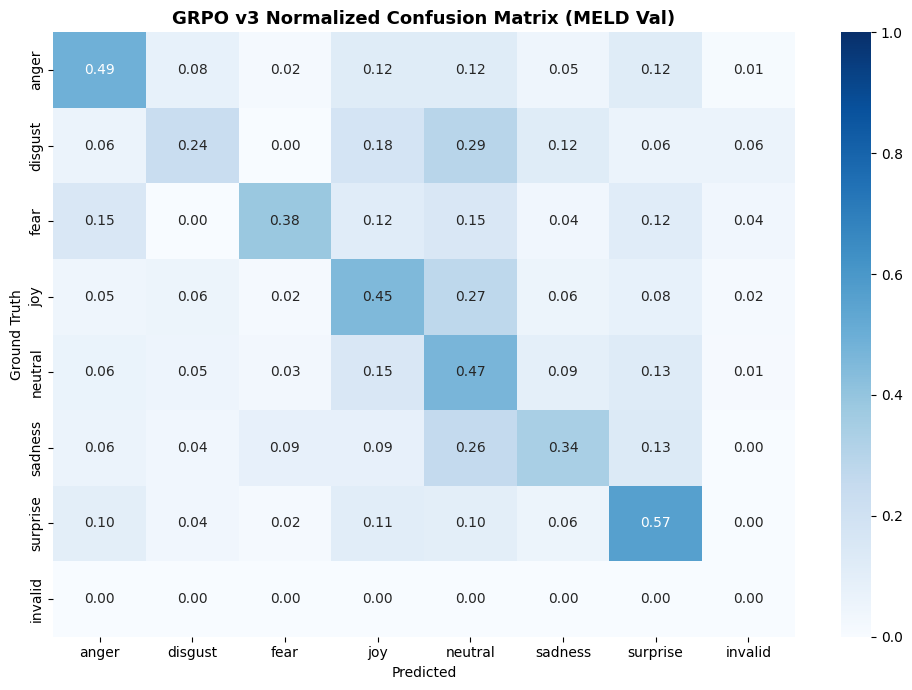

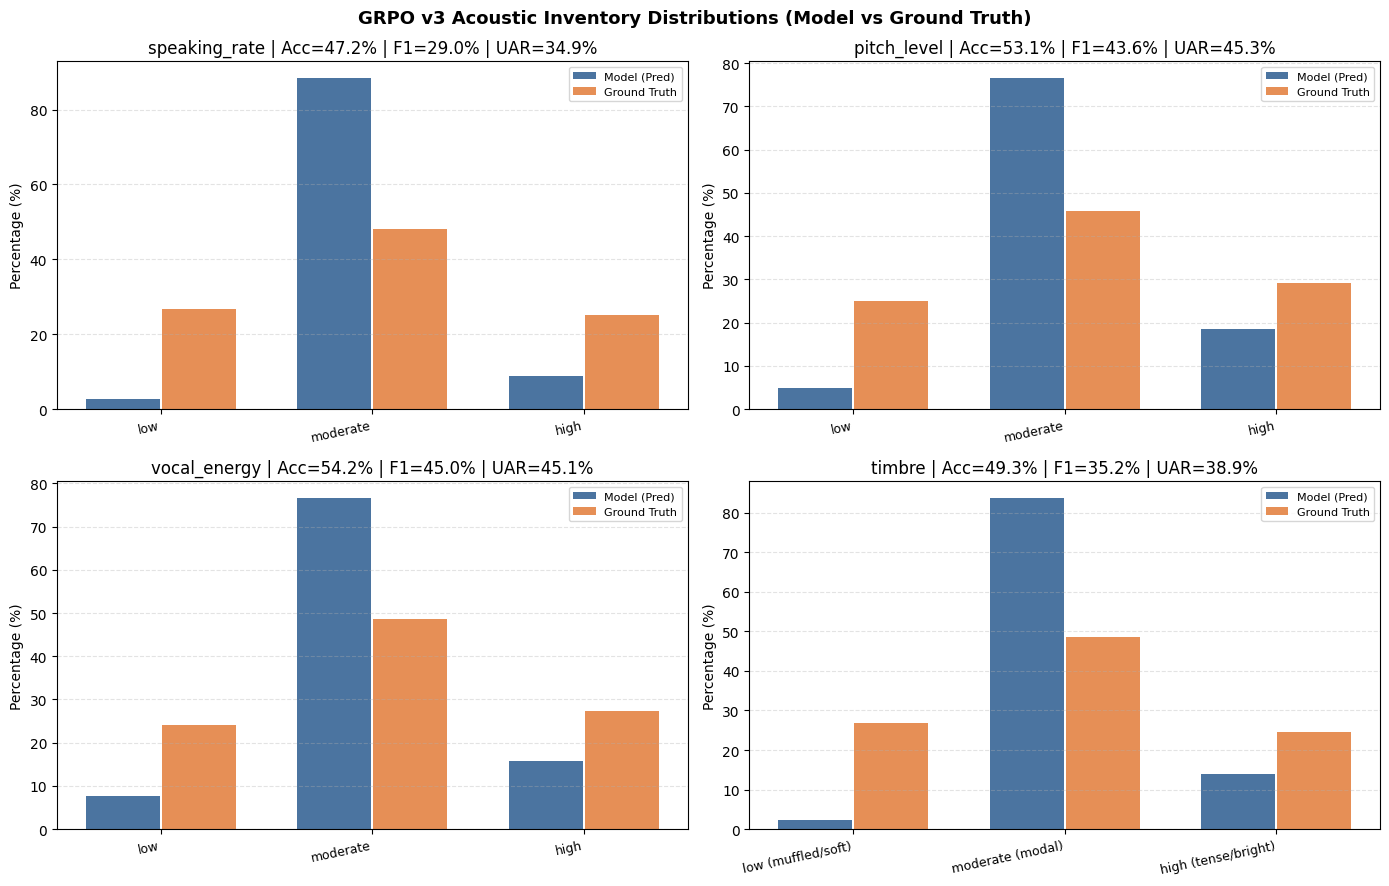

{'emotion': {'n': 816,
  'accuracy': 0.46078431372549017,
  'macro_f1': 0.39343649308825424,
  'weighted_f1': 0.47551649094665843,
  'macro_recall': 0.41959558773100153,
  'invalid_rate': 0.012254901960784314,
  'per_class': {'anger': {'precision': 0.5242718446601942,
    'recall': 0.4909090909090909,
    'f1': 0.5070422535211268,
    'support': 110},
   'disgust': {'precision': 0.08695652173913043,
    'recall': 0.23529411764705882,
    'f1': 0.12698412698412698,
    'support': 17},
   'fear': {'precision': 0.30303030303030304,
    'recall': 0.38461538461538464,
    'f1': 0.3389830508474576,
    'support': 26},
   'joy': {'precision': 0.3783783783783784,
    'recall': 0.45161290322580644,
    'f1': 0.4117647058823529,
    'support': 124},
   'neutral': {'precision': 0.6507936507936508,
    'recall': 0.4672364672364672,
    'f1': 0.5439469320066335,
    'support': 351},
   'sadness': {'precision': 0.34146341463414637,
    'recall': 0.34146341463414637,
    'f1': 0.34146341463414637,
  

Saved training curves to: /content/drive/MyDrive/AGORA_SER/runs/ser_grpo/grpo_v3_hybrid_invfreq_4cue_seed42_v4_noR2/grpo_training_curves.png


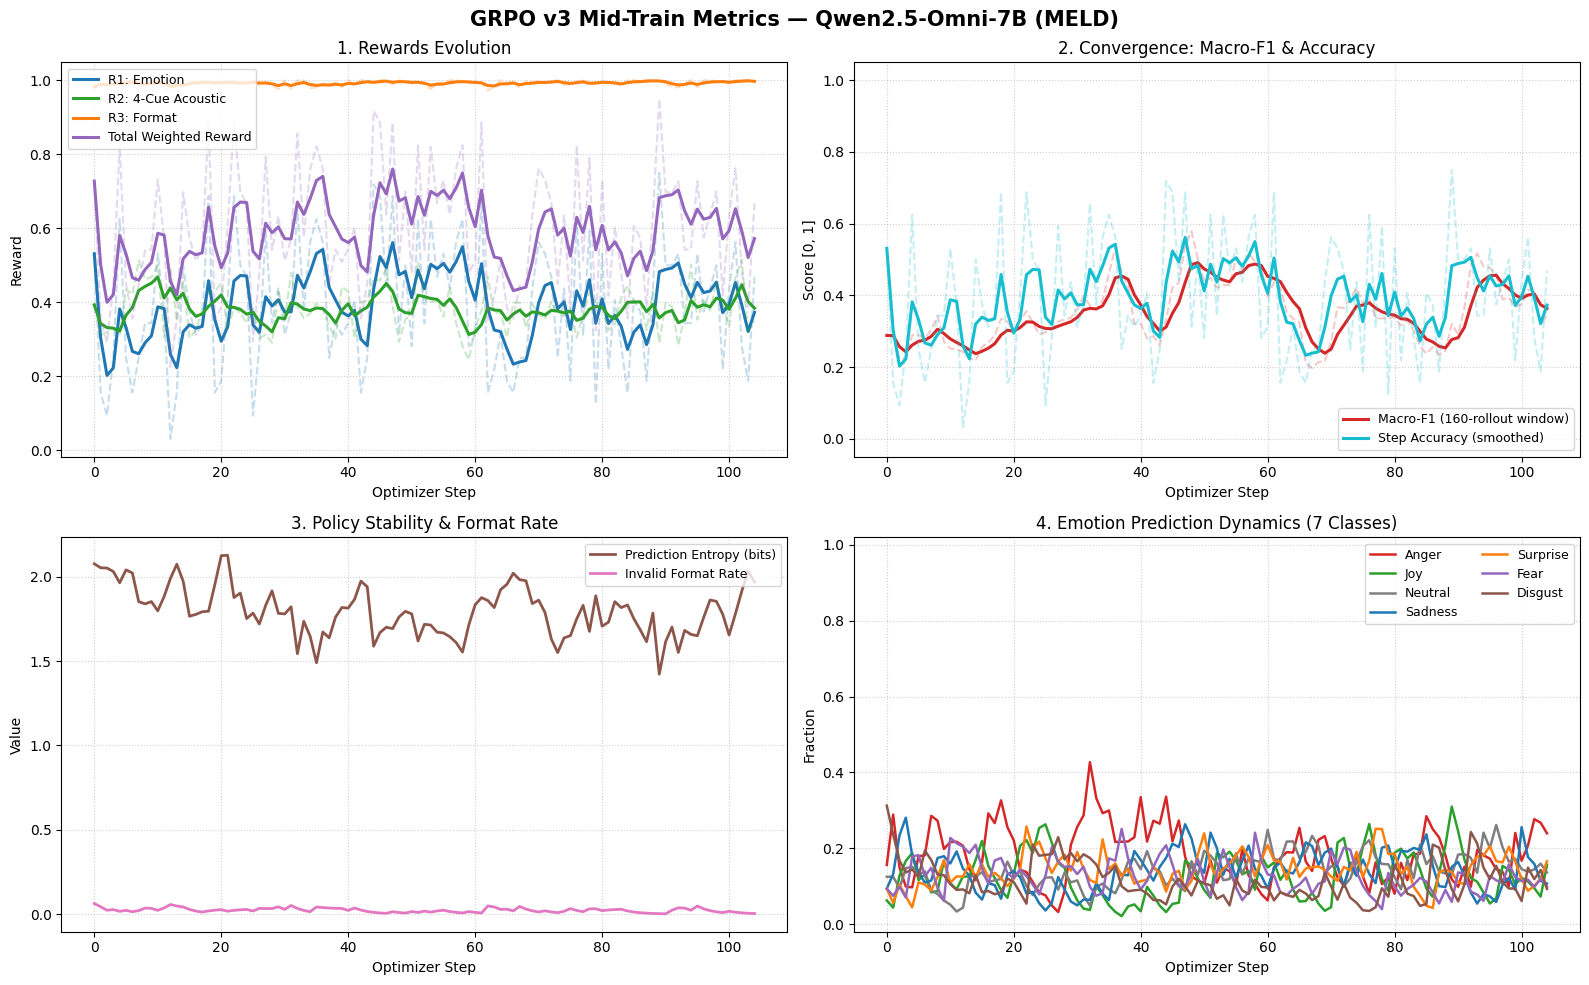

GRPO CSV: /content/drive/MyDrive/AGORA_SER/data/sft_grpo_gender_wxrate_60_40_v4/grpo_train.csv
Final adapter: /content/drive/MyDrive/AGORA_SER/runs/ser_grpo/grpo_v3_hybrid_invfreq_4cue_seed42_v4_noR2/final_grpo_adapter
Reports: /content/drive/MyDrive/AGORA_SER/runs/ser_grpo/grpo_v3_hybrid_invfreq_4cue_seed42_v4_noR2


In [19]:
unwrapped_model = trainer.accelerator.unwrap_model(trainer.model)
after_predictions, after_metrics = evaluate_grpo_validation(
    unwrapped_model, processor, val_set,
    stage='after', output_dir=OUTPUT_DIR, adapter_dir=FINAL_ADAPTER_DIR,
    trainer_obj=trainer, batch_size=EVAL_BATCH_SIZE, plot=True,
)
display(after_metrics)
plot_grpo_training_curves(trainer.state.log_history, save_path=OUTPUT_DIR / 'grpo_training_curves.png')
os.sync()
print(f'GRPO CSV: {GRPO_CSV}\nFinal adapter: {FINAL_ADAPTER_DIR}\nReports: {OUTPUT_DIR}')

## 10. Colab runtime release

In [20]:
if IS_COLAB:
    import time
    os.sync()
    time.sleep(10)
    from google.colab import runtime
    runtime.unassign()